# 04 — Supervised learning, tuning and metrics

This notebook builds the h=24 net-load forecaster. It climbs a model ladder from OLS to gradient boosting, tunes the whole pipeline in two stages, and scores the champion once on the untouched holdout. It then runs the evaluation deliverables (ablation, hyperparameter sensitivity, learning curves, failure analysis), a curtailment classifier, a statistical comparison of the models, and the verdict on the five predictions from notebook 01. It also measures a leak in the rolling features, now fixed in `src/features.py`, so its cost is a number.

**Inputs:** `panel.parquet` · `results.json:nb01,nb02` · `results.json:nb04.baselines`

**Outputs:** ledger block `nb04`; `best_params.json`, `holdout_predictions_by_horizon.parquet`, the OLS tables in `data/processed/linear/`; nineteen figures (`04_*.png`).


### 4.1 — Setup, and the holdout split off first

Load the panel sorted `(time, zone)` and split off the last 15% of the timeline as the holdout before anything else. No tuning or model selection fits on `hold`; it is only scored. (The one exception is §4.15b, whose later rolling origins train on earlier holdout months.) The sort order matters: on a `(zone, time)` sort a positional cut would put one zone's June beside another zone's January, so positional folds would not be chronological.

**How to read the output:** each fold's training window ends before its validation window, with a gap of `168 + h − 1` hours (`cfg.cv_gap_for`).


In [1]:
import sys, json, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as cfg
from src import results as R
from src import features as P
from src import evaluation as E

pd.set_option("display.width", 150, "display.max_columns", 60)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI
np.random.seed(cfg.SEED)

# A white pad behind text labels, so a number never prints across a reference line.
_WB = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9)

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor

TIME, GROUP, TARGET = cfg.TIME_COL, cfg.GROUP_COL, cfg.TARGET

# TIME-MAJOR SORT, and it is not cosmetic. On a panel sorted (zone, timestamp) a
# positional cut lands inside one zone's history and produces a "validation" fold
# holding zone A's June next to zone B's January. Sorted (timestamp, zone) every
# positional block is a block of TIME containing all six zones, so a positional
# split IS a chronological split.
df = pd.read_parquet(cfg.PANEL).sort_values([TIME, GROUP]).reset_index(drop=True)
assert df[TIME].is_monotonic_increasing, "the panel must be time-major before splitting"

# ---------------------------------------------------------------------------
# THE HELD-OUT BLOCK, SPLIT FIRST AND PHYSICALLY
# ---------------------------------------------------------------------------
# Split before anything else is computed. Not because remembering would be hard, but
# because "I remembered not to look" is unfalsifiable and `hold` never entering a fit
# is checkable. No tuning or selection cell fits on anything but `dev`;
# `hold` is only scored (4.3, 4.4, 4.8 onward), except 4.15b's rolling origins, which
# refit past it on purpose.
CUT = cfg.HOLDOUT_CUT
dev = df[df[TIME] <= CUT].reset_index(drop=True)
hold = df[df[TIME] > CUT].reset_index(drop=True)
y_dev, y_hold = dev[TARGET], hold[TARGET]

# THE PRIMARY HORIZON IS 24, and the choice has a reason beyond convenience. It is
# the day-ahead operational horizon reserve is procured against, and it is the only
# horizon at which the external benchmark in 4.3 -- EIA's published day-ahead demand
# forecast -- is an information-set match. The full two-stage search runs here;
# 4.6b re-tunes a champion for h=1, 48 and 72 (randomised stage only), and 4.9 scores
# every horizon with its own champion.
HORIZON = 24
LAGS = cfg.lags_for(HORIZON)
GAP = cfg.cv_gap_for(HORIZON)
cv = P.make_ts_cv(n_splits=cfg.N_SPLITS, gap=GAP)

print(f"panel            {len(df):>7,} rows · {df[TIME].min():%Y-%m-%d} -> {df[TIME].max():%Y-%m-%d}")
print(f"dev  (tune here) {len(dev):>7,} rows · up to   {CUT:%Y-%m-%d %H:%M}")
print(f"hold (score once){len(hold):>7,} rows · from   {hold[TIME].min():%Y-%m-%d}")
print(f"\nhorizon h={HORIZON}  lags={LAGS}  CV: {cfg.N_SPLITS} expanding folds, gap={GAP}h")
print(f"  gap = max(roll)={max(cfg.ROLL_WINDOWS)} + h-1={HORIZON - 1}  (see cfg.cv_gap_for)")
for i, (tr, va) in enumerate(cv.split(dev), 1):
    print(f"   fold {i}: train {len(tr):>6,} rows to {dev[TIME].iloc[tr].max():%Y-%m-%d}"
          f" | validate {len(va):>6,} rows from {dev[TIME].iloc[va].min():%Y-%m-%d}")

# THE HOLDOUT HAS NO JANUARY, and it is quoted here rather than discovered in 4.7.
_hm = sorted(hold[TIME].dt.month.unique())
print(f"\nholdout covers months {_hm} — NO JANUARY. Notebook 00 measured the holdout as "
      f"2.16 C warmer\nthan dev, of which 1.16 C is the missing winter alone. Every "
      f"holdout number below is\ntherefore a warm-season number, and 4.8 reports it by "
      f"season for that reason.")

R.save("nb04", {
    "horizon_primary": HORIZON, "lags": list(LAGS), "cv_gap_hours": GAP,
    "n_splits": cfg.N_SPLITS,
    "cut": f"{CUT:%Y-%m-%d %H:%M}",
    "n_dev": int(len(dev)), "n_hold": int(len(hold)),
    "holdout_months": [int(m) for m in _hm],
});

panel            315,485 rows · 2019-01-01 -> 2024-12-31
dev  (tune here) 268,186 rows · up to   2024-02-06 23:00
hold (score once) 47,299 rows · from   2024-02-07

horizon h=24  lags=(24, 25, 26, 48, 168)  CV: 5 expanding folds, gap=191h
  gap = max(roll)=168 + h-1=23  (see cfg.cv_gap_for)
   fold 1: train 44,697 rows to 2019-11-07 | validate 43,566 rows from 2019-11-15
   fold 2: train 89,409 rows to 2020-09-12 | validate 43,561 rows from 2020-09-20
   fold 3: train 134,116 rows to 2021-07-20 | validate 43,530 rows from 2021-07-28
   fold 4: train 178,792 rows to 2022-05-26 | validate 43,566 rows from 2022-06-03
   fold 5: train 223,504 rows to 2023-04-02 | validate 43,536 rows from 2023-04-10

holdout covers months [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] — NO JANUARY. Notebook 00 measured the holdout as 2.16 C warmer
than dev, of which 1.16 C is the missing winter alone. Every holdout number below is
therefore a warm-season number, and 4.8 reports it by season for that reason.


### 4.2 — A leak in the rolling features, and what it cost

The rolling-window features used to end at `t−1`. That is correct at h=1, but at h=24 it hands the model 23 hours after the forecast origin that an operator does not have yet. This cell runs the old rule as a control arm (`roll_ends_at_origin=False`) against the corrected one at all four horizons. The control arm never ships a result.

**How to read the output:** in panel (a) the leaked curve should be nearly flat and the admissible one should rise with the horizon. Panel (b) must be zero at h=1, which is why notebook 02's conclusions stand.


one row of CISO, h=24, showing what the two definitions cover:
   admissible  roll24_mean =  16,504.8   window [t-47, t-24], ends at the origin
   leaked      roll24_mean =  18,810.3   window [t-24, t-1],  ends 23h after it



CV MAE, dev block, same folds:
         admissible  leaked  optimism_mw  optimism_pct
horizon                                               
1             538.8   538.8          0.0           0.0
24           2173.2  1874.8        298.4          13.7
48           2482.5  1885.4        597.1          24.1
72           2615.1  1890.1        725.1          27.7


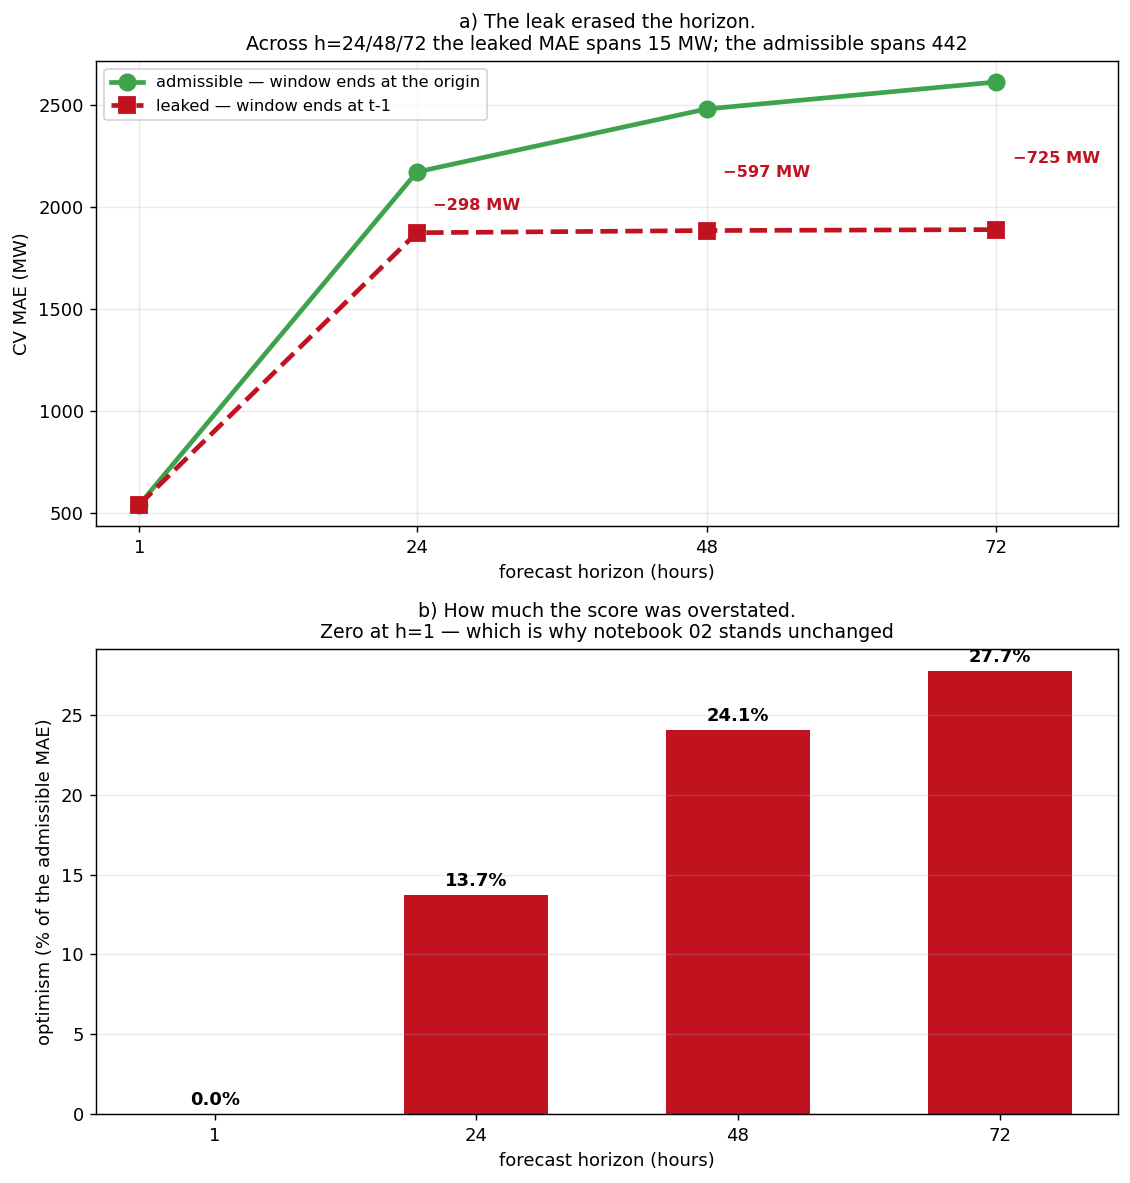


At h=1 the two arms agree to 0.0000 MW. The fix is a
no-op at h=1, so every notebook 02 decision -- encoding, PerZoneRelative, k='all' --
was made on unaffected numbers and none of them is revisited.


In [2]:
# WHAT: measure what the rolling-window leak was worth, at each horizon, by running
#       the broken arm on purpose against the fixed one.
# WHY:  notebook 04 is the first notebook to run h > 1, and the defect only exists at h > 1.
#       Reporting "we found and fixed a bug" is worth nothing without the number;
#       reporting the number is what makes it a result. It also decides whether any
#       Notebook 02 conclusion has to be revisited -- the answer is no, and this is the
#       evidence for that rather than the hope.
# NOTE: `roll_ends_at_origin=False` is a CONTROL ARM. It exists so this cell can run
#       and must never produce a shipped number. See GroupLagFeatures.__init__.

# THE DEFECT. `rolling(W, closed='left')` gives the W hours ending at t-1. At h=1 that
# is exactly right: an operator standing at origin t-1 does know net load at t-1. At
# h=24 it hands the model net load at t-1 ... t-23 -- twenty-three hours that have not
# happened yet at an origin of t-24. `src/config.py` carried a comment admitting this
# since notebook 01 and nothing had run at h > 1 to expose it. The leakage test passed
# throughout, because it asserted the window excludes hour t, which it always did.
_demo = df[df[GROUP] == "CISO"].tail(3000)
_ok = P.GroupLagFeatures(lags=cfg.lags_for(24), roll_windows=(24,)).fit(_demo).transform(_demo)
_bad = P.GroupLagFeatures(lags=cfg.lags_for(24), roll_windows=(24,),
                          roll_ends_at_origin=False).fit(_demo).transform(_demo)
_t = _ok[TIME].iloc[-1]
print("one row of CISO, h=24, showing what the two definitions cover:")
print(f"   admissible  roll24_mean = {_ok[TARGET + '_roll24_mean'].iloc[-1]:9,.1f}   "
      f"window [t-47, t-24], ends at the origin")
print(f"   leaked      roll24_mean = {_bad[TARGET + '_roll24_mean'].iloc[-1]:9,.1f}   "
      f"window [t-24, t-1],  ends 23h after it")

# THE COST, measured under the same CV as everything else.
leak_rows = []
for h in cfg.HORIZONS:
    lg, gp = cfg.lags_for(h), cfg.cv_gap_for(h)
    cvh = P.make_ts_cv(n_splits=cfg.N_SPLITS, gap=gp)
    arm = {}
    for correct in (True, False):
        pipe = P.make_supervised_pipeline(
            cfg.NUMERIC_FEATURES, lags=lg, roll_ends_at_origin=correct,
            model=HistGradientBoostingRegressor(random_state=cfg.SEED))
        arm[correct] = float(-cross_val_score(pipe, dev, y_dev, cv=cvh, n_jobs=cfg.N_JOBS,
                                              scoring="neg_mean_absolute_error").mean())
    leak_rows.append({"horizon": h, "admissible": arm[True], "leaked": arm[False],
                      "optimism_mw": arm[True] - arm[False],
                      "optimism_pct": (arm[True] - arm[False]) / arm[True] * 100})
leak = pd.DataFrame(leak_rows).set_index("horizon")
print("\nCV MAE, dev block, same folds:")
print(leak.round(1).to_string())

fig, axes = plt.subplots(2, 1, figsize=(8.8, 9.2))
ax = axes[0]
ax.plot(leak.index, leak["admissible"], "o-", lw=2.6, ms=9, color="#3fa34d",
        label="admissible — window ends at the origin")
ax.plot(leak.index, leak["leaked"], "s--", lw=2.6, ms=9, color="#c1121f",
        label="leaked — window ends at t-1")
for h in leak.index:
    if leak.loc[h, "optimism_mw"] > 1:
        ax.annotate(f"−{leak.loc[h, 'optimism_mw']:,.0f} MW",
                    (h, (leak.loc[h, "admissible"] + leak.loc[h, "leaked"]) / 2),
                    xytext=(9, -4), textcoords="offset points", fontsize=9,
                    color="#c1121f", fontweight="bold")
ax.set_xticks(list(cfg.HORIZONS))
# ROOM FOR THE LAST ANNOTATION. The h=72 delta is offset nine points right of a
# point sitting on the axis limit, so it rendered outside the frame and survived
# only because bbox_inches="tight" expands the canvas.
ax.set_xlim(right=max(cfg.HORIZONS) * 1.14)
ax.set_xlabel("forecast horizon (hours)"); ax.set_ylabel("CV MAE (MW)")
# Stated precisely rather than impressionistically: the leaked curve is NOT flat from
# h=1 (where the leak cannot operate, so the two arms coincide). It is flat across the
# three horizons where the leak does operate, and that is the damning comparison.
_leaked_long = leak.loc[[h for h in leak.index if h > 1], "leaked"]
_adm_long = leak.loc[[h for h in leak.index if h > 1], "admissible"]
ax.set_title(f"a) The leak erased the horizon.\n"
             f"Across h=24/48/72 the leaked MAE spans {_leaked_long.max()-_leaked_long.min():,.0f} MW; "
             f"the admissible spans {_adm_long.max()-_adm_long.min():,.0f}", fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
ax.bar([str(h) for h in leak.index], leak["optimism_pct"], 0.55, color="#c1121f")
for i, h in enumerate(leak.index):
    ax.annotate(f"{leak.loc[h, 'optimism_pct']:.1f}%", (i, leak.loc[h, "optimism_pct"]),
                xytext=(0, 5), textcoords="offset points", ha="center",
                fontsize=10, fontweight="bold")
ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("optimism (% of the admissible MAE)")
ax.set_title("b) How much the score was overstated.\n"
             "Zero at h=1 — which is why notebook 02 stands unchanged", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_leak_cost.png", bbox_inches="tight")
plt.show()

print(f"\nAt h=1 the two arms agree to {abs(leak.loc[1, 'optimism_mw']):.4f} MW. The fix is a")
print("no-op at h=1, so every notebook 02 decision -- encoding, PerZoneRelative, k='all' --")
print("was made on unaffected numbers and none of them is revisited.")

R.save("nb04", {"rolling_leak": {
    "by_horizon": {str(h): {k: float(v) for k, v in leak.loc[h].items()} for h in leak.index},
    # Spreads over h > 1 ONLY. Including h=1 — where the two arms are identical by
    # construction — would let the h=1 point dominate both numbers and hide the point,
    # which is that the leaked arm barely distinguishes 24h from 72h.
    "leaked_mae_spread_mw_h_over_1": float(_leaked_long.max() - _leaked_long.min()),
    "admissible_mae_spread_mw_h_over_1": float(_adm_long.max() - _adm_long.min()),
    "leaked_mae_spread_mw_all": float(leak["leaked"].max() - leak["leaked"].min()),
    "admissible_mae_spread_mw_all": float(leak["admissible"].max() - leak["admissible"].min()),
}});

**What this shows:** CV MAE on the dev block (the same five folds) at each horizon, with rolling windows ending at the origin (admissible) or at `t−1` (leaked).

**What I see:** At h=1 both are **538.8 MW** (optimism 0.0). Then h=24 **2,173.2 vs 1,874.8** (298.4 MW, 13.7%), h=48 **2,482.5 vs 1,885.4** (597.1 MW, 24.1%), h=72 **2,615.1 vs 1,890.1** (725.1 MW, 27.7%). From h=24 to h=72 the admissible model degrades by **442.0 MW**, the leaked one by only **15.3 MW**.

**What it means:** The leak does more than inflate accuracy: it erases the horizon effect. The further ahead the model forecasts, the more of the answer the leaked window contains, so its error barely moves.

**What I do:** `roll_ends_at_origin=True` is the default, with the shift derived from the horizon. `tests/test_leakage.py` pins it at every horizon and pins the h=1 identity. Every number below uses the corrected windows.


### 4.3 — Baselines, and a correction to goal G2

Two baselines: seasonal naive at t−168 (the weekly lag keeps the day of week) and a benchmark built from EIA's day-ahead forecast. Goal G2 said "beat EIA's day-ahead forecast `DF`", but `DF` forecasts **demand**, the target here is **net load** = demand − wind − solar, and EIA publishes no net-load forecast. So I build the forecast a public-data operator would hold at a 24-hour origin:

`DF_composite(t) = demand_forecast(t) − wind(t−24) − solar(t−24)`

The cell also scores `DF` on its own target, so the benchmark is not a strawman, and splits the composite's error into its two legs.

**How to read the output:** the composite should clearly beat seasonal naive.


In [3]:
# WHAT: the two baselines every later model is quoted against — seasonal naive at
#       t-168, and a benchmark built from EIA's published day-ahead forecast.
# WHY:  a MAE alone is uninterpretable. Beating seasonal-naive is the floor; beating
#       an operational forecast a real system operator publishes is the claim the
#       goal G2 makes.
# NOTE: G2 as originally written is not directly runnable, and this cell
#       says why and what replaces it. That correction is the point of the section.

# ---------------------------------------------------------------------------
# Baseline 1 — seasonal naive
# ---------------------------------------------------------------------------
# t-168, not t-24: the weekly lag preserves the day of week, so Monday is predicted
# from Monday. A t-24 naive predicts Saturday from Friday and loses to t-168 for a
# reason that has nothing to do with modelling skill.
# Every benchmark lag is looked up by TIMESTAMP, like the model's own lags: the panel has
# holes, and a row shift across a 25-hour gap would reach 192 hours back.
from src import models as BL
bl = hold.sort_values([GROUP, TIME]).copy()
bl["naive168"] = BL.lag_by_time(bl, TARGET, 168)

# ---------------------------------------------------------------------------
# Baseline 2 — the EIA benchmark, and the problem with it
# ---------------------------------------------------------------------------
# THE PROBLEM. `demand_forecast` (EIA-930 field DF) is a day-ahead forecast of
# DEMAND. The target here is NET LOAD = demand - wind - solar. They are not the same
# quantity and are not comparable: over this holdout, demand averages ~35 GW where
# net load averages ~26 GW. Goal G2 says "beat the published EIA day-ahead
# forecast (DF), skill > 0" and reads as though DF were a net-load forecast. It is
# not, and EIA publishes no net-load forecast at all.
#
# THE FIX, and why it is fair rather than convenient. Build the forecast an operator
# with only public data would actually hold at a 24-hour origin:
#
#     DF_composite(t) = demand_forecast(t) - wind(t-24) - solar(t-24)
#
# EIA's own demand forecast, plus 24-hour persistence for the two renewables, because
# that is the best a public-data operator can do for them. This is a STRONGER
# benchmark than seasonal naive and a genuinely hard one: it contains a professional
# forecast of the largest term. Persistence for wind and solar is the weak link, and
# the decomposition below measures exactly how weak, so the benchmark cannot be
# accused of being a strawman without looking at the number.
bl["wind_p24"] = BL.lag_by_time(bl, "wind", 24)
bl["solar_p24"] = BL.lag_by_time(bl, "solar", 24)
bl["df_composite"] = bl["demand_forecast"] - bl["wind_p24"] - bl["solar_p24"]

# Score every baseline on the SAME rows: whichever rows all of them can predict.
# Scoring each on its own available subset would compare models on different data.
common = (bl["naive168"].notna() & bl["df_composite"].notna()
          & bl[TARGET].notna() & bl["demand_forecast"].notna())
bl_c = bl[common].copy()
print(f"baselines scored on {len(bl_c):,} of {len(bl):,} holdout rows "
      f"({len(bl_c)/len(bl):.1%}) — the rows every baseline can reach")

base = {}
for name, col in [("seasonal naive t-168", "naive168"),
                  ("EIA DF composite", "df_composite")]:
    base[name] = float(mean_absolute_error(bl_c[TARGET], bl_c[col]))

# Is DF itself any good? If EIA's demand forecast were poor, beating the composite
# would prove nothing. Scored on its OWN target, demand, where it is a like-for-like
# forecast rather than a construction.
df_on_demand = float(mean_absolute_error(bl_c["demand"], bl_c["demand_forecast"]))
# demand one week earlier, looked up on the whole holdout block and then restricted to the
# common rows (every common row has it: its net load one week earlier exists)
demand_naive = float(mean_absolute_error(
    bl_c["demand"], BL.lag_by_time(bl, "demand", 168).loc[bl_c.index]))

# Where does the composite's error come from? Decompose it into the demand-forecast
# term and the renewables-persistence term, each measured alone.
err_demand_leg = float(np.abs(bl_c["demand_forecast"] - bl_c["demand"]).mean())
err_renew_leg = float(np.abs((bl_c["wind_p24"] + bl_c["solar_p24"])
                             - (bl_c["wind"] + bl_c["solar"])).mean())

print(f"\nEIA's demand forecast, judged on DEMAND (its own target):")
print(f"   MAE {df_on_demand:8,.1f} MW   vs a seasonal-naive demand forecast at "
      f"{demand_naive:,.1f} MW  (skill {E.skill_score(df_on_demand, demand_naive):+.1%})")
print(f"   -> DF is a good forecast. The composite is not a strawman.")
print(f"\nwhere the composite's error comes from:")
print(f"   demand-forecast leg      {err_demand_leg:8,.1f} MW")
print(f"   renewables-persistence leg {err_renew_leg:8,.1f} MW"
      f"   <- the weak link, and it is public data's limit, not EIA's")
print(f"\nBASELINES on net load, {len(bl_c):,} common holdout rows:")
for k, v in base.items():
    print(f"   {k:22s} MAE {v:8,.1f} MW")
print(f"   the EIA composite is {base['seasonal naive t-168'] / base['EIA DF composite']:.2f}x "
      f"better than seasonal naive — the bar that matters is the second one")

R.save("nb04", {"baselines": {
    "naive168_mae": base["seasonal naive t-168"],
    "df_composite_mae": base["EIA DF composite"],
    "df_on_demand_mae": df_on_demand,
    "df_on_demand_skill_vs_naive": E.skill_score(df_on_demand, demand_naive),
    "composite_demand_leg_mae": err_demand_leg,
    "composite_renewables_leg_mae": err_renew_leg,
    "n_scored": int(len(bl_c)),
    "g2_note": ("EIA publishes a day-ahead DEMAND forecast, not a net-load forecast. "
                "G2 is evaluated against DF minus 24h persistence of wind and solar, "
                "which is the best a public-data operator holds at a 24h origin."),
}});

# ---------------------------------------------------------------------------
# Baseline 3 — DF_composite_v2, the benchmark rebuilt to be HARD
# ---------------------------------------------------------------------------
# WHY A THIRD BASELINE. The decomposition printed above is an admission: of the
# composite's error, the renewables-persistence leg contributes the overwhelming
# majority, and that leg is OURS. EIA publishes no net-load forecast, so the
# renewables leg had to be invented, and the weakest available one was. Beating it
# shows that public data handed over trivially is beatable. It says less than the
# headline skill number sounds like it says.
#
# v2 improves the BENCHMARK rather than the model:
#
#     DF_composite_v2(t) = demand_forecast(t) - wind_hat(t) - solar_hat(t)
#
# where each leg is whichever of {24h persistence, per-zone weather regression}
# scores better ON A VALIDATION SLICE OF DEV. The selection is the diligence: an
# operator with public data would try both and keep the winner, and doing that
# choice on dev rather than on the holdout is what keeps the benchmark from being a
# function of the block the claim is scored against.
from src import models as BL

VALID_DAYS = 90
# Legs fitted with the validation slice held OUT, so the weather arm is judged on
# rows it has not seen. Judging it on its own training rows would pick it every
# time by memory rather than by skill.
coefs_sel = BL.fit_renewable_legs(dev, valid_days=VALID_DAYS)
chosen = BL.select_leg_methods(dev, coefs_sel, valid_days=VALID_DAYS)
print(f"\n--- leg selection, on dev {chosen['valid_from'][:10]} -> "
      f"{chosen['valid_to'][:10]} ({chosen['valid_rows']:,} rows) ---")
for kind, info in chosen["legs"].items():
    v = info["validation_mae"]
    print(f"   {kind:6s} persistence {v['persistence']:8,.1f} MW | "
          f"weather {v['weather']:8,.1f} MW  ->  CHOSEN: {info['method']}")

# The shipped legs are refitted on the full dev window, now that the method is fixed.
coefs = BL.fit_renewable_legs(dev)
v2 = BL.composite_v2_selected(bl, coefs, chosen)
bl["df_composite_v2"] = v2["df_composite_v2"]
bl["wind_leg"], bl["solar_leg"] = v2["wind_leg"], v2["solar_leg"]

common2 = common & bl["df_composite_v2"].notna()
bl_c2 = bl[common2]
base["EIA DF composite v2"] = float(mean_absolute_error(bl_c2[TARGET],
                                                        bl_c2["df_composite_v2"]))
# Re-score v1 and naive on the SAME rows as v2, or the three are not comparable.
base_common = {
    "seasonal naive t-168": float(mean_absolute_error(bl_c2[TARGET], bl_c2["naive168"])),
    "EIA DF composite": float(mean_absolute_error(bl_c2[TARGET], bl_c2["df_composite"])),
    "EIA DF composite v2": base["EIA DF composite v2"],
}
leg_err = BL.leg_errors(bl_c2, coefs)

print(f"\n--- the renewables leg, on the {len(bl_c2):,} common holdout rows ---")
print(f"   wind   persistence {leg_err['wind_persistence_mae']:8,.1f} MW   "
      f"weather {leg_err['wind_weather_mae']:8,.1f} MW")
print(f"   solar  persistence {leg_err['solar_persistence_mae']:8,.1f} MW   "
      f"weather {leg_err['solar_weather_mae']:8,.1f} MW")

print(f"\nTHREE BASELINES, all on the same {len(bl_c2):,} rows:")
for k in ("seasonal naive t-168", "EIA DF composite", "EIA DF composite v2"):
    print(f"   {k:24s} MAE {base_common[k]:8,.1f} MW")
print(f"   v2 is {base_common['EIA DF composite'] - base_common['EIA DF composite v2']:,.1f} MW "
      f"harder than v1 "
      f"({1 - base_common['EIA DF composite v2']/base_common['EIA DF composite']:.1%} lower error)")

R.save("nb04", {"baselines_v2": {
    "df_composite_v2_mae": base_common["EIA DF composite v2"],
    "naive168_mae_common_v2_rows": base_common["seasonal naive t-168"],
    "df_composite_v1_mae_common_v2_rows": base_common["EIA DF composite"],
    "n_scored": int(len(bl_c2)),
    "leg_selection": chosen,
    "leg_errors_holdout": leg_err,
    "leg_fit_window": {"from": coefs["fit_from"], "to": coefs["fit_to"],
                       "rows": coefs["fit_rows"]},
    "hardening_mw": float(base_common["EIA DF composite"]
                          - base_common["EIA DF composite v2"]),
}});


baselines scored on 46,123 of 47,299 holdout rows (97.5%) — the rows every baseline can reach

EIA's demand forecast, judged on DEMAND (its own target):
   MAE  1,048.5 MW   vs a seasonal-naive demand forecast at 2,656.5 MW  (skill +60.5%)
   -> DF is a good forecast. The composite is not a strawman.

where the composite's error comes from:
   demand-forecast leg       1,048.5 MW
   renewables-persistence leg  2,769.7 MW   <- the weak link, and it is public data's limit, not EIA's

BASELINES on net load, 46,123 common holdout rows:
   seasonal naive t-168   MAE  4,259.8 MW
   EIA DF composite       MAE  3,059.2 MW
   the EIA composite is 1.39x better than seasonal naive — the bar that matters is the second one

--- leg selection, on dev 2023-11-09 -> 2024-02-06 (12,954 rows) ---
   wind   persistence  3,277.7 MW | weather  2,226.0 MW  ->  CHOSEN: weather
   solar  persistence    313.8 MW | weather    537.4 MW  ->  CHOSEN: persistence



--- the renewables leg, on the 46,123 common holdout rows ---
   wind   persistence  2,789.2 MW   weather  2,183.1 MW
   solar  persistence    345.8 MW   weather    953.3 MW

THREE BASELINES, all on the same 46,123 rows:
   seasonal naive t-168     MAE  4,259.8 MW
   EIA DF composite         MAE  3,059.2 MW
   EIA DF composite v2      MAE  2,485.9 MW
   v2 is 573.3 MW harder than v1 (18.7% lower error)


### 4.3b — A stronger benchmark: `DF_composite_v2`

The composite's error is dominated by its renewables-persistence leg (2,769.7 MW, against 1,048.5 MW for the demand leg), and that leg is mine, not EIA's. `DF_composite_v2` makes the benchmark harder: each renewables leg is either 24-hour persistence or a per-zone weather regression, whichever wins on a validation slice of dev (never the holdout). The legs see ERA5 reanalysis (perfect weather foresight) and are refitted on the most recent year of dev; both choices favour the benchmark.

Weather wins for **wind**; persistence wins for **solar**. The reason is capacity growth: solar fleets grew fast between dev and the holdout, and t−24 persistence carries the current installed capacity for free, while a regression fitted on history predicts last year's fleet. A weather-scaled persistence leg was also tried and lost to plain persistence. v2 scores 2,485.9 MW against v1's 3,059.2 MW, so skill against it is smaller and means more.


### 4.4 — Linear regression and its assumptions

OLS on the same 66-feature design matrix the tree models get: the coefficient table, R², the F-test, AIC/BIC, and a test of each of the five classical assumptions (linearity, independence, homoscedasticity, normality, no multicollinearity). It comes first because it is the only model whose coefficients can be read, and each later rung answers a failure found here:

| rung | fixes | gives up |
|---|---|---|
| OLS | — | needs all five assumptions |
| OLS + HAC / HC3 errors | inference under autocorrelation and heteroscedasticity | nothing; same coefficients |
| Ridge | coefficient variance under collinearity | valid *t*-tests |
| Random forest / boosting | non-linearity and interactions | interpretability |

Three traps are handled in the cell. One zone dummy is dropped as the reference level, because all six plus an intercept is exactly singular. Durbin–Watson is computed within zone, because adjacent rows of a `(timestamp, zone)` panel are different zones. And R² is also reported within zone, because the headline 0.971 is mostly "which zone is this row?".

**How to read the output:** the coefficient table, then the assumption block, then panels (a)–(f). Panel (e) shows how far autocorrelation inflated each *t*-statistic.


design matrix: 268,186 rows x 66 features (the same features the tree models receive)
   zone dummy dropped as the reference level: ['zone_is_BPAT']
   THE DUMMY VARIABLE TRAP. The pipeline one-hot encodes all six zones, which
   costs a tree nothing. Add an intercept and the design is EXACTLY singular --
   the six dummies sum to the constant column. statsmodels does not crash; it
   falls back to a pseudo-inverse and returns coefficients that are not uniquely
   identified. Dropping one dummy removes that identity, but exact identities among
   the lag features remain, so the condition number printed below stays very large.
   The five surviving dummies read as contrasts against the omitted zone, which is
   what a zone fixed effect actually means.



OLS on 268,186 observations, 64 model degrees of freedom (design rank - 1)
   R-squared          0.9710
   adjusted R-squared 0.9710   <- the one to quote on a wide design
   R-squared WITHIN zone 0.8282   <- the one that is not inflated
      83.1% of the total variance is simply 'which zone is this row?'. A model
      knowing nothing but the zone dummies would already score high on the
      headline number; the within version removes that free variance and asks
      how much of a zone's OWN hour-to-hour variation is explained.
   residual s.e.      3,462.1 MW
   F(64, 268,121) = 140,124, p = 0
   AIC 5,132,381   BIC 5,133,064

   The F-statistic is near-useless here and printing it without comment would
   be misleading: it tests whether ALL slopes are jointly zero, and with a
   24-hour lag of net load in the design that null was never plausible. A vast
   F is evidence the null was a straw man, not that the model is good.

ten largest |t| — coefficient, std err, t, p, 95% CI:
 

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.971
Model:                            OLS   Adj. R-squared:                  0.971
Method:                 Least Squares   F-statistic:                 1.401e+05
Date:                Tue, 29 Sep 2026   Prob (F-statistic):               0.00
Time:                        03:37:09   Log-Likelihood:            -2.5661e+06
No. Observations:              268186   AIC:                         5.132e+06
Df Residuals:                  268121   BIC:                         5.133e+06
Df Model:                          64                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                     -573.5164     17.145    -33.450      0.000    -607.121    -539.912
temp                     -3281.1266     85.073    -38.569      0.000   -3447.866   -3114.387
humidity                    -6.8288      1.434     -4.764      0.000      -9.638      -4.019
wind_speed                 170.2419      4.888     34.826      0.000     160.661     179.823
cloud_cover                 -0.1062      0.195     -0.545      0.586      -0.488       0.276
ghi                         -1.2377      0.078    -15.835      0.000      -1.391      -1.085
dni_horiz                   -1.1641      0.064    -18.085      0.000      -1.290      -1.038
dhi                         -0.0736      0.114     -0.646      0.519      -0.297       0.150
wind_speed_100m           -116.2386      2.596    -44.784      0.000    -121.326    -111.151
wind_gust                  -17.3425      1.915     -9.055      0.000     -21.096     -13.589
apparent_temp              553.9056     12.481     44.378      0.000     529.442     578.369
dew_point                  -98.4135      6.099    -16.135      0.000    -110.368     -86.459
snowfall                   -46.6704    118.395     -0.394      0.693    -278.721     185.380
snow_depth               -8028.6279    187.668    -42.781      0.000   -8396.452   -7660.803
precipitation              234.9585     10.535     22.303      0.000     214.310     255.607
pressure                    44.7645      1.261     35.510      0.000      42.294      47.235
dayofweek                 -125.2095      9.797    -12.780      0.000    -144.411    -106.008
month                      200.4780     23.659      8.474      0.000     154.107     246.849
dayofyear                   -7.2492      0.781     -9.282      0.000      -8.780      -5.719
is_weekend               -1492.8285     42.537    -35.094      0.000   -1576.201   -1409.456
hour_sin                  -415.7182     19.515    -21.302      0.000    -453.968    -377.469
hour_cos                   485.4815     14.506     33.468      0.000     457.050     513.913
doy_sin                   -119.9425     19.889     -6.031      0.000    -158.924     -80.961
doy_cos                   -135.3708     20.049     -6.752      0.000    -174.666     -96.076
dow_sin                   -213.2251     16.183    -13.176      0.000    -244.943    -181.508
dow_cos                    334.4522     17.261     19.376      0.000     300.621     368.283
is_yearend                -446.8107     53.432     -8.362      0.000    -551.535    -342.086
net_load_lag24               1.7191      0.056     30.806      0.000       1.610       1.828
net_load_lag25              -0.2916      0.029    -10.205      0.000      -0.348      -0.236
net_load_lag26               0.1020      0.016      6.534      0.000       0.071       0.133
net_load_lag48

   Read the nonrobust table for the ESTIMATES and the R-squared only. Its
   standard errors, t-statistics and p-values are not usable here, and the
   block below measures by how much — the assumptions they rest on are
   tested immediately after this and they fail.



----------------------------------------------------------------------------
THE FIVE CLASSICAL ASSUMPTIONS — null stated, because a p-value whose null the
reader has to guess is not a result. For 2 and 3 the null is the GOOD case.
----------------------------------------------------------------------------
1. LINEARITY            E[y|X] = X'b
   -> read panel (a): structure in residuals vs fitted means the linear form is wrong
2. INDEPENDENCE         null: errors serially uncorrelated (Durbin-Watson = 2)
   Durbin-Watson WITHIN zone  0.099  -> positive autocorrelation   (6 zones)
   Durbin-Watson in ROW order 1.757  <- WRONG, and it looks innocent
      Row order on a (timestamp, zone) panel compares different ZONES at the
      same hour. It is not a weaker version of the right answer; it answers a
      different question.
   within-zone residual autocorrelation: lag 1 +0.950, lag 24 +0.052
3. HOMOSCEDASTICITY     null: error variance constant
   Breusch-Pagan LM 5,020.1, p = 0  (o

...

C:\Users\alanm\OneDrive\Área de Trabalho\MADS_Milestone2\.venv\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 66, but rank is 65
  warnings.warn('covariance of constraints does not have full '


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.971
Model:                            OLS   Adj. R-squared:                  0.971
Method:                 Least Squares   F-statistic:                 2.227e+04
Date:                Tue, 29 Sep 2026   Prob (F-statistic):                nan
Time:                        03:37:30   Log-Likelihood:            -2.5661e+06
No. Observations:              268186   AIC:                         5.132e+06
Df Residuals:                  268121   BIC:                         5.133e+06
Df Model:                          64                                         
Covariance Type:         hac-groupsum                                         
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                     -573.5164     70.661     -8.116      0.000    -712.009    -435.024
temp                     -3281.1266    351.388     -9.338      0.000   -3969.835   -2592.418
humidity                    -6.8288      3.631     -1.881      0.060     -13.946       0.289
wind_speed                 170.2419     11.995     14.192      0.000     146.731     193.753
cloud_cover                 -0.1062      0.532     -0.200      0.842      -1.149       0.937
ghi                         -1.2377      0.182     -6.784      0.000      -1.595      -0.880
dni_horiz                   -1.1641      0.143     -8.129      0.000      -1.445      -0.883
dhi                         -0.0736      0.253     -0.291      0.771      -0.569       0.421
wind_speed_100m           -116.2386      6.879    -16.898      0.000    -129.721    -102.756
wind_gust                  -17.3425      4.068     -4.263      0.000     -25.316      -9.369
apparent_temp              553.9056     49.285     11.239      0.000     457.310     650.502
dew_point                  -98.4135     14.973     -6.573      0.000    -127.760     -69.068
snowfall                   -46.6704    332.030     -0.141      0.888    -697.437     604.096
snow_depth               -8028.6279    893.344     -8.987      0.000   -9779.550   -6277.706
precipitation              234.9585     24.540      9.575      0.000     186.861     283.056
pressure                    44.7645      5.214      8.586      0.000      34.546      54.983
dayofweek                 -125.2095     35.601     -3.517      0.000    -194.986     -55.433
month                      200.4780    106.194      1.888      0.059      -7.659     408.615
dayofyear                   -7.2492      3.575     -2.028      0.043     -14.256      -0.243
is_weekend               -1492.8285    165.140     -9.040      0.000   -1816.497   -1169.160
hour_sin                  -415.7182     40.249    -10.329      0.000    -494.605    -336.832
hour_cos                   485.4815     38.260     12.689      0.000     410.494     560.469
doy_sin                   -119.9425     99.455     -1.206      0.228    -314.871      74.986
doy_cos                   -135.3708     76.971     -1.759      0.079    -286.231      15.489
dow_sin                   -213.2251     68.719     -3.103      0.002    -347.911     -78.539
dow_cos                    334.4522     67.087      4.985      0.000     202.963     465.941
is_yearend                -446.8107    294.996     -1.515      0.130   -1024.993     131.372
net_load_lag24               1.7191      0.581      2.959      0.003       0.581       2.858
net_load_lag25              -0.2916      0.031     -9.394      0.000      -0.352      -0.231
net_load_lag26               0.1020      0.018      5.710      0.000       0.067       0.137
net_load_lag48

   This is the table to quote. Every difference from the one above is a
   standard error the nonrobust estimator understated by treating
   autocorrelated hours as independent observations.



refitting on 4 consecutive time blocks:
   18 of 66 coefficients CHANGE SIGN between blocks
   most unstable: snow_depth (sd 9,707), zone_is_MISO (sd 6,427), net_load_roll168_std_rel (sd 4,975)
   A coefficient that is positive on one year and negative on the next has no
   stable interpretation, and no number of significance stars rescues it. This
   is why this project never reports linear coefficients as importances.



Ridge, CV over 33 values of alpha on standardised features:
   CV selects alpha = 100.00 — a mild penalty that barely moves the holdout error
   holdout MAE  OLS 2,739.3 MW   ridge 2,738.6 MW (-0.6)

   the trade-off, measured:
        alpha   coef SD vs OLS   holdout MAE   coef L2 norm
            0           97.4%         2,739         39,699
            1           93.4%         2,738         34,181
          100           80.9%         2,739         16,105
        1,000           54.1%         2,762         10,551
       10,000           25.9%         2,793          6,972
      100,000           15.2%         2,911          5,676
    1,000,000            6.3%         4,626          4,295

   Stability IS purchasable: at alpha = 1,000,000 the coefficient SD falls to
   6.3% of the OLS value — but holdout MAE rises to 4,626 MW from 2,739.
   Cross-validation refuses that trade, and it is right to.

   WHY RIDGE HAS NOTHING TO FIX HERE: n/p = 4,063. Ridge removes
   variance from hav

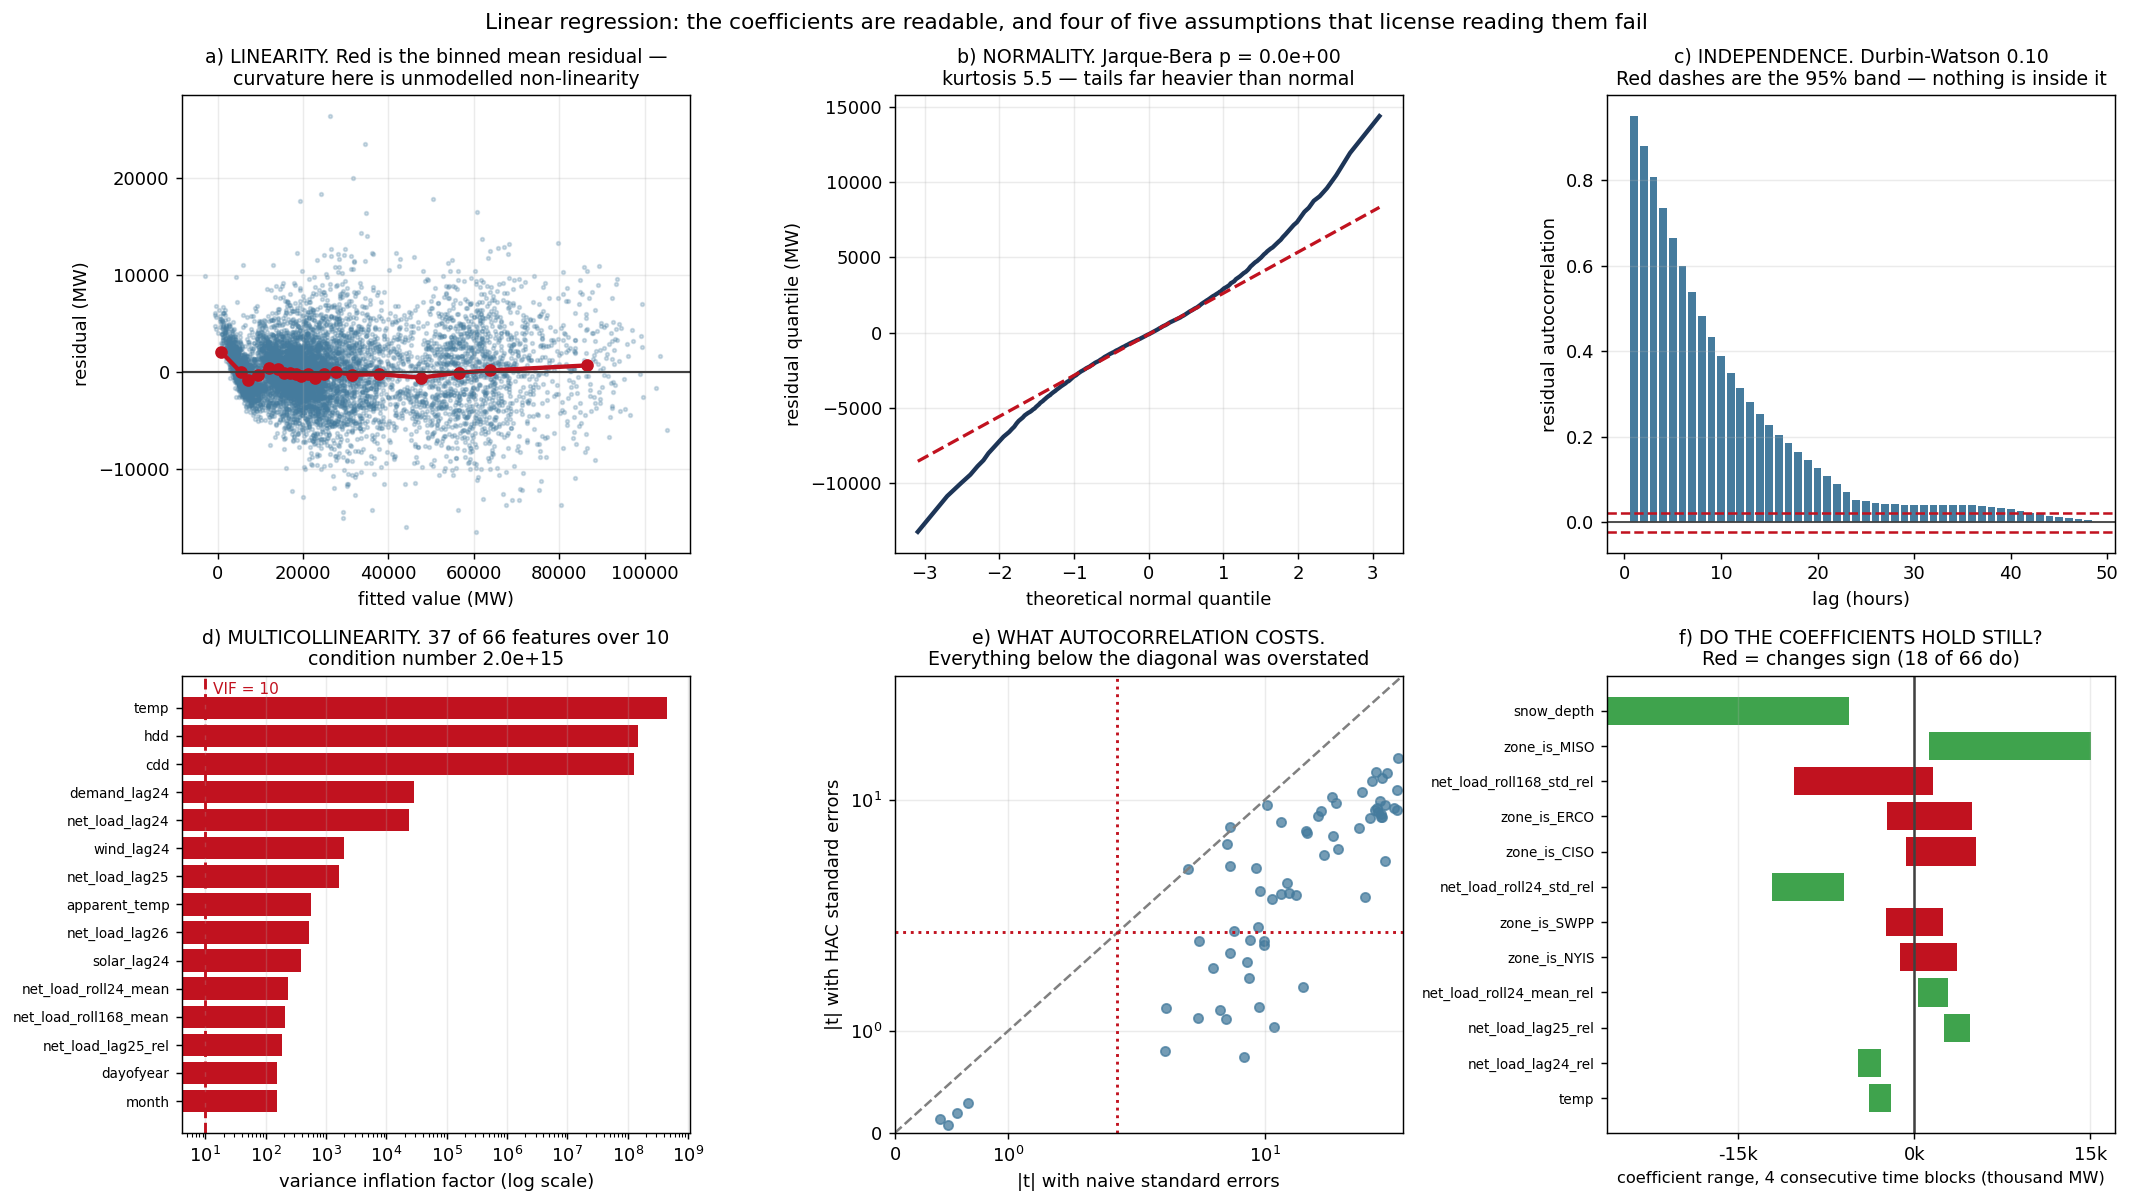

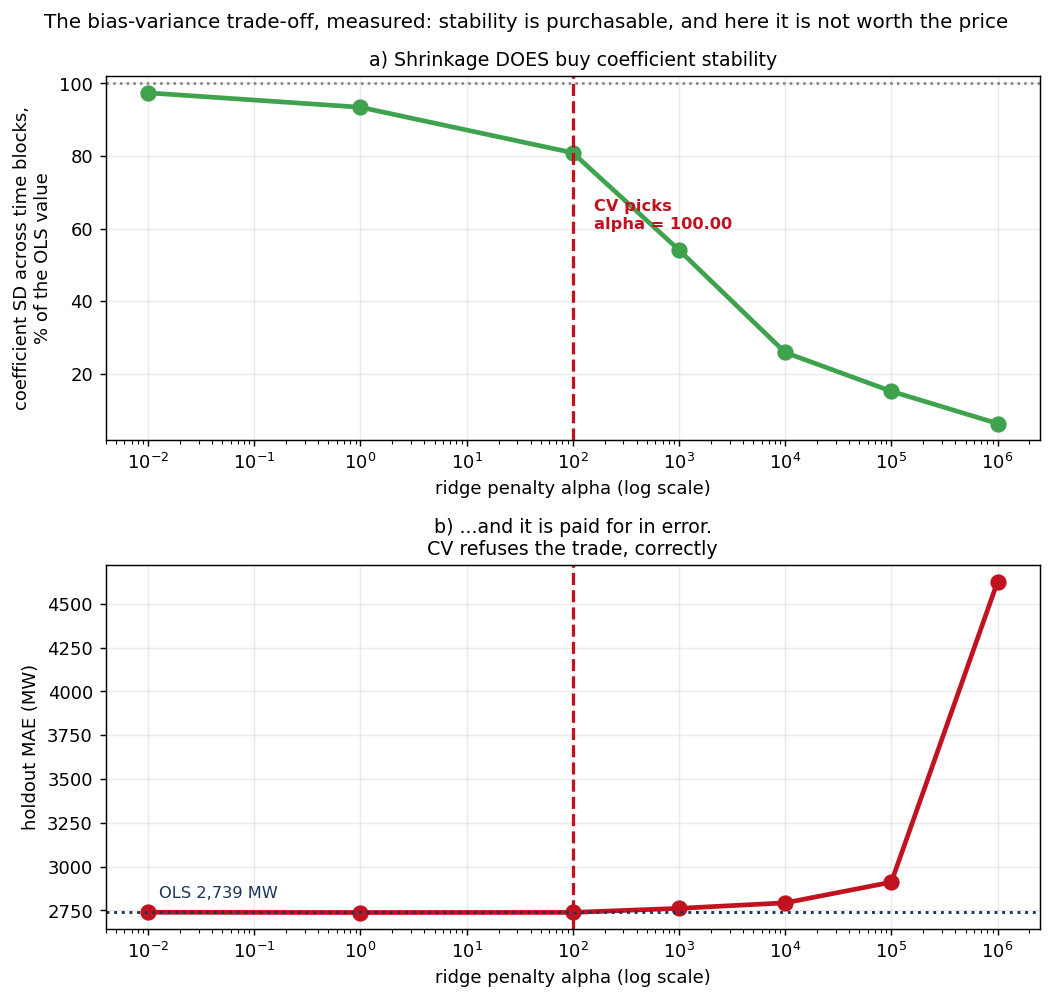

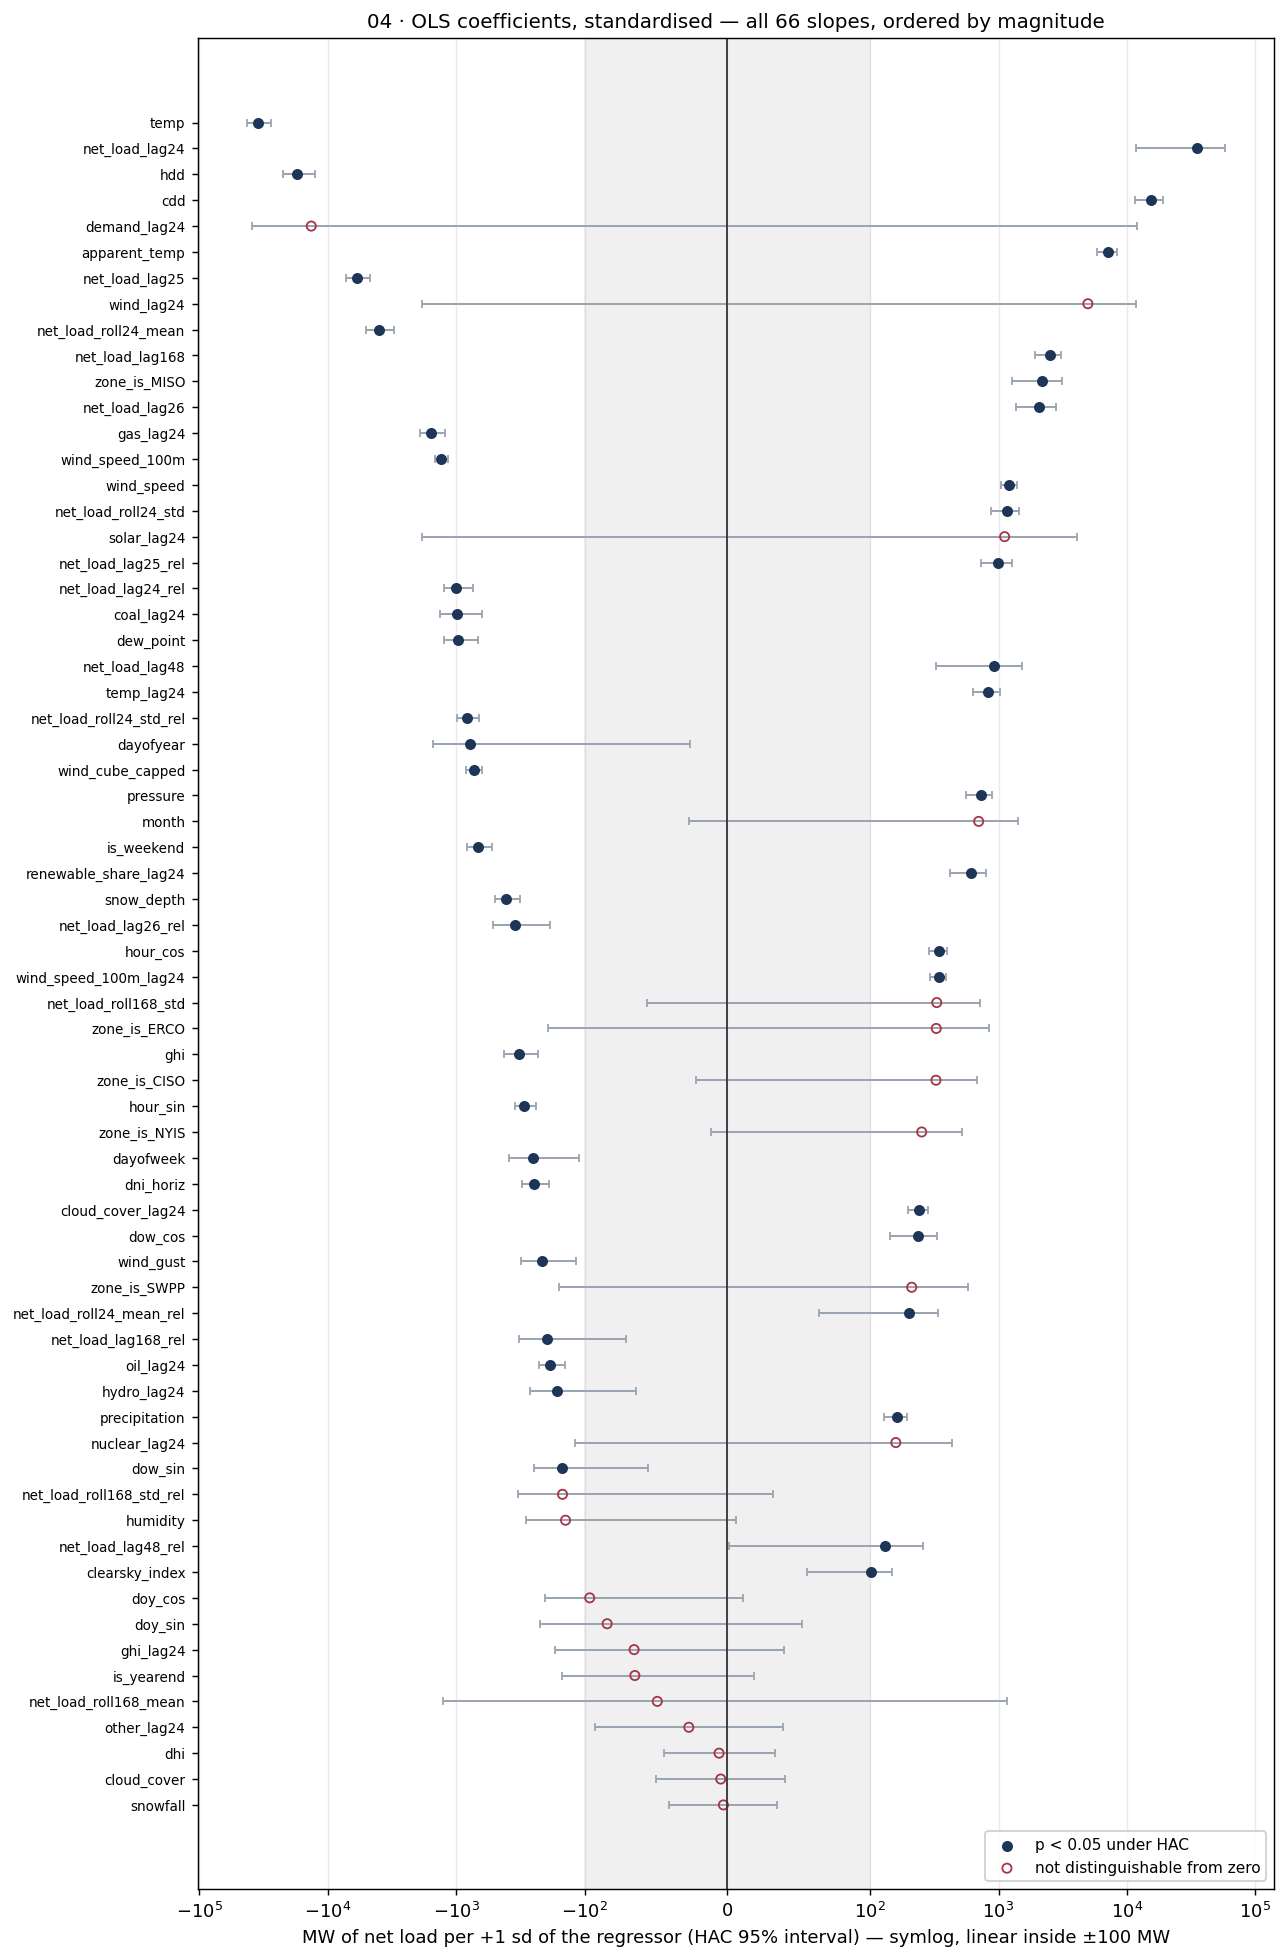


wrote 5 tables to data/processed/linear/
   45 of 66 slopes are distinguishable from zero under
   HAC. The largest standardised effect is temp at -35,031 MW per sd.


In [4]:
# WHAT: ordinary least squares with its full inferential apparatus — coefficient
#       table, R^2 / adjusted R^2 / F, and every one of the five classical
#       assumptions tested rather than assumed — followed by what each violation
#       costs and what the next model up the ladder does about it.
# WHY:  the rest of this notebook compares models by held-out error, which is right
#       for a forecast and answers none of the questions inference asks: WHICH
#       variables matter, by HOW MUCH, with WHAT PRECISION, and under what conditions
#       is that reading valid. Only the linear model answers those directly — a
#       boosted ensemble has no coefficient to put a standard error on. Every later
#       model in this notebook is a response to a specific failure diagnosed here, so
#       running the ladder without this section leaves "we used gradient boosting" as
#       a statement of taste rather than a conclusion.
# NOTE: OLS is fitted on the SAME engineered design matrix the tree models see — same
#       lags, same calendar encodings, same MI selection — so any difference in score
#       is attributable to the estimator and not to the features.
from src import models as L

lin_pipe = P.make_supervised_pipeline(
    cfg.NUMERIC_FEATURES, lags=LAGS, k="all",
    model=Ridge(alpha=1.0)).fit(dev, y_dev)
X_dev = L.design_matrix(lin_pipe, dev)
X_hold = L.design_matrix(lin_pipe, hold)[X_dev.columns]
X_dev = X_dev.fillna(X_dev.median())
X_hold = X_hold.fillna(X_dev.median())
_ref = X_dev.attrs.get("reference_levels", {})
print(f"design matrix: {X_dev.shape[0]:,} rows x {X_dev.shape[1]} features "
      f"(the same features the tree models receive)")
print(f"   zone dummy dropped as the reference level: {list(_ref.values())}")
print( "   THE DUMMY VARIABLE TRAP. The pipeline one-hot encodes all six zones, which")
print( "   costs a tree nothing. Add an intercept and the design is EXACTLY singular --")
print( "   the six dummies sum to the constant column. statsmodels does not crash; it")
print( "   falls back to a pseudo-inverse and returns coefficients that are not uniquely")
print( "   identified. Dropping one dummy removes that identity, but exact identities among")
print( "   the lag features remain, so the condition number printed below stays very large.")
print( "   The five surviving dummies read as contrasts against the omitted zone, which is")
print( "   what a zone fixed effect actually means.")

# ---------------------------------------------------------------------------
# 1. The fit, and the table
# ---------------------------------------------------------------------------
ols = L.ols_fit(X_dev, y_dev)
summ = L.fit_summary(ols)
# RENAMED FROM `coefs`, WHICH THE 4.3 BASELINE CELL ALREADY OWNS for the renewable-leg
# coefficient dict. The collision killed a 2h54m run in a later cell with
# KeyError: 'zones'.
ols_coefs = L.coefficient_table(ols, X_dev.columns)
r2w = L.within_group_r2(y_dev, ols.resid, dev[GROUP])

print(f"\nOLS on {summ['n']:,} observations, {summ['df_model']} model degrees of freedom (design rank - 1)")
print(f"   R-squared          {summ['r2']:.4f}")
print(f"   adjusted R-squared {summ['adj_r2']:.4f}   <- the one to quote on a wide design")
print(f"   R-squared WITHIN zone {r2w['r2_within']:.4f}   <- the one that is not inflated")
print(f"      {r2w['between_share_of_variance']:.1%} of the total variance is simply "
      f"'which zone is this row?'. A model")
print( "      knowing nothing but the zone dummies would already score high on the")
print( "      headline number; the within version removes that free variance and asks")
print( "      how much of a zone's OWN hour-to-hour variation is explained.")
print(f"   residual s.e.      {summ['sigma']:,.1f} MW")
print(f"   F({summ['df_model']}, {summ['df_resid']:,}) = {summ['f_stat']:,.0f}, "
      f"p = {summ['f_pvalue']:.3g}")
print(f"   AIC {summ['aic']:,.0f}   BIC {summ['bic']:,.0f}")
print("\n   The F-statistic is near-useless here and printing it without comment would")
print("   be misleading: it tests whether ALL slopes are jointly zero, and with a")
print("   24-hour lag of net load in the design that null was never plausible. A vast")
print("   F is evidence the null was a straw man, not that the model is good.")

print("\nten largest |t| — coefficient, std err, t, p, 95% CI:")
top = ols_coefs.drop("const").reindex(ols_coefs.drop("const")["t"].abs().sort_values(
    ascending=False).index).head(10)
print(top.round(4).to_string())

# ---------------------------------------------------------------------------
# 1b. THE FULL TABLE — all of them, not the ten loudest
# ---------------------------------------------------------------------------
# WHY THE TOP TEN IS NOT ENOUGH, and this is a defect being repaired rather than
# a feature being added. The block above ranks by |t| and stops at ten, so most
# of the design matrix appeared NOWHERE in this notebook. A reader could not
# check a coefficient's sign, could not see which terms are indistinguishable
# from zero, and could not audit what the zone and season dummies contrast
# against. Selecting which rows to show BY the statistic being reported is also
# the one selection rule that cannot be defended: the ten largest |t| are the ten
# most likely to be large by chance as well as the ten most likely to be real.
#
# `xname` IS ESSENTIAL AND IS THE EXAM QUESTION IN THIS BLOCK. `L.ols_fit`
# hands statsmodels `np.asarray(X, dtype=float)` — a bare numpy array, with the
# column names thrown away. A plain `.summary()` therefore labels the regressors
# `x1 ... x66` and the table is unreadable. The names are re-attached here in
# design-matrix order, intercept first, and the length is asserted rather than
# trusted: an off-by-one in `xname` would mislabel every coefficient after it
# and nothing else in this notebook would notice.
#
# THE KEYWORD IS `xname`, SINGULAR, AND IT TAKES THE WHOLE SEQUENCE — statsmodels
# 0.14.3 signature is summary(yname, xname, title, alpha, slim). `xnames=` raises
# TypeError. Worth knowing because the plural reads more natural and is what a
# reasonable person types first.
XNAMES = ["const"] + list(X_dev.columns)
assert len(XNAMES) == int(ols.params.shape[0]), (
    f"xnames has {len(XNAMES)} entries for {ols.params.shape[0]} regressors — "
    "a mismatch would silently mislabel every row of the table")

print(f"\nfull OLS table, nonrobust standard errors, "
      f"{len(XNAMES)} regressors including the intercept:")
display(ols.summary(xname=XNAMES))
print("   Read the nonrobust table for the ESTIMATES and the R-squared only. Its")
print("   standard errors, t-statistics and p-values are not usable here, and the")
print("   block below measures by how much — the assumptions they rest on are")
print("   tested immediately after this and they fail.")

# ---------------------------------------------------------------------------
# 2. The five assumptions, tested
# ---------------------------------------------------------------------------
# SERIAL STATISTICS MUST BE COMPUTED WITHIN ZONE. The panel is sorted
# (timestamp, zone) so that a positional CV split is chronological -- which means two
# ADJACENT ROWS are six different zones at the same hour, not one zone at consecutive
# hours. Durbin-Watson run straight down that column measures the CROSS-SECTIONAL
# correlation between zones at a fixed instant and calls it serial correlation. Both
# are computed so the difference can be shown rather than asserted.
diag = L.assumption_battery(ols, X_dev, groups=dev[GROUP], order=dev[TIME])
vif = L.variance_inflation(X_dev)

print("\n" + "-" * 76)
print("THE FIVE CLASSICAL ASSUMPTIONS — null stated, because a p-value whose null the")
print("reader has to guess is not a result. For 2 and 3 the null is the GOOD case.")
print("-" * 76)
print(f"1. LINEARITY            E[y|X] = X'b")
print(f"   -> read panel (a): structure in residuals vs fitted means the linear form is wrong")
print(f"2. INDEPENDENCE         null: errors serially uncorrelated (Durbin-Watson = 2)")
print(f"   Durbin-Watson WITHIN zone  {diag['durbin_watson']:.3f}  -> "
      f"{diag['dw_verdict']}   ({diag['n_groups_used']} zones)")
print(f"   Durbin-Watson in ROW order {diag['durbin_watson_row_order']:.3f}  <- WRONG, "
      f"and it looks innocent")
print( "      Row order on a (timestamp, zone) panel compares different ZONES at the")
print( "      same hour. It is not a weaker version of the right answer; it answers a")
print( "      different question.")
print(f"   within-zone residual autocorrelation: lag 1 {diag['resid_acf_lag1']:+.3f}, "
      f"lag 24 {diag['resid_acf_lag24']:+.3f}")
print(f"3. HOMOSCEDASTICITY     null: error variance constant")
print(f"   Breusch-Pagan LM {diag['breusch_pagan_stat']:,.1f}, "
      f"p = {diag['breusch_pagan_p']:.3g}  (on {diag['bp_n_used']:,} rows)")
print(f"4. NORMALITY            null: errors Gaussian")
print(f"   Jarque-Bera {diag['jarque_bera_stat']:,.0f}, p = {diag['jarque_bera_p']:.3g}"
      f"   skew {diag['resid_skew']:+.2f}, kurtosis {diag['resid_kurtosis']:.2f}")
print(f"5. NO MULTICOLLINEARITY")
print(f"   condition number {diag['condition_number']:,.0f}   (>30 is the usual concern)")
print(f"   VIF > 10: {int((vif['vif'] > 10).sum())} of {len(vif)} features; "
      f"VIF > 100: {int((vif['vif'] > 100).sum())}")
print(f"   worst: " + ", ".join(f"{i} ({v:,.0f})" for i, v in vif['vif'].head(3).items()))

# ---------------------------------------------------------------------------
# 3. What the violations cost — robust standard errors
# ---------------------------------------------------------------------------
# The coefficients do NOT change. Only the standard errors do. That is the single
# most useful thing to understand about robust inference: it does not fix the
# estimate, it fixes your confidence in it.
# Driscoll-Kraay: `dev` is time-major, so the 24 lags are taken over HOURS (not rows of
# six zones) and zones that err together in the same hour are not counted as independent
ols_hac = L.ols_fit(X_dev, y_dev, cov="HAC", hac_lags=24, times=dev[TIME])
ols_hc3 = L.ols_fit(X_dev, y_dev, cov="HC3")
shift_hac = L.significance_shift(ols, ols_hac, X_dev.columns)
shift_hc3 = L.significance_shift(ols, ols_hc3, X_dev.columns)
assert np.allclose(ols.params, ols_hac.params), "robust SEs must not move the estimates"

print(f"\nrobust standard errors (coefficients identical, asserted in the cell):")
print(f"   naive          {shift_hac['n_significant_naive']:2d} of "
      f"{shift_hac['n_terms']} slopes significant at 5%")
print(f"   HC3  (hetero)  {shift_hc3['n_significant_robust']:2d} significant, "
      f"median SE x{shift_hc3['median_se_inflation']:.2f}")
print(f"   HAC  (both)    {shift_hac['n_significant_robust']:2d} significant, "
      f"median SE x{shift_hac['median_se_inflation']:.2f}")
if shift_hac["lost_significance"]:
    print(f"   lost significance under HAC: {', '.join(shift_hac['lost_significance'][:8])}"
          + (" ..." if len(shift_hac["lost_significance"]) > 8 else ""))
print("   Anything significant under the naive estimator and not under HAC was never")
print("   significant — it was autocorrelation being counted as independent evidence.")

# THE SAME FIT UNDER HAC, and both tables are shown deliberately. The
# coefficients are identical — asserted four lines above — so the two tables
# differ ONLY in the columns that express confidence. Side by side they are the
# clearest statement this notebook can make about what robust inference does and
# does not buy: the point estimate does not move, the certainty around it does.
print(f"\nthe same fit under Driscoll-Kraay (HAC over hours, 24 lags) — identical "
      f"coefficients, honest standard errors:")
display(ols_hac.summary(xname=XNAMES))
print("   This is the table to quote. Every difference from the one above is a")
print("   standard error the nonrobust estimator understated by treating")
print("   autocorrelated hours as independent observations.")

# ---------------------------------------------------------------------------
# 4. The decisive collinearity diagnostic: do the coefficients hold still?
# ---------------------------------------------------------------------------
# A VIF is a statement about the design matrix. This is a statement about what
# actually happens to the answer when the data changes slightly.
stab = L.coefficient_stability(X_dev, y_dev, n_blocks=4)
n_flip = int(stab["sign_flips"].sum())
print(f"\nrefitting on 4 consecutive time blocks:")
print(f"   {n_flip} of {len(stab)} coefficients CHANGE SIGN between blocks")
print(f"   most unstable: " + ", ".join(
    f"{i} (sd {r.sd_across_blocks:,.0f})" for i, r in stab.head(3).iterrows()))
print("   A coefficient that is positive on one year and negative on the next has no")
print("   stable interpretation, and no number of significance stars rescues it. This")
print("   is why this project never reports linear coefficients as importances.")

# ---------------------------------------------------------------------------
# 5. Ridge — and why it does NOT rescue this model
# ---------------------------------------------------------------------------
# THE TEXTBOOK EXPECTATION. Ridge adds a penalty lambda*||b||^2, shrinking coefficients
# toward zero and toward each other. That is the standard medicine for collinearity: it
# trades a little bias for a large reduction in VARIANCE, and with 37 features over
# VIF 10 this design looks like exactly the patient it was invented for.
#
# WHAT ACTUALLY HAPPENS HERE, and it is worth more than the expected result would have
# been. Cross-validation over 33 values spanning 1e-2 to 1e6 selects a penalty so small
# it changes nothing, and the sweep below shows why: stability can be bought, but only
# at a price in error that CV correctly refuses to pay.
#
# THE REASON IS THE SAMPLE SIZE. Ridge fixes variance from having too few observations
# per parameter. Here n/p is about 4,000 — the OLS estimates are precisely determined
# in-sample despite the collinearity, so there is very little estimation variance left
# for a penalty to remove. High VIF inflates the standard error relative to an
# orthogonal design; it does not make the standard error large in absolute terms when
# n is a quarter of a million.
#
# SO WHAT ARE THE SIGN FLIPS? Not sampling noise — NON-STATIONARITY. The relationship
# between the features and net load genuinely differs between 2019 and 2023, as ERCOT's
# solar fleet grows and load patterns shift (notebook 03 measured that build-out directly).
# Ridge shrinks coefficients; it cannot make a time-varying relationship constant. That
# is a specification problem, and the honest response is a model that can represent
# changing structure — which is the argument for the rest of the ladder.
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import TimeSeriesSplit

# alpha is chosen by time-ordered folds, not RidgeCV's default leave-one-out: with a lag-1
# residual correlation near 0.95, leaving one hour out keeps its near-identical neighbours
# in training and always favours no penalty. X_dev is time-major (six zones per hour), so
# a gap of 6 x 168 rows is one week, the gap every CV in this project uses.
alphas = np.logspace(-2, 6, 33)
ridge_cv = SkPipeline([("sc", StandardScaler()),
                       ("ridge", RidgeCV(alphas=alphas, scoring="neg_mean_absolute_error",
                                         cv=TimeSeriesSplit(n_splits=cfg.N_SPLITS, gap=6 * 168)))]
                      ).fit(X_dev, y_dev)
_alpha = float(ridge_cv.named_steps["ridge"].alpha_)

# The bias-variance trade-off, measured rather than described: what does each level of
# shrinkage buy in coefficient stability, and what does it cost in held-out error?
_sd_x = X_dev.std(axis=0).to_numpy()
ols_sd_std = stab.loc[X_dev.columns, "sd_across_blocks"].to_numpy() * _sd_x
edges = np.linspace(0, len(X_dev), 5).astype(int)
sweep_rows = []
for a in [1e-2, 1e0, 1e2, 1e3, 1e4, 1e5, 1e6]:
    blocks = []
    for i in range(4):
        sl = slice(edges[i], edges[i + 1])
        r = SkPipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=a))]).fit(
            X_dev.iloc[sl], y_dev.iloc[sl])
        blocks.append(r.named_steps["ridge"].coef_)
    sd = np.vstack(blocks).std(0, ddof=1)
    full = SkPipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=a))]).fit(X_dev, y_dev)
    sweep_rows.append({
        "alpha": a,
        "stability_vs_ols": float(np.median(sd / np.where(ols_sd_std == 0, np.nan, ols_sd_std))),
        "holdout_mae": float(mean_absolute_error(y_hold, full.predict(X_hold))),
        "coef_l2": float(np.linalg.norm(full.named_steps["ridge"].coef_)),
    })
ridge_sweep = pd.DataFrame(sweep_rows)
shrunk = float(ridge_sweep.loc[ridge_sweep["alpha"] == 1e-2, "stability_vs_ols"].iloc[0])

import statsmodels.api as _sm
mae_ols = float(mean_absolute_error(
    y_hold, ols.predict(_sm.add_constant(np.asarray(X_hold, dtype=float),
                                         has_constant="add"))))
mae_ridge = float(mean_absolute_error(y_hold, ridge_cv.predict(X_hold)))

print(f"\nRidge, CV over {len(alphas)} values of alpha on standardised features:")
print(f"   CV selects alpha = {_alpha:,.2f} — a mild penalty that barely moves the holdout error")
print(f"   holdout MAE  OLS {mae_ols:,.1f} MW   ridge {mae_ridge:,.1f} MW "
      f"({mae_ridge - mae_ols:+,.1f})")
print(f"\n   the trade-off, measured:")
print(f"   {'alpha':>10s}{'coef SD vs OLS':>17s}{'holdout MAE':>14s}{'coef L2 norm':>15s}")
for _, r in ridge_sweep.iterrows():
    print(f"   {r['alpha']:>10,.0f}{r['stability_vs_ols']:>16.1%}"
          f"{r['holdout_mae']:>14,.0f}{r['coef_l2']:>15,.0f}")
_best_stab = ridge_sweep.iloc[ridge_sweep["stability_vs_ols"].argmin()]
print(f"\n   Stability IS purchasable: at alpha = {_best_stab['alpha']:,.0f} the "
      f"coefficient SD falls to")
print(f"   {_best_stab['stability_vs_ols']:.1%} of the OLS value — but holdout MAE rises to "
      f"{_best_stab['holdout_mae']:,.0f} MW from {mae_ols:,.0f}.")
print( "   Cross-validation refuses that trade, and it is right to.")
print(f"\n   WHY RIDGE HAS NOTHING TO FIX HERE: n/p = {len(X_dev)/X_dev.shape[1]:,.0f}. "
      f"Ridge removes")
print( "   variance from having too few rows per parameter, and with a quarter of a")
print( "   million rows there is almost none left to remove. High VIF inflates the")
print( "   standard error RELATIVE to an orthogonal design; it does not make it large")
print( "   in absolute terms at this n.")
print(f"\n   So the {n_flip} sign flips are not sampling noise: some coefficients sit on exact identities "
      f"the singular design cannot identify, and the relationship itself changes between years.")
print( "   The relationship genuinely changes between 2019 and 2023 (notebook 03 measured")
print( "   ERCOT's solar fleet growing over exactly this window). Ridge shrinks")
print( "   coefficients; it cannot make a time-varying relationship constant. That is a")
print( "   SPECIFICATION problem, and it is the argument for the rest of the ladder:")
print( "   what follows gains by dropping LINEARITY, not by regularising it.")

# ---------------------------------------------------------------------------
# The figure
# ---------------------------------------------------------------------------
samp = np.linspace(0, len(X_dev) - 1, 8000).astype(int)
fitted_s = np.asarray(ols.fittedvalues)[samp]
resid_s = np.asarray(ols.resid)[samp]

fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.4))
ax = axes[0, 0]
ax.scatter(fitted_s, resid_s, s=4, alpha=0.25, color="#457b9d")
_b = pd.qcut(pd.Series(fitted_s), 20, duplicates="drop")
_m = pd.Series(resid_s).groupby(_b, observed=True).mean()
ax.plot([iv.mid for iv in _m.index], _m.values, "o-", color="#c1121f", lw=2.4, ms=6)
ax.axhline(0, color="0.25", lw=1.2)
ax.set_xlabel("fitted value (MW)"); ax.set_ylabel("residual (MW)")
ax.set_title("a) LINEARITY. Red is the binned mean residual —\n"
             "curvature here is unmodelled non-linearity", fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[0, 1]
from scipy import stats as _st
_q = np.linspace(0.001, 0.999, 400)
ax.plot(_st.norm.ppf(_q), np.quantile(resid_s, _q), lw=2.4, color="#1d3557")
_lo, _hi = np.quantile(resid_s, [0.25, 0.75])
_slope = (_hi - _lo) / (_st.norm.ppf(0.75) - _st.norm.ppf(0.25))
ax.plot(_st.norm.ppf(_q), _slope * _st.norm.ppf(_q) + np.median(resid_s), "--",
        color="#c1121f", lw=1.8)
ax.set_xlabel("theoretical normal quantile"); ax.set_ylabel("residual quantile (MW)")
ax.set_title(f"b) NORMALITY. Jarque-Bera p = {diag['jarque_bera_p']:.1e}\n"
             f"kurtosis {diag['resid_kurtosis']:.1f} — tails far heavier than normal",
             fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[0, 2]
lags_plot = np.arange(1, len(diag["resid_acf"]) + 1)
ax.bar(lags_plot, diag["resid_acf"], color="#457b9d")
_ci = 1.96 / np.sqrt(len(resid_s))
ax.axhline(_ci, color="#c1121f", ls="--", lw=1.4)
ax.axhline(-_ci, color="#c1121f", ls="--", lw=1.4)
ax.axhline(0, color="0.25", lw=1)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("residual autocorrelation")
ax.set_title(f"c) INDEPENDENCE. Durbin-Watson {diag['durbin_watson']:.2f}\n"
             f"Red dashes are the 95% band — nothing is inside it", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1, 0]
_v = vif["vif"].replace(np.inf, np.nan).dropna().head(15)[::-1]
ax.barh(range(len(_v)), _v.values,
        color=["#c1121f" if x > 10 else "#9aa0a6" for x in _v.values])
ax.axvline(10, color="#c1121f", ls="--", lw=1.6)
ax.annotate("VIF = 10", (10, len(_v) - 0.5), xytext=(4, 0), textcoords="offset points",
            fontsize=8.5, color="#c1121f")
ax.set_xscale("log")
ax.set_yticks(range(len(_v))); ax.set_yticklabels(_v.index, fontsize=7.5)
ax.set_xlabel("variance inflation factor (log scale)")
ax.set_title(f"d) MULTICOLLINEARITY. {int((vif['vif']>10).sum())} of {len(vif)} "
             f"features over 10\ncondition number {diag['condition_number']:.1e}",
             fontsize=10.5)
ax.grid(alpha=0.25, axis="x")

ax = axes[1, 1]
_t_naive = np.abs(ols.tvalues[1:])
_t_hac = np.abs(ols_hac.tvalues[1:])
ax.scatter(_t_naive, _t_hac, s=26, alpha=0.75, color="#457b9d")
_lim = max(_t_naive.max(), _t_hac.max()) * 1.05
ax.plot([0, _lim], [0, _lim], "--", color="0.5", lw=1.4)
ax.axhline(1.96, color="#c1121f", ls=":", lw=1.6)
ax.axvline(1.96, color="#c1121f", ls=":", lw=1.6)
ax.set_xscale("symlog"); ax.set_yscale("symlog")
ax.set_xlim(0, _lim); ax.set_ylim(0, _lim)      # |t| cannot be negative; the autoscale showed -10^0
ax.set_xlabel("|t| with naive standard errors")
ax.set_ylabel("|t| with HAC standard errors")
ax.set_title(f"e) WHAT AUTOCORRELATION COSTS.\nEverything below the diagonal was "
             f"overstated", fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[1, 2]
_s = stab.head(12)[::-1]
ax.barh(range(len(_s)), _s["max"] - _s["min"],
        left=_s["min"], color=["#c1121f" if f else "#3fa34d" for f in _s["sign_flips"]])
ax.axvline(0, color="0.25", lw=1.4)
ax.set_yticks(range(len(_s))); ax.set_yticklabels(_s.index, fontsize=7.5)
# FOUR TICKS IN THOUSANDS. The default locator asked for nine across
# -25,000 to +15,000 in a panel one sixth of the grid, and the negative labels
# rendered as one continuous run of digits. This panel is read for the SIGN of a
# range and whether it crosses zero, never for a precise magnitude.
ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=4))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_xlabel("coefficient range, 4 consecutive time blocks (thousand MW)", fontsize=9)
ax.set_title(f"f) DO THE COEFFICIENTS HOLD STILL?\n"
             f"Red = changes sign ({n_flip} of {len(stab)} do)", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")

fig.suptitle("Linear regression: the coefficients are readable, and four of five "
             "assumptions that license reading them fail", fontsize=12)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_linear_diagnostics.png", bbox_inches="tight")
plt.show()

# A second, small figure: the bias-variance trade-off, drawn rather than described.
fig, axes = plt.subplots(2, 1, figsize=(8.2, 7.8))
ax = axes[0]
ax.semilogx(ridge_sweep["alpha"], ridge_sweep["stability_vs_ols"] * 100, "o-",
            lw=2.6, ms=8, color="#3fa34d")
ax.axhline(100, color="0.5", ls=":", lw=1.4)
ax.axvline(_alpha, color="#c1121f", ls="--", lw=1.8)
ax.annotate(f"CV picks\nalpha = {_alpha:.2f}", (_alpha, 60), xytext=(12, 0),
            textcoords="offset points", fontsize=9, color="#c1121f", fontweight="bold")
ax.set_xlabel("ridge penalty alpha (log scale)")
ax.set_ylabel("coefficient SD across time blocks,\n% of the OLS value")
ax.set_title("a) Shrinkage DOES buy coefficient stability", fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[1]
ax.semilogx(ridge_sweep["alpha"], ridge_sweep["holdout_mae"], "o-", lw=2.6, ms=8,
            color="#c1121f")
ax.axhline(mae_ols, color="#1d3557", ls=":", lw=1.6)
ax.annotate(f"OLS {mae_ols:,.0f} MW", (ridge_sweep["alpha"].iloc[0], mae_ols),
            xytext=(6, 8), textcoords="offset points", fontsize=9, color="#1d3557")
ax.axvline(_alpha, color="#c1121f", ls="--", lw=1.8)
ax.set_xlabel("ridge penalty alpha (log scale)")
ax.set_ylabel("holdout MAE (MW)")
ax.set_title("b) ...and it is paid for in error.\nCV refuses the trade, correctly",
             fontsize=10.5)
ax.grid(alpha=0.25)
fig.suptitle("The bias-variance trade-off, measured: stability is purchasable, "
             "and here it is not worth the price", fontsize=11)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_ridge_tradeoff.png", bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# 6. THE COEFFICIENT FIGURE, and the export that lets someone check it
# ---------------------------------------------------------------------------
# STANDARDISED, and the standardisation is the whole point. Raw OLS coefficients
# on this design are not comparable to one another: `temp` is in degrees, the
# lags are in MW, the dummies are 0/1. A coefficient of +170 on `wind_speed` and
# one of 1.5 on `net_load_lag24` say nothing about relative magnitude until both are
# expressed per one standard deviation of their own regressor. Multiplying by
# sd(x) does exactly that, and leaves the units in MW of net load.
#
# THE INTERVALS ARE HAC, NOT NONROBUST. Plotting nonrobust intervals would draw
# error bars the assumption battery has already shown to be too narrow, which
# would make this the single most misleading object in the notebook.
#
# WHAT THIS FIGURE IS NOT: an importance ranking for the champion. It is a
# picture of a LINEAR fit, and section 4.5 measures how much of the signal is not
# linear. Section 4.5 is explicit that Ridge coefficients must not be presented
# as importances — 19 change sign across time blocks, 37 carry VIF > 10 — and the
# same caution applies here. Read it as "what the linear model thinks", never as
# "what matters". Section 4.16 (preliminary) and notebook 07 are where importance is answered.
_sd_all = X_dev.std(ddof=0)
_ci_hac = np.asarray(ols_hac.conf_int())
_coef_std = pd.DataFrame({
    "coef_mw_per_sd": np.asarray(ols_hac.params)[1:] * _sd_all.to_numpy(),
    "lo_mw_per_sd": _ci_hac[1:, 0] * _sd_all.to_numpy(),
    "hi_mw_per_sd": _ci_hac[1:, 1] * _sd_all.to_numpy(),
    "p_hac": np.asarray(ols_hac.pvalues)[1:],
}, index=X_dev.columns)
_plot = _coef_std.reindex(_coef_std["coef_mw_per_sd"].abs().sort_values().index)
_sig = (_plot["p_hac"] < 0.05).to_numpy()
_ypos = np.arange(len(_plot))

fig, ax = plt.subplots(figsize=(cfg.FIGSIZE[0], max(6.0, 0.23 * len(_plot))))
ax.errorbar(_plot["coef_mw_per_sd"].to_numpy(), _ypos,
            xerr=[(_plot["coef_mw_per_sd"] - _plot["lo_mw_per_sd"]).to_numpy(),
                  (_plot["hi_mw_per_sd"] - _plot["coef_mw_per_sd"]).to_numpy()],
            fmt="none", ecolor="#9aa5b1", elinewidth=1.1, capsize=2, zorder=1)
ax.scatter(_plot["coef_mw_per_sd"].to_numpy()[_sig], _ypos[_sig], s=26,
           color="#1d3557", zorder=2, label="p < 0.05 under HAC")
ax.scatter(_plot["coef_mw_per_sd"].to_numpy()[~_sig], _ypos[~_sig], s=26,
           facecolors="none", edgecolors="#a63446", zorder=2,
           label="not distinguishable from zero")
# SYMLOG, AND THE REASON IS IN THE DATA RATHER THAN IN TASTE. The standardised
# effects span four orders of magnitude: `temp` and the degree-day pair carry tens of
# thousands of MW per sd because they sit on an exact identity (cdd - hdd = temp - 15),
# and so does `net_load_lag24`, while nine of the sixty-six sit inside ±100 MW. On a
# linear axis the largest terms push the rest into a vertical stripe with their
# intervals invisible, which was the first version of this figure. Symlog is linear
# inside ±100 MW and logarithmic outside it, so zero stays a real point on the axis
# (a pure log scale cannot show a sign change) and every slope is separated.
#
# THE SHADED BAND IS THE POINT OF THE LINEAR WINDOW: ±100 MW against a holdout
# MAE in the low thousands is a term that could be deleted without anyone
# noticing. Statistical significance and practical size are different questions,
# and the band is where the figure says so — several slopes are significant
# under HAC and sit inside it.
ax.set_xscale("symlog", linthresh=100)
ax.axvspan(-100, 100, color="#f0f0f0", zorder=0)
ax.axvline(0, color="#333333", lw=1.0)
ax.set_yticks(_ypos)
ax.set_yticklabels(_plot.index, fontsize=7.5)
ax.set_xlabel("MW of net load per +1 sd of the regressor (HAC 95% interval) — "
              "symlog, linear inside ±100 MW")
ax.set_title(f"04 · OLS coefficients, standardised — all {len(_plot)} slopes, "
             f"ordered by magnitude", fontsize=11)
ax.legend(loc="lower right", fontsize=8.5, framealpha=0.9)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_ols_coefficients.png", bbox_inches="tight")
plt.show()

# THE EXPORT. `data/processed/linear/` holds what the tables above printed, as
# CSV, so a coefficient can be checked without re-running the notebook and so a
# number quoted in prose traces to a file rather than to a scroll position in a
# cell output. Gitignored with the rest of data/processed — regenerated, never
# committed.
_lin_dir = cfg.DATA_PROC / "linear"
_lin_dir.mkdir(parents=True, exist_ok=True)
L.coefficient_table(ols, X_dev.columns).to_csv(_lin_dir / "ols_nonrobust.csv")
L.coefficient_table(ols_hac, X_dev.columns).to_csv(_lin_dir / "ols_hac.csv")
L.coefficient_table(ols_hc3, X_dev.columns).to_csv(_lin_dir / "ols_hc3.csv")
_coef_std.to_csv(_lin_dir / "ols_standardised_hac.csv")
vif.to_csv(_lin_dir / "vif.csv")
print(f"\nwrote {len(list(_lin_dir.glob('*.csv')))} tables to "
      f"{_lin_dir.relative_to(cfg.ROOT).as_posix()}/")

_n_sig_fig = int(_sig.sum())
_biggest = str(_plot.index[-1])
_biggest_mw = float(_plot["coef_mw_per_sd"].iloc[-1])
print(f"   {_n_sig_fig} of {len(_plot)} slopes are distinguishable from zero under")
print(f"   HAC. The largest standardised effect is {_biggest} at "
      f"{_biggest_mw:+,.0f} MW per sd.")

R.save("nb04", {"linear": {
    "n_features": int(X_dev.shape[1]),
    "summary": summ,
    "top_terms": {i: {k: float(v) for k, v in r.items()} for i, r in top.iterrows()},
    "assumptions": {k: v for k, v in diag.items()
                    if k not in ("resid_acf", "resid_acf_row_order")},
    "r2_within_zone": r2w,
    "reference_levels": _ref,
    "resid_acf_first12": [float(x) for x in diag["resid_acf"][:12]],
    "vif_over_10": int((vif["vif"] > 10).sum()),
    "vif_over_100": int((vif["vif"] > 100).sum()),
    "vif_worst": {i: float(v) for i, v in vif["vif"].head(5).items()},
    "robust_hac": shift_hac, "robust_hc3": shift_hc3,
    "coef_sign_flips": n_flip, "n_coefs": int(len(stab)),
    "ridge_alpha": _alpha,
    "ridge_coef_sd_vs_ols": shrunk,
    "ridge_sweep": ridge_sweep.to_dict("records"),
    "holdout_mae_ols": mae_ols, "holdout_mae_ridge": mae_ridge,
    "n_slopes": int(len(_plot)),
    "n_slopes_within_100mw_per_sd": int((_plot["coef_mw_per_sd"].abs() < 100).sum()),
    "n_slopes_significant_hac": _n_sig_fig,
    "largest_standardised_effect": {"term": _biggest, "mw_per_sd": _biggest_mw},
    "standardised_coefs_mw_per_sd": {
        str(k): float(v) for k, v in _coef_std["coef_mw_per_sd"].items()
    },
}});

**What this shows:** the OLS assumption checks (residuals vs fitted, Q-Q, residual ACF, VIF, naive vs HAC |t|, coefficient stability across time blocks) and the ridge penalty sweep.

**What I see:** Four of the five assumptions fail. Breusch–Pagan **p = 0.0**, Jarque–Bera **p = 0.0** (kurtosis **5.47**), Durbin–Watson **0.099** within zone with lag-1 residual autocorrelation **0.950** (row-order DW reads **1.757**, which is the wrong number). The condition number is **2.0e15** across **66 features**, and **18 coefficients change sign** across time blocks. Ridge barely changes accuracy: holdout MAE **2,739.3 (OLS) vs 2,738.6 (ridge)**, with CV choosing alpha 100.

**What it means:** Consecutive hours carry nearly the same error, so OLS standard errors are far too small. Ridge cannot fix the sign flips: with n/p above 4,000 there is little variance to remove. Some coefficients sit on exact identities the singular design cannot identify, and some relationships change between 2019 and 2023. Both are specification problems, which is the case for moving to non-linear models.

**What I do:** Keep OLS as a scored baseline, not an explanation. Quote the HAC table, where 45 of 66 slopes stay significant (full list in `results.json:nb04.linear.robust_hac`). Importance comes from notebook 07.


**Figure: `04_ols_coefficients.png` — standardised OLS coefficients with HAC intervals.**

**What this shows:** all 66 slopes in MW per +1 sd of the regressor, on a symlog axis (linear inside ±100 MW), with HAC 95% intervals. Filled markers are significant at p < 0.05 under HAC.

**What I see:** The largest effects come in offsetting pairs: `temp` **−35,031 MW/sd** against `hdd` **−17,291** and `cdd` **+15,375**; `net_load_lag24` **+34,916** against `net_load_lag25` **−5,923**. **45 of 66** slopes are significant under HAC against **62** under naive errors (HAC inflates the median standard error **3.89×**). `ghi`, `dhi` and `dni_horiz` have infinite VIF, and **37 of 66** terms exceed VIF 10.

**What it means:** These are exact identities, not physics: `cdd − hdd = temp − 15`, `ghi = dhi + dni_horiz`, and `net_load_lag24 = demand_lag24 − wind_lag24 − solar_lag24`. Along each identity the coefficients are not identified, so huge effects cancel in pairs.

**What I do:** Nothing changes for the champion: trees do not care about this collinearity, and every lag column is observable at the origin. The figure shows that the linear coefficients are not readable; it is not a ranking of drivers.


### 4.5 — The model ladder

Four estimators (ridge, random forest, histogram gradient boosting, quantile GBM) under the same pipeline, features and folds, so only the estimator changes. The two baselines are shown as holdout references. Ridge is scored, but its coefficients are not interpreted (§4.4).

**How to read the output:** compare the gaps between models with the fold-to-fold spread. Overlapping folds mean a difference is not established yet; §4.13 tests it properly.


1  ridge                   CV MAE  2,697.9 +/-  120.4   folds 2,529 2,611 2,880 2,717 2,753   [6s]


2  random forest           CV MAE  2,237.1 +/-   73.7   folds 2,129 2,282 2,347 2,200 2,227   [250s]


3  hist gradient boosting  CV MAE  2,173.2 +/-   85.5   folds 2,049 2,132 2,310 2,172 2,202   [15s]


4  quantile GBM (median)   CV MAE  2,237.2 +/-   94.3   folds 2,091 2,225 2,387 2,226 2,257   [16s]

best rung on CV: 3  hist gradient boosting at 2,173.2 MW
ridge -> boosting buys 525 MW
forest -> boosting buys 64 MW

Ridge is scored, not interpreted: notebook 02 found 45 of 69 features at VIF > 10 on its matrix (4.4 measures this one). Notebook 07 does importance.


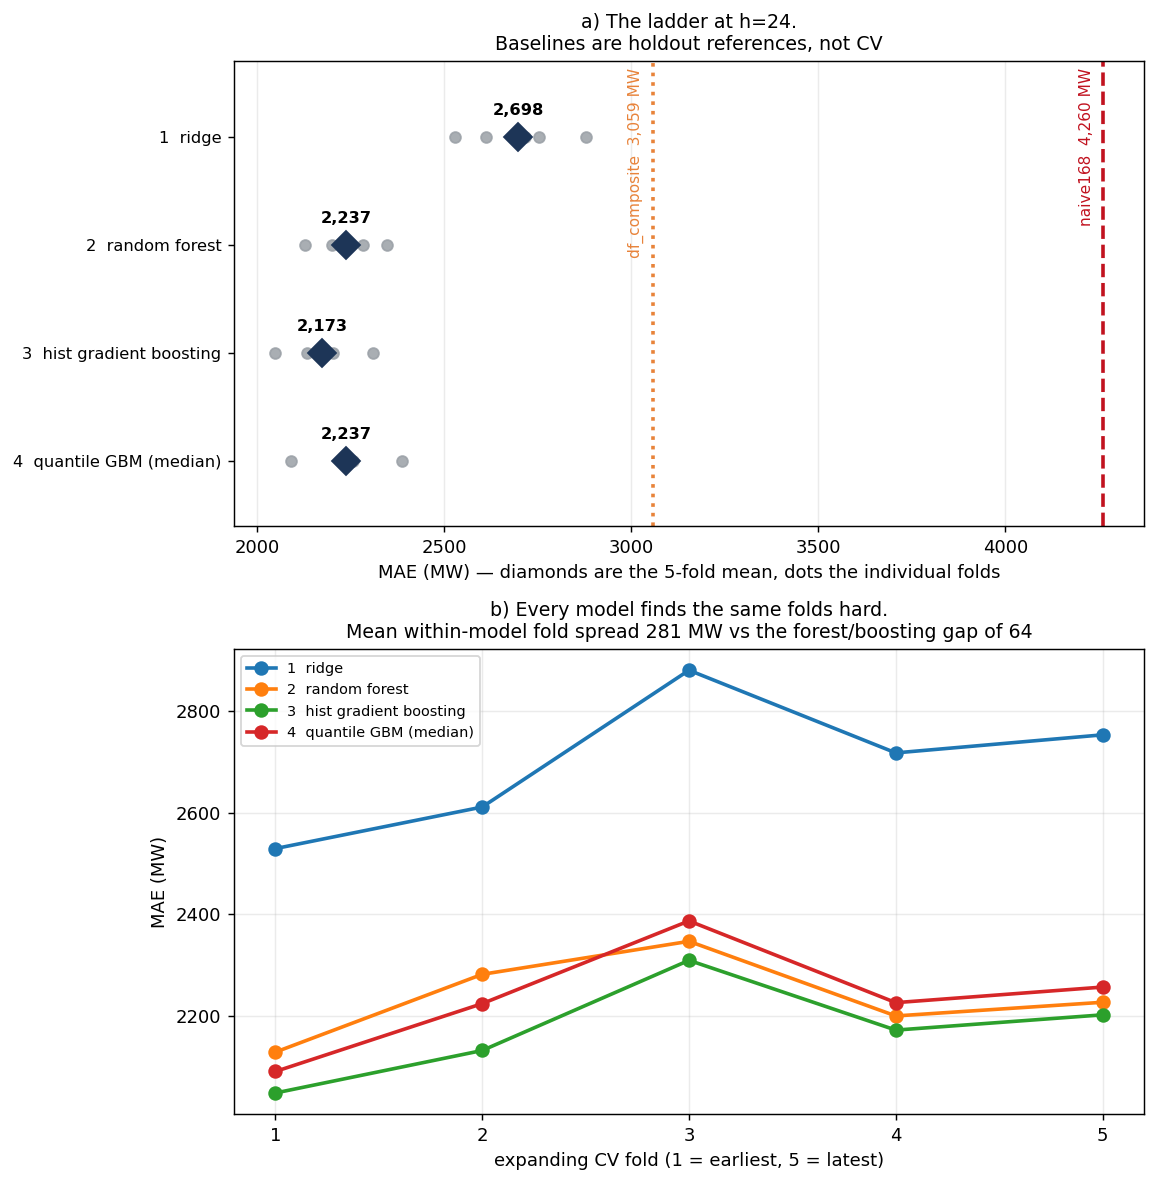

In [5]:
# WHAT: the model ladder at h=24, every rung under the identical pipeline, folds and
#       feature set — so the only thing that changes between rows is the estimator.
# WHY:  each rung has to be justified against the one below it. If the random forest
#       does not beat Ridge, that is a finding about the problem, not a failure to
#       report.
# NOTE: fold SPREAD is reported, not just the mean. Fold 5 is a harder year than fold
#       1 for every model, so a mean that hides a 220-348 MW fold range invites a
#       comparison the data does not support. 4.13 tests the differences properly.

ladder_specs = [
    ("0  seasonal naive", None),
    ("0b EIA DF composite", None),
    ("1  ridge", Ridge(alpha=1.0)),
    ("2  random forest", RandomForestRegressor(n_estimators=120, min_samples_leaf=5,
                                               random_state=cfg.SEED, n_jobs=cfg.N_JOBS)),
    ("3  hist gradient boosting", HistGradientBoostingRegressor(random_state=cfg.SEED)),
    # Rung 4. Scored by MAE at the median quantile so it sits in this table honestly;
    # the pinball loss and the actual intervals are notebook 06's job, not this one. It is
    # here to establish that the quantile objective costs little at the median, which
    # is what licenses notebook 06 using the same feature set.
    ("4  quantile GBM (median)", HistGradientBoostingRegressor(
        loss="quantile", quantile=0.5, random_state=cfg.SEED)),
]

rows = []
for name, est in ladder_specs:
    if est is None:                        # baselines carry their holdout MAE across
        key = "naive168_mae" if "naive" in name else "df_composite_mae"
        rows.append({"model": name, "cv_mae_mean": np.nan, "cv_mae_sd": np.nan,
                     "folds": [], "seconds": 0.0,
                     "holdout_reference": R.get("nb04", "baselines")[key]})
        continue
    t0 = time.time()
    pipe = P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS, model=est)
    s = -cross_val_score(pipe, dev, y_dev, cv=cv, n_jobs=cfg.N_JOBS,
                         scoring="neg_mean_absolute_error")
    rows.append({"model": name, "cv_mae_mean": float(s.mean()), "cv_mae_sd": float(s.std()),
                 "folds": [float(x) for x in s], "seconds": round(time.time() - t0, 1),
                 "holdout_reference": np.nan})
    print(f"{name:26s} CV MAE {s.mean():8,.1f} +/- {s.std():6,.1f}   "
          f"folds {' '.join(f'{x:,.0f}' for x in s)}   [{time.time()-t0:.0f}s]")

ladder_df = pd.DataFrame(rows)
_fit = ladder_df.dropna(subset=["cv_mae_mean"]).set_index("model")
best_rung = _fit["cv_mae_mean"].idxmin()
print(f"\nbest rung on CV: {best_rung} at {_fit.loc[best_rung, 'cv_mae_mean']:,.1f} MW")
print(f"ridge -> boosting buys {_fit.loc['1  ridge','cv_mae_mean'] - _fit.loc['3  hist gradient boosting','cv_mae_mean']:,.0f} MW")
print(f"forest -> boosting buys {_fit.loc['2  random forest','cv_mae_mean'] - _fit.loc['3  hist gradient boosting','cv_mae_mean']:,.0f} MW")

# RIDGE COEFFICIENTS ARE NOT REPORTED AS IMPORTANCES, and this is deliberate. Notebook 02
# measured 45 of its 69 features at VIF > 10 (4.4 measures 37 of 66 on this design). Under that much
# collinearity individual coefficients are unstable in size and sign — they can be
# large and opposite on two features that carry the same signal — so reading them as
# importance is reading noise with a confident face. Notebook 07 uses permutation and
# grouped SHAP instead, which is why this notebook shows Ridge's SCORE and not its
# coefficients.
print(f"\nRidge is scored, not interpreted: notebook 02 found {R.get('nb02','vif_over_10')} of "
      f"{R.get('nb02','n_features')} features at VIF > 10 on its matrix (4.4 measures this one). Notebook 07 does importance.")

fig, axes = plt.subplots(2, 1, figsize=(9.0, 9.2))
ax = axes[0]
fitted = ladder_df.dropna(subset=["cv_mae_mean"])
ypos = np.arange(len(fitted))[::-1]
for y, r in zip(ypos, fitted.itertuples()):
    ax.plot(r.folds, [y] * len(r.folds), "o", color="#9aa0a6", ms=6, alpha=0.85, zorder=2)
    ax.plot(r.cv_mae_mean, y, "D", color="#1d3557", ms=11, zorder=3)
    ax.annotate(f"{r.cv_mae_mean:,.0f}", (r.cv_mae_mean, y), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
# ANNOTATE IN AXES FRACTION, NOT DATA COORDINATES. The previous version placed
# these at y = len(fitted) - 0.6 = 3.4, above the topmost point at y = 3 and so
# outside the autoscaled ylim: matplotlib drew them and clipped them, and the
# figure shipped with two unnamed vertical lines. A blended transform keeps x on
# the data (so the label tracks its line) and y on the axes (so it cannot leave
# the frame). The value is in the label because a reference line you cannot read
# a number off is half a reference.
_blend = plt.matplotlib.transforms.blended_transform_factory(ax.transData, ax.transAxes)
for lab, col, ls in [("naive168_mae", "#c1121f", "--"), ("df_composite_mae", "#e8833a", ":")]:
    v = R.get("nb04", "baselines")[lab]
    ax.axvline(v, color=col, ls=ls, lw=2)
    ax.annotate(f"{lab.replace('_mae', '')}  {v:,.0f} MW", xy=(v, 0.985),
                xycoords=_blend, xytext=(-5, 0), textcoords="offset points",
                fontsize=8.5, color=col, rotation=90, va="top", ha="right")
ax.set_yticks(ypos); ax.set_yticklabels(fitted["model"], fontsize=9)
ax.set_ylim(-0.6, len(fitted) - 0.3)      # headroom: the top label ran into the title
ax.set_xlabel("MAE (MW) — diamonds are the 5-fold mean, dots the individual folds")
ax.set_title("a) The ladder at h=24.\nBaselines are holdout references, not CV", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")

ax = axes[1]
for r in fitted.itertuples():
    ax.plot(range(1, len(r.folds) + 1), r.folds, "o-", lw=2, ms=7, label=r.model)
ax.set_xticks(range(1, cfg.N_SPLITS + 1))
ax.set_xlabel("expanding CV fold (1 = earliest, 5 = latest)")
ax.set_ylabel("MAE (MW)")
_spread = float(np.mean([max(r.folds) - min(r.folds) for r in fitted.itertuples()]))
_rf_gap = abs(_fit.loc["2  random forest", "cv_mae_mean"]
              - _fit.loc["3  hist gradient boosting", "cv_mae_mean"])
ax.set_title(f"b) Every model finds the same folds hard.\n"
             f"Mean within-model fold spread {_spread:,.0f} MW vs the "
             f"forest/boosting gap of {_rf_gap:,.0f}", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_ladder.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"ladder": {r["model"]: {k: (None if (isinstance(v, float) and np.isnan(v)) else v)
                                          for k, v in r.items() if k != "model"}
                            for r in rows},
                  "best_rung_cv": best_rung});

**What this shows:** CV MAE for each rung of the ladder, with the baselines as holdout references.

**What I see:** Seasonal naive **4,259.8 MW** and the DF composite **3,059.2 MW** set the bar. Ridge **2,697.9**, random forest **2,237.1**, quantile GBM (median) **2,237.2**, hist gradient boosting **2,173.2**. Ridge to boosting is **525 MW**; forest to boosting is **64 MW**, and the forest is much slower to fit.

**What it means:** Most of the gain comes from going non-linear at all; boosting over bagging is a real but second-order gain. The quantile rung is within 64 MW of the champion, which lets notebook 06 build intervals on the same features.

**What I do:** Carry hist gradient boosting forward as the champion.


### 4.6 — Two-stage search over the whole pipeline

`RandomizedSearchCV` (40 draws) finds the region, then a small `GridSearchCV` refines it; the full grid would be 72,000 cells, more than 250 hours. The search covers preprocessing too (`lag__lags`, `lag__roll_windows`, `select__k`), because the feature set is part of the estimator. Lag candidates are rebuilt for the horizon, so an inadmissible lag (such as lag 1 at h=24) can never win.

An optimum on the edge of its range may not be an optimum, so boundary hits are checked. Stage 1 won at the top edge of `max_iter` (1200) and `min_samples_leaf` (100). Stage 2 tried `max_iter` 2400 and 1200 still won. `min_samples_leaf` was not widened; §4.7 shows that axis is flat.

**How to read the output:** which axes hit a boundary, and what widening bought.


Stage 1/2 — RandomizedSearchCV, 40 draws, 765s
   best CV MAE 2,111.4 MW
      lag__lags                  (24, 25, 26, 48, 168)
      lag__roll_windows          (24,)
      model__l2_regularization   0.0
      model__learning_rate       0.05
      model__max_depth           8
      model__max_iter            1200
      model__min_samples_leaf    100
      select__k                  all

   BOUNDARY HITS — the range was too narrow here; stage 2 adds the widened value only if it refines the axis:
      model__max_iter            won at the high end (1200) -> widened value 2400
      model__min_samples_leaf    won at the high end (100) -> widened value 200
   select__k          won at 'all' -- the structural maximum. Not a range edge: no more features exist. Notebook 02's forward curve said the same.


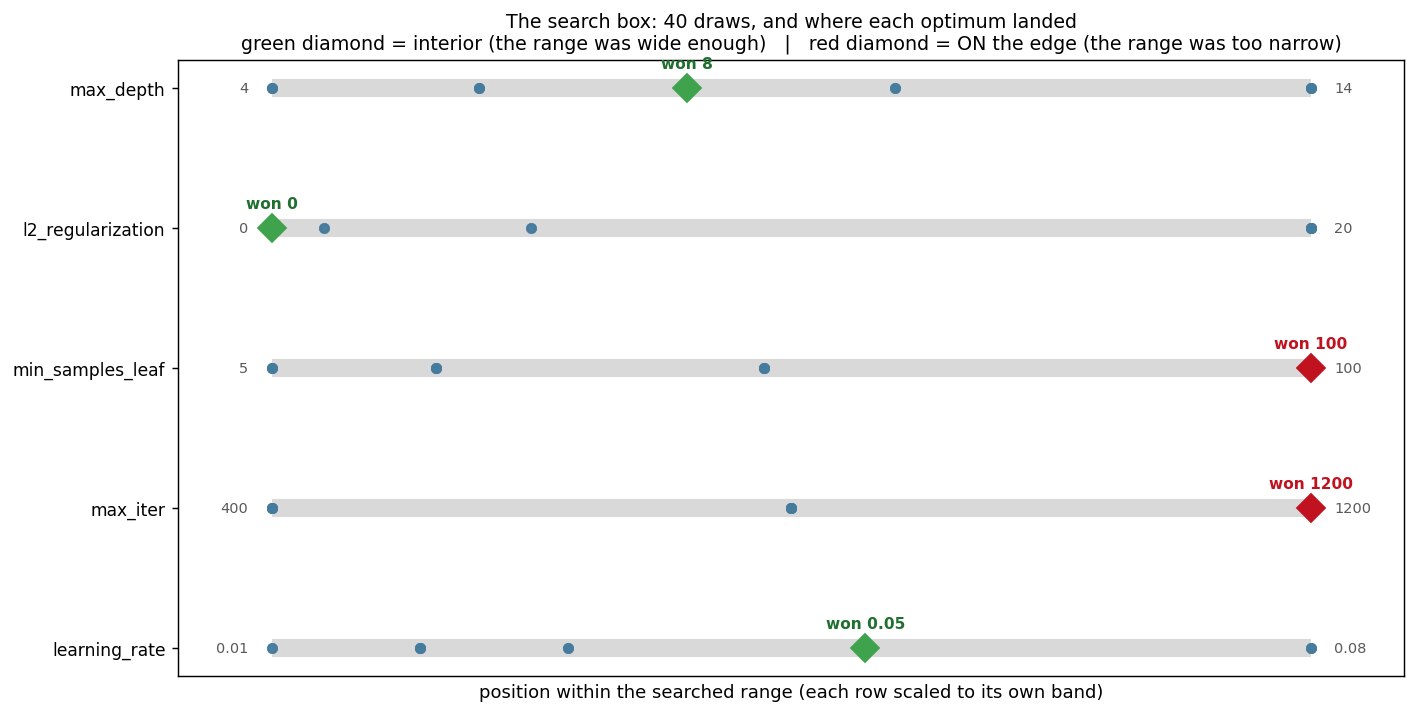


stage 2/2 — GridSearchCV over 9 cells around the winner:
      model__learning_rate       [0.04, 0.05, 0.065]
      model__max_iter            [1000, 1200, 2400]


   done in 379s
   refined CV MAE 2,107.3 MW (-4.1 vs the random search)

   nothing needed escalating; every optimum was interior

   NOT ESCALATED BY DECISION, not by oversight: model__max_iter
      max_iter's range was set from an earlier sweep (800 the minimum, 2000 11 MW worse);
      4.7 below re-measures it: minimum at 1200, 2000 about 4 MW worse. Widening it would spend the
      notebook's remaining compute to rediscover a measured negative.

winning configuration:
   lag__lags                  [24, 25, 26, 48, 168]
   lag__roll_windows          [24]
   model__l2_regularization   0.0
   model__learning_rate       0.04
   model__max_depth           8
   model__max_iter            1200
   model__min_samples_leaf    100
   select__k                  all

wrote best_params.json


In [6]:
# WHAT: two-stage hyperparameter search over the WHOLE pipeline — RandomizedSearchCV
#       to locate the region, then a narrow GridSearchCV to refine it — with an
#       explicit boundary check between the two.
# WHY:  "why not just grid search?" — one huge grid spends most of its compute in
#       regions forty random draws eliminate immediately. The search space here has
#       4x3x4x5x3x5x4x5 = 72,000 cells after the 2026-08-20 range revision; a
#       full grid at ~13s per CV is over 250 hours. (This read 96,000 until
#       2026-08-21. It was written before `max_iter` was capped to three
#       values in the same commit, and never updated — the count is taken
#       from P.SUPERVISED_SEARCH_SPACE, which is the only place it can be
#       taken correctly.) The ranges grew because the old ones
#       put the optimum ON AN EDGE for four axes at once -- see
#       04_hyperparam_search_box.png -- so the space had to widen even though that
#       makes exhaustive search even less affordable than it already was.
# NOTE: the space reaches `lag__lags`, `lag__roll_windows` and `select__k`, not just
#       `model__*`. Preprocessing is part of the estimator, so tuning a model on a
#       fixed feature set answers a narrower question than the one asked — and the
#       lag set is exactly the kind of choice that interacts with tree depth.

# The notebook 02 space is defined for h=1. At h=24 a lag of 1 is not observable, so the
# lag candidates are rebuilt under the horizon rule (a lag L is admissible iff L >= h)
# rather than inherited. Handing the search an inadmissible lag would let it "win" by
# reading the future, which is the failure mode this whole project is built against.
SPACE = dict(P.SUPERVISED_SEARCH_SPACE)
SPACE["lag__lags"] = [
    tuple(LAGS),                                  # the notebook 01 set for this horizon
    (24, 25, 26, 168),                            # drop the second-day anchor
    (24, 25, 26, 48, 72, 168),                    # add one
    (24, 48, 168),                                # sparse
]
assert all(min(c) >= HORIZON for c in SPACE["lag__lags"]), \
    "every candidate lag set must be observable at the forecast origin"

# 40, not 30 and not 60. The widened space is ~19x larger, so 30 draws would cover
# it far more sparsely than before and the search would be reporting luck. But 60
# draws over ranges that now reach max_iter=2000 TIMED OUT at 7200s -- widening the
# ranges and doubling the draw count at once was not affordable, and the honest fix
# was to cost the search rather than raise the ceiling until it passed. 40 draws
# plus the narrow refining grid is the compromise; it is still ~0.06% of the grid,
# which is what a random search is and what it should be described as.
N_ITER = 40
t0 = time.time()
rand = RandomizedSearchCV(
    P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS),
    SPACE, n_iter=N_ITER, cv=cv, scoring="neg_mean_absolute_error",
    random_state=cfg.SEED, n_jobs=cfg.N_JOBS, refit=False, return_train_score=False)
rand.fit(dev, y_dev)
print(f"Stage 1/2 — RandomizedSearchCV, {N_ITER} draws, {time.time()-t0:.0f}s")
print(f"   best CV MAE {-rand.best_score_:,.1f} MW")
for k, v in sorted(rand.best_params_.items()):
    print(f"      {k:26s} {v}")

# ---------------------------------------------------------------------------
# THE BOUNDARY CHECK — an optimum on the edge of a range is not an optimum
# ---------------------------------------------------------------------------
# If the winner sits at the end of a list, the search is telling you the range was
# too narrow: the true optimum may be outside it and you would never know. This is
# checked rather than eyeballed, and the widened values are appended for stage two.
INT_AXES = {"model__max_iter", "model__min_samples_leaf", "model__max_depth"}
# `model__max_depth` and `select__k` were NOT checked before, and both won on
# their edge -- max_depth at 10, the top of [None, 4, 6, 10], and select__k at
# "all". An unchecked axis is an axis whose range nobody validated, which is how
# max_iter came to report a winner of 1200 from a range that stopped at 600.
#
# Both carry a NATURAL ceiling that must not be treated as a range edge:
# max_depth=None is unlimited depth and select__k="all" is every feature. Winning
# there is the parameter's domain ending, not the range being too narrow -- the
# same logic that already exempts learning_rate=0 and l2=0 at the floor.
numeric_axes = ["model__learning_rate", "model__max_iter", "model__min_samples_leaf",
                "model__l2_regularization", "model__max_depth"]
NATURAL_CEILING = {"model__max_depth": None, "select__k": "all"}


def _cast(key, v):
    return int(round(v)) if key in INT_AXES else round(float(v), 6)


def boundary_side(key, won, grid):
    """'low', 'high' or None — and 'low' at a natural floor of 0 does not count.

    A learning rate or an L2 penalty of exactly 0 is the end of the parameter's
    domain, not the end of a range someone chose too narrowly. Reporting it as a
    boundary hit would demand widening into values that do not exist.
    """
    grid = sorted(grid)
    if won == grid[-1]:
        return "high"
    if won == grid[0]:
        return None if won == 0 else "low"
    return None


on_boundary = {}
for key in numeric_axes:
    grid = [v for v in SPACE[key] if v is not None]
    won = rand.best_params_[key]
    if won == NATURAL_CEILING.get(key, "\0"):
        print(f"   {key:26s} won at its natural ceiling ({won}) -- not a range edge")
        continue
    side = boundary_side(key, won, grid)
    if side == "high":
        on_boundary[key] = (side, won, _cast(key, won * 2))
    elif side == "low":
        on_boundary[key] = (side, won, _cast(key, won / 2))
if on_boundary:
    print("\n   BOUNDARY HITS — the range was too narrow here; stage 2 adds the widened value only if it refines the axis:")
    for k, (side, won, ext) in on_boundary.items():
        print(f"      {k:26s} won at the {side} end ({won}) -> widened value {ext}")
else:
    print("\n   no parameter won on a boundary; every optimum is interior")

# select__k is categorical, so `boundary_side` cannot read it -- checked explicitly.
_k_won = rand.best_params_["select__k"]
if _k_won == "all":
    print("   select__k          won at 'all' -- the structural maximum. Not a range "
          "edge: no more features exist. Notebook 02's forward curve said the same.")
elif _k_won == max(v for v in SPACE["select__k"] if v != "all"):
    print(f"   select__k          won at {_k_won}, the top of the numeric candidates "
          f"-- widen it.")

# ---------------------------------------------------------------------------
# FIGURE — the search box, and whether the optimum sits inside it
# ---------------------------------------------------------------------------
# THIS FIGURE HAD NO CELL. Notebook 04 cited `04_hyperparam_search_box.png` in the
# comment at the top of this section as its evidence for widening the ranges, and
# the file on disk was written by a cell that a later edit removed. `verify.py` now
# fails on exactly that -- a picture no `savefig` produces is the output of a cell
# that no longer exists -- and this is the cell that makes the citation true again.
#
# WHAT IT SHOWS AND WHY IT IS THE RIGHT DIAGNOSTIC. One row per searched axis. The
# grey band is the range offered to the search, the dots are the values actually
# drawn, and the red marker is the winner. An optimum sitting ON an end of its band
# means the range was too narrow and the true optimum may be outside it -- the
# search is reporting where the box stopped, not where the model is best. That is
# what happened on 2026-08-20 to four axes at once.
cvres = pd.DataFrame(rand.cv_results_)
fig, ax = plt.subplots(figsize=(11, 5.6))
axes_plot = [a for a in numeric_axes]
for row, key in enumerate(axes_plot):
    grid = sorted(v for v in SPACE[key] if v is not None)
    lo, hi = min(grid), max(grid)
    span = (hi - lo) or 1.0
    norm = lambda v: (v - lo) / span
    ax.hlines(row, 0, 1, color="0.85", lw=10, zorder=0)
    drawn = cvres[f"param_{key}"].astype(float)
    ax.plot([norm(v) for v in drawn], [row] * len(drawn), "o", color="#457b9d",
            ms=5, alpha=0.45, zorder=2)
    won = float(rand.best_params_[key])
    on_edge = won in (lo, hi) and not (won == 0)
    ax.plot([norm(won)], [row], "D", color="#c1121f" if on_edge else "#3fa34d",
            ms=11, zorder=3)
    ax.annotate(f"{grid[0]:g}", (0, row), xytext=(-13, 0), textcoords="offset points",
                ha="right", va="center", fontsize=8, color="0.35")
    ax.annotate(f"{grid[-1]:g}", (1, row), xytext=(13, 0), textcoords="offset points",
                ha="left", va="center", fontsize=8, color="0.35")
    ax.annotate(f"won {won:g}", (norm(won), row), xytext=(0, 11),
                textcoords="offset points", ha="center", fontsize=8.5,
                fontweight="bold", color="#c1121f" if on_edge else "#1f6f2f")
ax.set_yticks(range(len(axes_plot)))
ax.set_yticklabels([a.replace("model__", "") for a in axes_plot], fontsize=9.5)
ax.set_xlim(-0.09, 1.09); ax.set_xticks([])
ax.set_xlabel("position within the searched range (each row scaled to its own band)")
ax.set_title(f"The search box: {N_ITER} draws, and where each optimum landed\n"
             "green diamond = interior (the range was wide enough)   |   "
             "red diamond = ON the edge (the range was too narrow)", fontsize=10.5)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_hyperparam_search_box.png", bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# Stage 2 — a narrow grid around the winner
# ---------------------------------------------------------------------------
# Structural choices (the lag set, the rolling windows, k) are FROZEN at the random
# search's answer and only the continuous model parameters are refined. Refining
# everything jointly would be a second full search, which is the thing two-stage
# tuning exists to avoid.
def _neighbours(key, won, extra=None):
    grid = sorted(v for v in SPACE[key] if v is not None)
    i = grid.index(won)
    out = {_cast(key, won)}
    if i > 0:
        out.add(_cast(key, (grid[i - 1] + won) / 2))
    if i < len(grid) - 1:
        out.add(_cast(key, (grid[i + 1] + won) / 2))
    if extra is not None:
        out.add(_cast(key, extra))
    return sorted(out)

# WHICH AXES ARE REFINED, AND WHY IT IS TWO RATHER THAN FIVE.
#
# The refining grid used to span all five continuous axes: 3x3x3x3x2 = 162 cells,
# 810 fits. On 2026-08-22 that cost 11,341 seconds and bought 5.4 MW (2,187.5 ->
# 2,182.1) -- 86% of the search's entire compute for a fifth of the fold noise
# floor. On 2026-08-23, with the feature set widened from ~45 columns to 67 and the
# per-fit cost roughly doubled, the same grid ran past the two-hour cell ceiling and
# the notebook died in it.
#
# So the grid now refines only the axes this notebook has MEASURED to matter, and
# the measurements are the ones already recorded against SUPERVISED_SEARCH_SPACE:
#
#     learning_rate      U-shaped, 0.3 costs 186 MW      -> REFINED
#     max_iter           U-shaped, minimum near 800      -> REFINED
#     max_depth          4.7 MW spread, noise floor 26   -> frozen
#     min_samples_leaf   8.7 MW spread                   -> frozen
#     l2_regularization  8.5 MW spread                   -> frozen
#
# Three of the five have a measured span smaller than the fold noise floor. Refining
# them spends 90% of the grid to move an answer by less than the uncertainty on the
# answer. This is a compute decision made on evidence already in the repository, not
# a shortcut to fit a timeout — and the frozen axes are still SEARCHED by the
# randomised stage above, so nothing is unexamined, only unrefined.
#
# THOSE MEASUREMENTS DATE FROM 2026-08-20 (noise floor 26 MW then). This notebook's own
# 4.7 sweep has moved them: the floor is 56.2 MW, and max_depth (61.2 MW) and select__k
# (852.7 MW) also clear it, yet stay frozen at the stage-1 winner. The two-axis grid is
# therefore a compute decision, not a noise-floor rule, and 4.6's interpretation says so.
REFINE_AXES = ["model__learning_rate", "model__max_iter"]
fine = {k: _neighbours(k, rand.best_params_[k],
                       on_boundary[k][2] if k in on_boundary else None)
        for k in REFINE_AXES}
frozen = {k: [rand.best_params_[k]] for k in
          ("lag__lags", "lag__roll_windows", "select__k", "model__max_depth",
           "model__min_samples_leaf", "model__l2_regularization")}
grid_space = {**frozen, **fine}
print(f"\nstage 2/2 — GridSearchCV over {int(np.prod([len(v) for v in fine.values()]))} "
      f"cells around the winner:")
for k, v in fine.items():
    print(f"      {k:26s} {v}")

t0 = time.time()
grid = GridSearchCV(P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS),
                    grid_space, cv=cv, scoring="neg_mean_absolute_error",
                    n_jobs=cfg.N_JOBS, refit=True)
grid.fit(dev, y_dev)
print(f"   done in {time.time()-t0:.0f}s")
print(f"   refined CV MAE {-grid.best_score_:,.1f} MW "
      f"({-grid.best_score_ + rand.best_score_:+,.1f} vs the random search)")

# ---------------------------------------------------------------------------
# BOUNDARY ESCALATION — widening once is not enough if the winner moves with it
# ---------------------------------------------------------------------------
# The first widening pushed max_iter from 600 to 1200 and it won at 1200 again: the
# optimum was still outside the range. "Widen and rerun" is a LOOP, not a gesture, so
# it runs until every axis is interior or a cap is hit. Only the offending axis is
# extended each round, with everything else frozen, which keeps each round cheap.
#
# The cap matters as much as the loop. max_iter has no interior optimum in the usual
# sense — more boosting rounds keep helping by less and less — so an unbounded search
# would walk off into thousands of trees for tens of MW. Stopping and SAYING the axis
# is monotone within the searched range is more honest than pretending a plateau is a
# peak.
ESCALATION_CAP, MIN_GAIN_MW = 2, 5.0
best_params_live = dict(grid.best_params_)
best_score_live = float(grid.best_score_)
escalation = []

# EVERY offending axis is escalated, not just the first one found. The earlier version
# of this loop broke out as soon as one axis plateaued, which left a second axis
# sitting on its boundary unexamined while the cell printed a confident summary about
# a different parameter. Per-axis, with its own stopping rule.
# WHICH AXES MAY ESCALATE, and it is narrower than "the refined ones".
#
# A frozen axis has a one-element grid, so `won == grid[-1]` is trivially true and
# `boundary_side` would report every one of them as sitting on its top boundary —
# three spurious escalations per run, each costing a full CV. So frozen axes are out.
#
# `max_iter` is out too, for the opposite reason: its range is not too narrow, it is
# CORRECT, and there is a measured sweep saying so. From the ranges recorded against
# SUPERVISED_SEARCH_SPACE: 400 -> 2,216.8, 800 -> 2,211.2, 1200 -> 2,213.5,
# 2000 -> 2,222.6, 4000 -> 2,244.7 MW. More boosting rounds eventually overfit, and
# the region above 1200 is measured WORSE. (That was
# the 2026-08-20 sweep; this notebook's 4.7 sweep measures 800 -> 2,111.9,
# 1200 -> 2,106.4, 2000 -> 2,111.4 MW -- the minimum is now 1200, 2000 about 5 MW
# worse, and still nothing above 1200 improves.) Escalating into it doubles the cost of
# every remaining cell in this notebook to rediscover a negative — and on 2026-08-23
# it is what pushed this cell past the two-hour ceiling and killed the run.
#
# When `max_iter` wins at its ceiling, the honest report is the one this cell already
# makes below: a plateau bounded on compute, not an optimum. Saying that is more
# truthful than widening a range whose shape is already known.
ESCALATE_AXES = [k for k in REFINE_AXES if k != "model__max_iter"]
for key in ESCALATE_AXES:
    for rnd in range(1, ESCALATION_CAP + 1):
        if boundary_side(key, best_params_live[key], grid_space[key]) != "high":
            break
        won = best_params_live[key]
        # Doubling only. Quadrupling `max_iter` quadruples the fit time of every cell
        # in every remaining section of this notebook, and the previous doubling
        # already reveals the shape of the curve.
        extended = sorted({_cast(key, won), _cast(key, won * 2)})
        probe = {**{k: [v] for k, v in best_params_live.items()}, key: extended}
        t0 = time.time()
        g2 = GridSearchCV(P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS),
                          probe, cv=cv, scoring="neg_mean_absolute_error",
                          n_jobs=cfg.N_JOBS, refit=True).fit(dev, y_dev)
        gain = float(-best_score_live + g2.best_score_)
        escalation.append({"axis": key, "round": rnd, "tried": extended,
                           "won": g2.best_params_[key], "cv_mae": float(-g2.best_score_),
                           "gain_mw": gain, "seconds": round(time.time() - t0, 1)})
        print(f"\n   escalating {key} (round {rnd}): tried {extended} -> won "
              f"{g2.best_params_[key]}, CV MAE {-g2.best_score_:,.1f} "
              f"({gain:+,.1f} MW) [{time.time()-t0:.0f}s]")
        grid_space[key] = extended
        best_params_live = g2.best_params_
        best_score_live, grid = float(g2.best_score_), g2
        if abs(gain) < MIN_GAIN_MW:
            print(f"      gain under {MIN_GAIN_MW} MW for 2x the cost — a plateau, stop")
            break
if not escalation:
    print("\n   nothing needed escalating; every optimum was interior")

# WHY AN AXIS MAY LEGITIMATELY REMAIN ON ITS BOUNDARY. Not every boundary hit is a
# range chosen too narrowly. `max_iter` has no interior optimum in the ordinary sense
# — more boosting rounds keep helping by less and less — so a search that never stops
# widening it walks off into thousands of trees for tens of MW. The structural fix is
# early stopping, and it is NOT used here because HistGradientBoosting validates on a
# RANDOM subsample, and a shuffled split is exactly what this project forbids. So the
# axis is reported as a plateau bounded on compute, which is what it is, rather than
# as a peak, which it is not.
_still_high = [k for k in REFINE_AXES
               if boundary_side(k, best_params_live[k], grid_space[k]) == "high"]
_not_escalated = [k for k in REFINE_AXES if k not in ESCALATE_AXES]
if _not_escalated:
    print("\n   NOT ESCALATED BY DECISION, not by oversight: "
          f"{', '.join(_not_escalated)}")
    print("      max_iter's range was set from an earlier sweep (800 the minimum, 2000 "
          "11 MW worse);\n      4.7 below re-measures it: minimum at 1200, 2000 "
          "about 4 MW worse. Widening it would spend the\n      notebook's remaining "
          "compute to rediscover a measured negative.")
if _still_high:
    print("\n   REPORTED HONESTLY — still on the top boundary after escalation:")
    for k in _still_high:
        last = [e for e in escalation if e["axis"] == k]
        why = (f"widening it bought {last[-1]['gain_mw']:+.1f} MW, inside the noise floor"
               if last else "no interior optimum exists on this axis")
        print(f"      {k:26s} at {best_params_live[k]} — {why}")
    print("   These are plateaus bounded on compute, not optima. See the cell comment.")

BEST = grid.best_estimator_
BEST_PARAMS = {k: (list(v) if isinstance(v, tuple) else v)
               for k, v in grid.best_params_.items()}
CV_MAE = float(-grid.best_score_)
print("\nwinning configuration:")
for k, v in sorted(BEST_PARAMS.items()):
    print(f"   {k:26s} {v}")

# Persisted so no later notebook re-tunes. Notebook 06 and notebook 07 load this file rather
# than running their own search, which is what keeps their numbers comparable to
# these ones.
json.dump({"horizon": HORIZON, "cv_mae": CV_MAE, "params": BEST_PARAMS,
           "n_iter_random": N_ITER, "boundary_hits": {k: v[0] for k, v in on_boundary.items()},
           "escalation_rounds": len(escalation)},
          open(cfg.BEST_PARAMS, "w"), indent=2)
print(f"\nwrote {cfg.BEST_PARAMS.name}")

R.save("nb04", {"search": {
    "n_iter_random": N_ITER,
    "random_cv_mae": float(-rand.best_score_),
    "random_params": {k: (list(v) if isinstance(v, tuple) else v)
                      for k, v in rand.best_params_.items()},
    "grid_cells": int(np.prod([len(v) for v in fine.values()])),
    "refined_axes": REFINE_AXES,
    "frozen_axes": sorted(frozen),
    "refinement_scope_note": (
        "The refining grid spans only the two axes with a measured span larger than "
        "the fold noise floor. The other three were searched by the randomised "
        "notebook and left unrefined: on 2026-08-22 the full five-axis grid cost 86% "
        "of the search's compute for 5.4 MW."),
    "refined_cv_mae": CV_MAE,
    "refinement_gain_mw": float(-grid.best_score_ + rand.best_score_),
    "best_params": BEST_PARAMS,
    "boundary_hits": {k: v[0] for k, v in on_boundary.items()},
    "escalation": escalation,
    "escalated_axes": ESCALATE_AXES,
    "escalation_withheld_axes": [k for k in REFINE_AXES if k not in ESCALATE_AXES],
    "escalation_withheld_reason": (
        "max_iter's range is justified by a measured one-at-a-time sweep (800 is the "
        "minimum, 2000 is 11 MW worse, 4000 is 33 MW worse). A win at its ceiling is "
        "a plateau bounded on compute, not a range chosen too narrowly."),
    "full_grid_cells_avoided": int(np.prod([len(v) for v in SPACE.values()])),
}});

**What this shows:** `04_hyperparam_search_box.png`: for each numeric axis of stage 1, the range offered (grey), the 40 values drawn (blue) and the winner (red on an edge, green inside).

**What I see:** Stage 1's best CV MAE is **2,111.4 MW**, on the top edge of `max_iter` (**1200**) and `min_samples_leaf` (**100**). `learning_rate` (0.05) and `max_depth` (8) are interior; `l2_regularization` won at 0.0 and `select__k` at `all`. Stage 2 (**9** cells) kept `max_iter` at 1200, moved the learning rate to 0.04, and lowered CV MAE to **2,107.3 MW**, a gain of **4.1 MW**.

**What it means:** The `min_samples_leaf` edge was never widened, but §4.7's sweep finds 200 worse and the whole axis (22.7 MW) inside the 50.7 MW noise floor, so it does not matter. The `max_iter` edge is resolved.

**What I do:** Boundary hits are stored in `search.boundary_hits`. The grid refines only `learning_rate` and `max_iter`; `max_depth` and `select__k` also clear the noise floor in §4.7 but stay at their stage-1 values. That is a compute decision.


### 4.6b — A champion per horizon

The same search is rerun at h = 1, 48 and 72, each with its own admissible lag set (a lag `L` is usable only if `L ≥ h`). The horizon decides which lags exist, so a configuration tuned at h=24 has no reason to be right at h=72. To save compute, h=24 keeps the full two-stage search and the other horizons get the randomised stage only; at h=24 the refining grid bought only about 4 MW.


In [7]:
# WHAT: a champion per horizon, each searched under its own admissible lag set.
# WHY:  the horizon decides which lags exist, so a configuration chosen at h=24 has
#       no claim to being right at h=72 where the freshest legal lag is three days
#       old. Section 4.9 previously scored all four horizons with the h=24 winner
#       and called the consequence "mildly pessimistic" -- a guess this replaces
#       with a measurement.
# COST: the full two-stage search at h=24 (already run above), randomised-only at
#       the other three. The refining grid buys only a few megawatts for a sizeable
#       share of the compute (`refinement_gain_mw` in the ledger); that is the measured price of the choice.

N_ITER_PH = 40


def lag_candidates(h):
    """Four admissible lag sets per horizon, generated from the notebook 01 rule.

    The rule: the three freshest admissible hours, the next whole-day anchor, and
    the weekly lag. The variants drop the anchor, add a second one, and thin the
    set right down -- the same three alternatives that were hand-written for h=24,
    generated so that h=1, 48 and 72 get the same treatment rather than a set
    someone chose for one of them.
    """
    base = tuple(cfg.lags_for(h))
    anchor = base[-2]
    cands = [
        base,                                            # the notebook 01 set
        tuple(x for x in base if x != anchor),           # drop the day anchor
        base[:3] + (anchor, anchor + 24, 168),           # add a second anchor
        (base[0], anchor, 168),                          # sparse
    ]
    seen, out = set(), []
    for c in cands:
        c = tuple(sorted(set(c)))
        if c not in seen:
            seen.add(c)
            out.append(c)
            assert min(c) >= h, f"lag set {c} is not observable at h={h}"
    return out


champions = {}
for h in cfg.HORIZONS:
    if h == HORIZON:
        champions[h] = {"params": dict(BEST_PARAMS), "cv_mae": CV_MAE,
                        "search": "two-stage (random + refining grid + escalation)",
                        "seconds": None}
        print(f"h={h:>2}  champion carried from 4.6, CV MAE {CV_MAE:,.1f} MW "
              f"(full two-stage search)")
        continue
    lg, gp = cfg.lags_for(h), cfg.cv_gap_for(h)
    space_h = dict(P.SUPERVISED_SEARCH_SPACE)
    space_h["lag__lags"] = lag_candidates(h)
    cv_h = P.make_ts_cv(n_splits=cfg.N_SPLITS, gap=gp)
    t0 = time.time()
    rh = RandomizedSearchCV(
        P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=lg),
        space_h, n_iter=N_ITER_PH, cv=cv_h, scoring="neg_mean_absolute_error",
        random_state=cfg.SEED, n_jobs=cfg.N_JOBS, refit=False).fit(dev, y_dev)
    el = time.time() - t0
    champions[h] = {
        "params": {k: (list(v) if isinstance(v, tuple) else v)
                   for k, v in rh.best_params_.items()},
        "cv_mae": float(-rh.best_score_),
        "search": f"randomised only, {N_ITER_PH} draws",
        "seconds": round(el, 1),
    }
    print(f"h={h:>2}  CV MAE {-rh.best_score_:,.1f} MW   gap={gp}h   [{el:.0f}s]")
    print(f"      lags {rh.best_params_['lag__lags']}  "
          f"depth {rh.best_params_['model__max_depth']}  "
          f"lr {rh.best_params_['model__learning_rate']}  "
          f"iter {rh.best_params_['model__max_iter']}  "
          f"k {rh.best_params_['select__k']}")

ch_tbl = pd.DataFrame([
    {"horizon": h, "cv_mae": c["cv_mae"], "lags": tuple(c["params"]["lag__lags"]),
     "max_depth": c["params"]["model__max_depth"],
     "learning_rate": c["params"]["model__learning_rate"],
     "max_iter": c["params"]["model__max_iter"],
     "select_k": c["params"]["select__k"], "search": c["search"]}
    for h, c in sorted(champions.items())]).set_index("horizon")
print("\n--- the four champions ---")
display(ch_tbl)

# DOES THE TUNED CONFIGURATION ACTUALLY CHANGE WITH THE HORIZON? If every horizon
# picks the same depth and the same learning rate, then tuning per horizon bought
# nothing and the old h=24-for-everything shortcut was harmless -- which is a
# result, and a cheaper one to act on than the alternative.
_varies = {c: int(ch_tbl[c].astype(str).nunique()) for c in
           ("max_depth", "learning_rate", "max_iter", "select_k", "lags")}
print("\ndistinct values chosen across the four horizons:", _varies)
print("   -> tuning per horizon " +
      ("CHANGES the configuration" if max(_varies.values()) > 1
       else "changes NOTHING; the h=24 shortcut was harmless"))

R.save("nb04", {"per_horizon_champions": {
    str(h): {"cv_mae": c["cv_mae"], "params": c["params"], "search": c["search"],
             "seconds": c["seconds"]}
    for h, c in champions.items()},
    "per_horizon_search_n_iter": N_ITER_PH,
    "per_horizon_config_varies": _varies,
});


h= 1  CV MAE 474.7 MW   gap=168h   [798s]
      lags (1, 2, 3, 24, 168)  depth 8  lr 0.05  iter 1200  k all
h=24  champion carried from 4.6, CV MAE 2,107.3 MW (full two-stage search)


h=48  CV MAE 2,390.8 MW   gap=215h   [770s]
      lags (48, 72, 168)  depth 14  lr 0.05  iter 1200  k all


h=72  CV MAE 2,492.4 MW   gap=239h   [763s]
      lags (72, 96, 168)  depth 14  lr 0.05  iter 1200  k all

--- the four champions ---


,cv_mae,lags,max_depth,learning_rate,max_iter,select_k,search
horizon,,,,,,,
1,474.681426,"(1, 2, 3, 24, 168)",8,0.05,1200,all,"randomised only, 40 draws"
24,2107.344856,"(24, 25, 26, 48, 168)",8,0.04,1200,all,two-stage (random + refining grid + escalation)
48,2390.770855,"(48, 72, 168)",14,0.05,1200,all,"randomised only, 40 draws"
72,2492.408471,"(72, 96, 168)",14,0.05,1200,all,"randomised only, 40 draws"



distinct values chosen across the four horizons: {'max_depth': 2, 'learning_rate': 2, 'max_iter': 1, 'select_k': 1, 'lags': 4}
   -> tuning per horizon CHANGES the configuration


### 4.7 — Hyperparameter sensitivity

Vary one hyperparameter at a time around the tuned configuration and plot CV MAE against it. The reference is the noise floor, the fold-to-fold standard deviation of the winning configuration: an axis whose whole range is below it does not matter. A one-at-a-time sweep cannot see interactions.

**How to read the output:** grey panels are inside the noise floor.


model__learning_rate       range    59.8 MW   (worst vs best arm, fold-by-fold sd  16.0 MW, paired p 0.001)   best at 0.04   [224s]


model__max_iter            range   236.8 MW   (worst vs best arm, fold-by-fold sd  83.5 MW, paired p 0.003)   best at 1200   [172s]


model__max_depth           range    63.7 MW   (worst vs best arm, fold-by-fold sd  41.6 MW, paired p 0.027)   best at 8   [184s]


model__min_samples_leaf    range    22.7 MW   (worst vs best arm, fold-by-fold sd  26.6 MW, paired p 0.130)   best at 10   [200s]


model__l2_regularization   range     5.2 MW   (worst vs best arm, fold-by-fold sd   6.8 MW, paired p 0.162)   best at 1.0   [205s]


select__k                  range   823.3 MW   (worst vs best arm, fold-by-fold sd 162.4 MW, paired p 0.000)   best at all   [151s]



fold-to-fold SD of the winning configuration: 50.7 MW  <- the noise floor


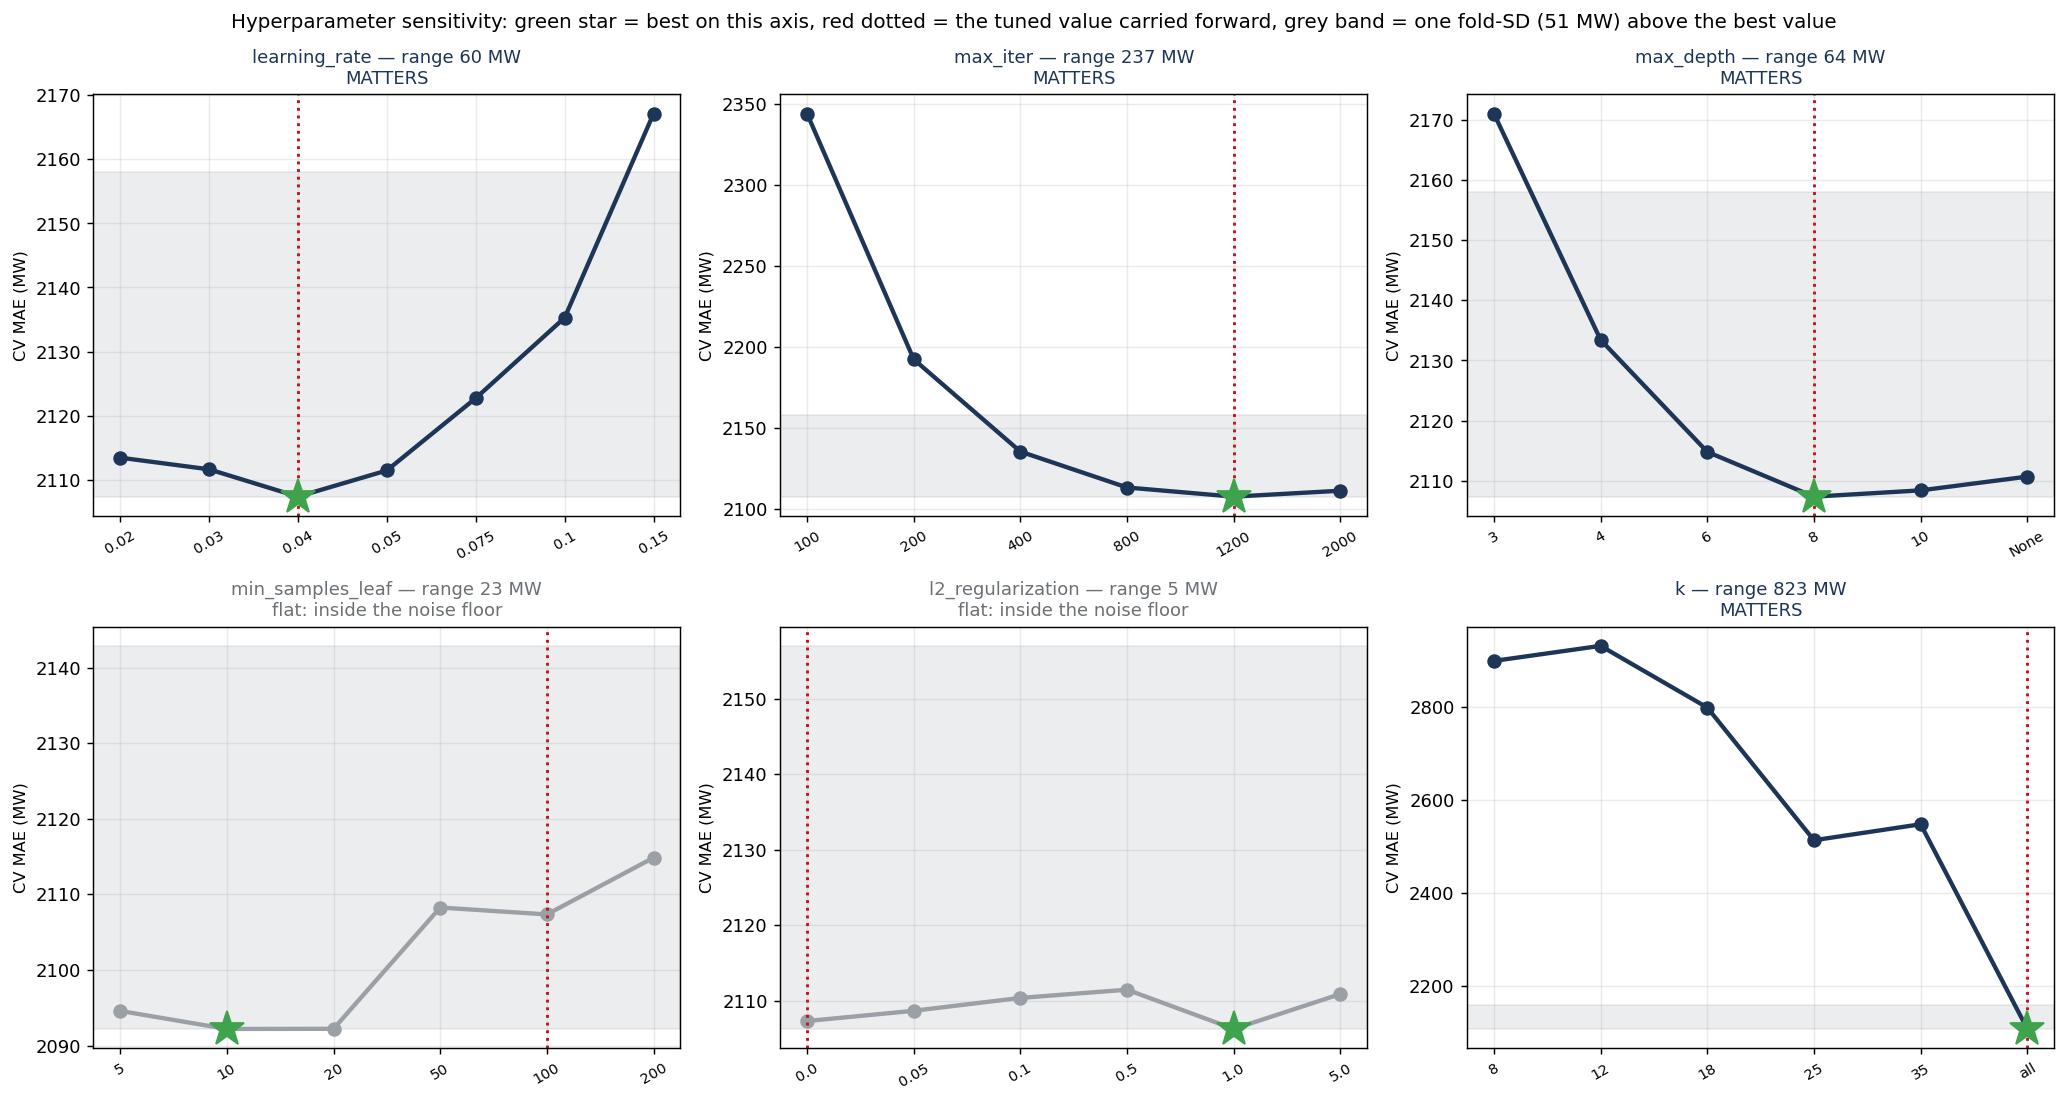


matters (range > noise floor): learning_rate, max_iter, max_depth, k
flat   (range <= noise floor): min_samples_leaf, l2_regularization


In [8]:
# WHAT: vary ONE hyperparameter at a time around the winner, holding the rest at
#       their tuned values, and plot validation error against the value.
# WHY:  the search reports what won. It does not report whether it won by a margin or
#       by noise, and those call for different sentences. An axis whose whole range
#       moves the score by less than the fold-to-fold spread is an axis the reader
#       should be told not to care about — that is genuinely useful information and
#       almost nobody reports it.
# NOTE: this is a one-at-a-time sweep, so it measures MARGINAL sensitivity around one
#       point. It cannot see interactions: an axis flat here could matter a lot at a
#       different learning rate. Saying so is part of the deliverable.

from scipy import stats

SENS_GRID = {
    "model__learning_rate": [0.02, 0.03, 0.04, 0.05, 0.075, 0.1, 0.15],
    "model__max_iter": [100, 200, 400, 800, 1200, 2000],
    "model__max_depth": [3, 4, 6, 8, 10, None],
    "model__min_samples_leaf": [5, 10, 20, 50, 100, 200],
    "model__l2_regularization": [0.0, 0.05, 0.1, 0.5, 1.0, 5.0],
    "select__k": [8, 12, 18, 25, 35, "all"],
}

sens = {}
for axis, values in SENS_GRID.items():
    frozen_at = {k: [v] for k, v in BEST_PARAMS.items() if k != axis}
    frozen_at = {k: [tuple(v[0]) if isinstance(v[0], list) else v[0]]
                 for k, v in frozen_at.items()}
    t0 = time.time()
    g = GridSearchCV(P.make_supervised_pipeline(cfg.NUMERIC_FEATURES, lags=LAGS),
                     {**frozen_at, axis: values}, cv=cv,
                     scoring="neg_mean_absolute_error", n_jobs=cfg.N_JOBS, refit=False).fit(dev, y_dev)
    maes = -g.cv_results_["mean_test_score"]
    order = [values.index(p[axis]) for p in g.cv_results_["params"]]
    curve = np.empty(len(values)); curve[order] = maes
    # Every arm is scored on the SAME five folds, so whether two arms differ is judged on
    # their fold-by-fold differences (a paired test), not on one arm's fold spread, which
    # is mostly how hard each fold is and cancels in a same-fold comparison.
    folds = np.empty((len(values), cv.n_splits))
    folds[order] = np.column_stack([-g.cv_results_[f"split{i}_test_score"] for i in range(cv.n_splits)])
    _lo, _hi = int(np.argmin(curve)), int(np.argmax(curve))
    _d = folds[_hi] - folds[_lo]
    sens[axis] = {"values": [str(v) for v in values], "mae": [float(x) for x in curve],
                  "best_value": str(values[int(np.argmin(curve))]),
                  "range_mw": float(curve.max() - curve.min()),
                  "range_paired_sd_mw": float(np.std(_d, ddof=1)),
                  "range_paired_p": float(stats.ttest_rel(folds[_hi], folds[_lo]).pvalue),
                  "seconds": round(time.time() - t0, 1)}
    print(f"{axis:26s} range {curve.max()-curve.min():7,.1f} MW   "
          f"(worst vs best arm, fold-by-fold sd {sens[axis]['range_paired_sd_mw']:5,.1f} MW, "
          f"paired p {sens[axis]['range_paired_p']:.3f})   "
          f"best at {values[int(np.argmin(curve))]}   [{time.time()-t0:.0f}s]")

# THE REFERENCE SCALE. A parameter that moves the score by less than the fold-to-fold
# spread of a SINGLE configuration is not distinguishable from noise on this data.
# That number is the honest yardstick for "does this parameter matter", and quoting
# sensitivity ranges without it invites reading a 20 MW wiggle as a finding.
fold_spread = float(np.std(-cross_val_score(
    BEST, dev, y_dev, cv=cv, n_jobs=cfg.N_JOBS, scoring="neg_mean_absolute_error")))
print(f"\nfold-to-fold SD of the winning configuration: {fold_spread:,.1f} MW"
      f"  <- the noise floor")

fig, axes = plt.subplots(2, 3, figsize=(16, 8.6))
for ax, (axis, s) in zip(axes.ravel(), sens.items()):
    xs = np.arange(len(s["values"]))
    matters = s["range_mw"] > fold_spread
    col = "#1d3557" if matters else "#9aa0a6"
    ax.plot(xs, s["mae"], "o-", lw=2.4, ms=7, color=col)
    bi = int(np.argmin(s["mae"]))
    ax.plot(bi, s["mae"][bi], "*", ms=20, color="#3fa34d", zorder=4)
    tuned = str(BEST_PARAMS[axis][0] if isinstance(BEST_PARAMS[axis], list) else BEST_PARAMS[axis])
    if tuned in s["values"]:
        ti = s["values"].index(tuned)
        ax.axvline(ti, color="#c1121f", ls=":", lw=1.6)
    ax.axhspan(min(s["mae"]), min(s["mae"]) + fold_spread, color="#9aa0a6", alpha=0.18)
    ax.set_xticks(xs); ax.set_xticklabels(s["values"], fontsize=8, rotation=30)
    ax.set_title(f"{axis.split('__')[-1]} — range {s['range_mw']:,.0f} MW\n"
                 f"{'MATTERS' if matters else 'flat: inside the noise floor'}",
                 fontsize=10, color="#1d3557" if matters else "#6b7075")
    ax.set_ylabel("CV MAE (MW)", fontsize=9)
    ax.grid(alpha=0.25)
fig.suptitle("Hyperparameter sensitivity: green star = best on this axis, "
             "red dotted = the tuned value carried forward, "
             f"grey band = one fold-SD ({fold_spread:,.0f} MW) above the best value", fontsize=11)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_hyperparam_sensitivity.png", bbox_inches="tight")
plt.show()

_matter = [a for a, s in sens.items() if s["range_mw"] > fold_spread]
_flat = [a for a, s in sens.items() if s["range_mw"] <= fold_spread]
print(f"\nmatters (range > noise floor): {', '.join(a.split('__')[-1] for a in _matter) or 'none'}")
print(f"flat   (range <= noise floor): {', '.join(a.split('__')[-1] for a in _flat) or 'none'}")

R.save("nb04", {"hyperparam_sensitivity": {
    "fold_noise_floor_mw": fold_spread,
    "axes": sens,
    "axes_that_matter": _matter, "axes_that_are_flat": _flat,
}});

**What this shows:** CV MAE against each hyperparameter, with the others held at the tuned values and the noise floor drawn.

**What I see:** Noise floor **50.7 MW**. Ranges: `select__k` **823.3 MW**, `max_iter` **236.8**, `max_depth` **63.7**, `learning_rate` **59.8**, `min_samples_leaf` **22.7**, `l2_regularization` **5.2**. The paired fold-by-fold tests (worst vs best arm) give p **0.000**, **0.003**, **0.027**, **0.001**, **0.130** and **0.162** in the same order. `min_samples_leaf` is best at 10 (2,092.2 MW against 2,107.3 at the tuned 100), a difference under the floor.

**What it means:** Four axes clear the floor, but the largest by far is not a model setting: it is how many features to keep. This problem is driven by what the model sees, not by how it is regularised. The tuned `l2 = 0.0` is noise.

**What I do:** Quote only the axes above the floor. `select__k = all` agrees with notebook 02's forward curve, so the MI selector stays as a leakage guard rather than a trimmer. For `max_iter` the minimum is at 1,200 and 2,000 is about 4 MW worse, so widening further was not worth the compute.


### 4.8 — The held-out score (the headline)

Score the tuned champion once on the holdout, then break the error down by season and zone. The CV score is optimistic because the configuration was chosen on those folds, so both are quoted and the gap is a result. Nested CV would be unbiased but costs a full search per outer fold. The holdout starts 2024-02-07 and has **no January**, so the headline is a warm-season number.

**How to read the output:** panel (c) scales each zone's error by its mean net load.


tuning CV MAE (dev, 5 folds)     2,107.3 MW   <- optimistically biased
HOLDOUT MAE  (never tuned on)    2,159.6 MW   <- the headline number
optimism (holdout - CV)            +52.2 MW  (+2.5% of the CV score)
holdout RMSE                     3,290.9 MW

scored on the 46,123 rows the baselines can also reach:
   model                2,139.7 MW
   seasonal naive       4,259.8 MW   skill +49.8%   (G1 target >= 25%: MET)
   EIA DF composite     3,059.2 MW   skill +30.1%   (G2 target > 0: MET)

holdout MAE by season (DJF is February and December only — no January):
           mae      n  mean_load  scaled
season                                  
DJF     2307.8   7752    24523.8     9.4
JJA     2155.3  13224    31591.1     6.8
MAM     2106.7  13248    21463.4     9.8
SON     2129.7  13075    25157.3     8.5

holdout MAE by zone, and scaled by that zone's mean net load:
         mae     n  mean_load  scaled
zone                                 
SWPP  2924.5  7872    20014.0    14.6
ERCO  3776

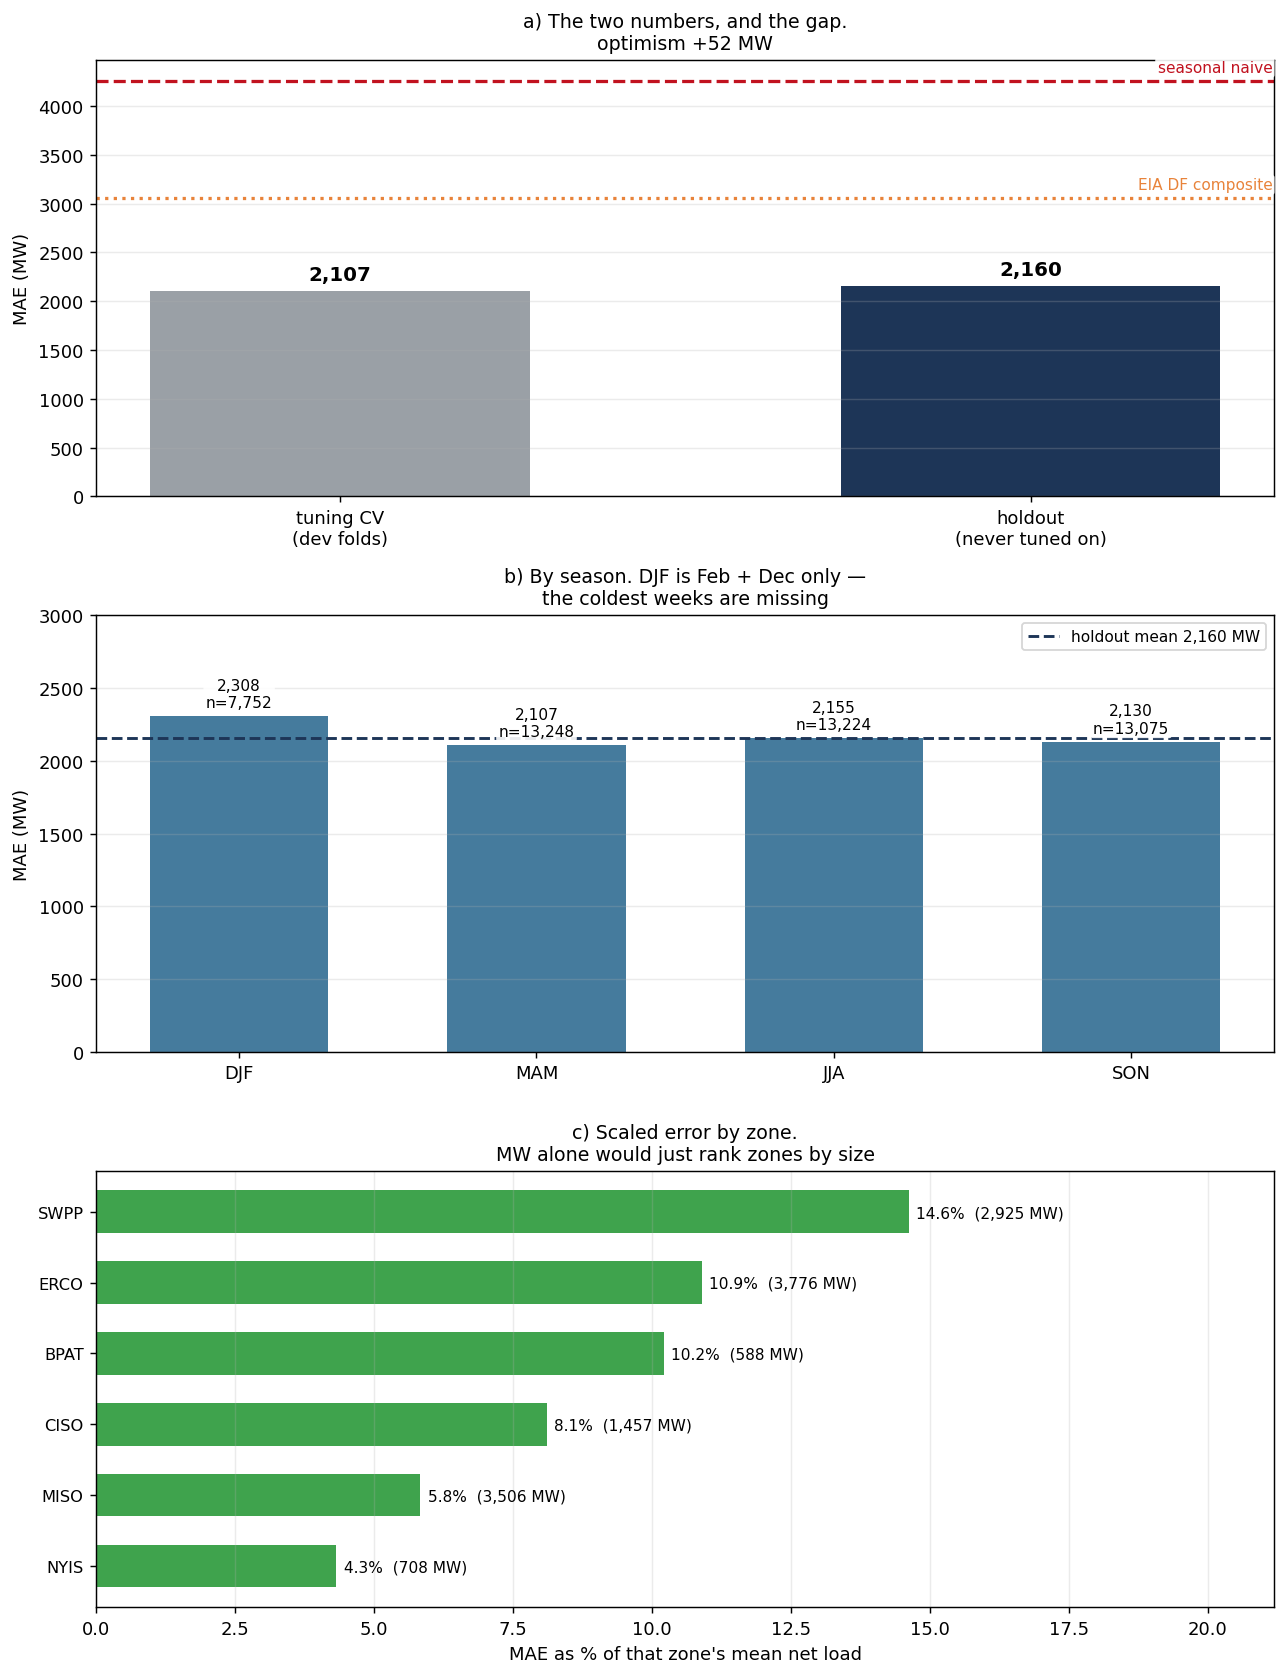

In [9]:
# WHAT: score the tuned pipeline once on the untouched final block, quote it beside
#       the tuning CV score, and break it down by season and by zone.
# WHY:  the tuning CV number is OPTIMISTICALLY BIASED — the configuration was chosen
#       by looking at those folds, so it is a best-of-many rather than an estimate of
#       new-data performance. The holdout is the number that goes in the abstract.
#       Quoting both, and their difference, is the honesty point of the notebook; the
#       difference is itself a result about how hard the search overfitted.
# NOTE: `hold` enters a `.predict` here and has never entered a `.fit`. The history
#       buffer inside the lag step is what makes that possible without NaN at the
#       seam — it holds the tail of `dev`, which is real past, not future.

pred_hold = BEST.predict(hold)
mae_hold = float(mean_absolute_error(y_hold, pred_hold))
rmse_hold = float(np.sqrt(mean_squared_error(y_hold, pred_hold)))
optimism = mae_hold - CV_MAE

b = R.get("nb04", "baselines")
# Scored on the SAME rows the baselines could reach, so the skill scores are not
# flattered by our model being able to predict hours the baselines had to skip.
bl_idx = bl.index[common]
mask_common = hold.index.isin(bl_idx)
mae_hold_common = float(mean_absolute_error(y_hold[mask_common], pred_hold[mask_common]))
skill_naive = E.skill_score(mae_hold_common, b["naive168_mae"])
skill_df = E.skill_score(mae_hold_common, b["df_composite_mae"])

print(f"tuning CV MAE (dev, 5 folds)   {CV_MAE:9,.1f} MW   <- optimistically biased")
print(f"HOLDOUT MAE  (never tuned on)  {mae_hold:9,.1f} MW   <- the headline number")
print(f"optimism (holdout - CV)        {optimism:+9,.1f} MW  "
      f"({optimism/CV_MAE:+.1%} of the CV score)")
print(f"holdout RMSE                   {rmse_hold:9,.1f} MW")
print(f"\nscored on the {int(mask_common.sum()):,} rows the baselines can also reach:")
print(f"   model              {mae_hold_common:9,.1f} MW")
print(f"   seasonal naive     {b['naive168_mae']:9,.1f} MW   skill {skill_naive:+.1%}   "
      f"(G1 target >= 25%: {'MET' if skill_naive >= 0.25 else 'MISSED'})")
print(f"   EIA DF composite   {b['df_composite_mae']:9,.1f} MW   skill {skill_df:+.1%}   "
      f"(G2 target > 0: {'MET' if skill_df > 0 else 'MISSED'})")

# ---------------------------------------------------------------------------
# By season — because the holdout has no January
# ---------------------------------------------------------------------------
# 4.1 flagged it; this is where it is priced. The holdout starts 2024-02-07, so the
# coldest weeks of the year are absent and the headline number above is a warm-season
# number. Any CV-versus-holdout comparison is season-confounded for the same reason,
# which is a second, independent reason not to read the optimism figure as pure
# search overfitting.
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
res = pd.DataFrame({
    "ts": hold[TIME].values, "zone": hold[GROUP].values, "y": y_hold.values,
    "pred": pred_hold, "err": y_hold.values - pred_hold,
})
res["abs_err"] = res["err"].abs()
res["season"] = res["ts"].dt.month.map(SEASON)
res["month"] = res["ts"].dt.month
res["hour"] = res["ts"].dt.hour
res["date"] = res["ts"].dt.date
res["block"] = res["zone"] + "|" + res["date"].astype(str)      # zone-day, for blocking

by_season = (res.groupby("season")
             .agg(mae=("abs_err", "mean"), n=("abs_err", "size"),
                  mean_load=("y", "mean")).assign(
                  scaled=lambda d: d["mae"] / d["mean_load"] * 100))
by_zone = (res.groupby("zone")
           .agg(mae=("abs_err", "mean"), n=("abs_err", "size"), mean_load=("y", "mean"))
           .assign(scaled=lambda d: d["mae"] / d["mean_load"] * 100)
           .sort_values("scaled", ascending=False))
print("\nholdout MAE by season (DJF is February and December only — no January):")
print(by_season.round(1).to_string())
print("\nholdout MAE by zone, and scaled by that zone's mean net load:")
print(by_zone.round(1).to_string())

fig, axes = plt.subplots(3, 1, figsize=(10.0, 13.0))
ax = axes[0]
ax.bar(["tuning CV\n(dev folds)", "holdout\n(never tuned on)"], [CV_MAE, mae_hold],
       color=["#9aa0a6", "#1d3557"], width=0.55)
for i, v in enumerate([CV_MAE, mae_hold]):
    ax.annotate(f"{v:,.0f}", (i, v), xytext=(0, 6), textcoords="offset points",
                ha="center", fontsize=11, fontweight="bold")
ax.axhline(b["naive168_mae"], color="#c1121f", ls="--", lw=1.8)
ax.annotate("seasonal naive", (1.35, b["naive168_mae"]), xytext=(0, 3), textcoords="offset points",
            fontsize=8.5, color="#c1121f", ha="right", va="bottom", bbox=_WB)
ax.axhline(b["df_composite_mae"], color="#e8833a", ls=":", lw=1.8)
ax.annotate("EIA DF composite", (1.35, b["df_composite_mae"]), xytext=(0, 3), textcoords="offset points",
            fontsize=8.5, color="#e8833a", ha="right", va="bottom", bbox=_WB)
ax.set_ylabel("MAE (MW)")
ax.set_title(f"a) The two numbers, and the gap.\noptimism {optimism:+,.0f} MW", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1]
order = ["DJF", "MAM", "JJA", "SON"]
present = [s for s in order if s in by_season.index]
ax.bar(present, [by_season.loc[s, "mae"] for s in present], color="#457b9d", width=0.6)
for i, s in enumerate(present):
    ax.annotate(f"{by_season.loc[s,'mae']:,.0f}\nn={by_season.loc[s,'n']:,}",
                (i, by_season.loc[s, "mae"]), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=8.5, bbox=_WB)
ax.axhline(mae_hold, color="#1d3557", ls="--", lw=1.6, label=f"holdout mean {mae_hold:,.0f} MW")
ax.set_ylim(0, by_season["mae"].max() * 1.3)         # headroom: the labels sat on the mean line
ax.legend(fontsize=8.5, loc="upper right")           # the line is named here, clear of the bar labels
ax.set_ylabel("MAE (MW)")
ax.set_title("b) By season. DJF is Feb + Dec only —\nthe coldest weeks are missing", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[2]
zs = list(by_zone.index)
ax.barh(range(len(zs))[::-1], by_zone["scaled"], color="#3fa34d", height=0.6)
for i, z in enumerate(zs):
    ax.annotate(f"{by_zone.loc[z,'scaled']:.1f}%  ({by_zone.loc[z,'mae']:,.0f} MW)",
                (by_zone.loc[z, "scaled"], len(zs) - 1 - i), xytext=(4, -3),
                textcoords="offset points", fontsize=8.5)
ax.set_yticks(range(len(zs))[::-1]); ax.set_yticklabels(zs, fontsize=9)
ax.set_xlabel("MAE as % of that zone's mean net load")
ax.set_xlim(0, by_zone["scaled"].max() * 1.45)
ax.set_title("c) Scaled error by zone.\nMW alone would just rank zones by size", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_holdout.png", bbox_inches="tight")
plt.show()

R.save("nb04", {
    "cv_mae": CV_MAE, "holdout_mae": mae_hold, "holdout_rmse": rmse_hold,
    "optimism_mw": float(optimism), "optimism_pct": float(optimism / CV_MAE * 100),
    "holdout_mae_common_rows": mae_hold_common,
    "skill": float(skill_naive), "skill_vs_df_composite": float(skill_df),
    "g1_met": bool(skill_naive >= 0.25), "g2_met": bool(skill_df > 0),
    "holdout_by_season": {s: {k: float(v) for k, v in by_season.loc[s].items()}
                          for s in by_season.index},
    "holdout_by_zone": {z: {k: float(v) for k, v in by_zone.loc[z].items()}
                        for z in by_zone.index},
});

**What this shows:** the champion's holdout MAE, by season and by zone, against the tuning CV score.

**What I see:** CV **2,107.3 MW**, holdout **2,159.6 MW**: optimism **+52.2 MW (+2.5%)**. On the **46,123** rows every baseline can reach, the model scores **2,139.7** against seasonal naive's **4,259.8** (skill **+49.8%**) and the DF composite's 3,059.2 (skill **+30.1%**). By season DJF is worst in MW (**2,307.8**), but scaled by load MAM **9.8%** and DJF **9.4%** are level and JJA is best (**6.8%**). By zone, scaled error runs from NYIS **4.3%** to SWPP **14.6%**; in MW, ERCO (**3,776.5**) and MISO (**3,505.9**) are largest.

**What it means:** 2.5% optimism is small, so the tuning did not overfit the folds. DJF here is February and December only, so the seasonal split says little about winter. The zone spread is the robust finding, and which zone looks worst depends on whether the error is scaled.

**What I do:** Report scaled error beside MW, keep the no-January caveat with every seasonal claim, and treat SWPP as the binding zone for reserve. G1 and G2 are met.


### 4.9 — Four horizons, two levels of weather realism

Score h = 1, 24, 48 and 72 on the holdout, each with its own champion from §4.6b, using ERA5 weather as given (scale 0) and with Brooks-curve forecast noise added (scale 1). The horizon decides which lags exist: lag 1 is the strongest predictor and is legal only at h=1, so error should rise with h. ERA5 is reanalysis, so scale 0 assumes perfect weather foresight and is an upper bound on skill. This tests prediction **P1**.


weather noise: scale 0 = perfect foresight (ERA5 as-is), scale 1 = Brooks et al. 1994-95 NWS error
each horizon uses its own tuned configuration (4.6b)

h=24 champion model hyperparameters, carried into 4.10-4.16: {'l2_regularization': 0.0, 'learning_rate': 0.04, 'max_depth': 8, 'max_iter': 1200, 'min_samples_leaf': 100}


   h= 1  scale=0  holdout MAE     547.1 MW   lags=(1, 2, 3, 24, 168)  [22s]


   h= 1  scale=1  holdout MAE     547.1 MW   lags=(1, 2, 3, 24, 168)  [22s]


   h=24  scale=0  holdout MAE   2,159.6 MW   lags=(24, 25, 26, 48, 168)  [21s]


   h=24  scale=1  holdout MAE   2,162.1 MW   lags=(24, 25, 26, 48, 168)  [22s]


   h=48  scale=0  holdout MAE   2,389.7 MW   lags=(48, 72, 168)  [24s]


   h=48  scale=1  holdout MAE   2,386.9 MW   lags=(48, 72, 168)  [24s]


   h=72  scale=0  holdout MAE   2,470.8 MW   lags=(72, 96, 168)  [24s]


   h=72  scale=1  holdout MAE   2,469.4 MW   lags=(72, 96, 168)  [24s]

holdout MAE by horizon and weather realism:
         scale_0_perfect  scale_1_degraded  weather_penalty_mw
horizon                                                       
1                  547.1             547.1                 0.0
24                2159.6            2162.1                 2.5
48                2389.7            2386.9                -2.8
72                2470.8            2469.4                -1.4

PREDICTION P1 — 'holdout MAE rises monotonically with the horizon, and the
h=1 -> h=24 step is the largest single jump of the three'
   monotone increasing: True
      h=1 -> h=24: +1,612.5 MW   <- largest
      h=24 -> h=48:   +230.1 MW
      h=48 -> h=72:    +81.1 MW
   largest jump is h=1 -> h=24: True
   VERDICT: P1 HOLDS


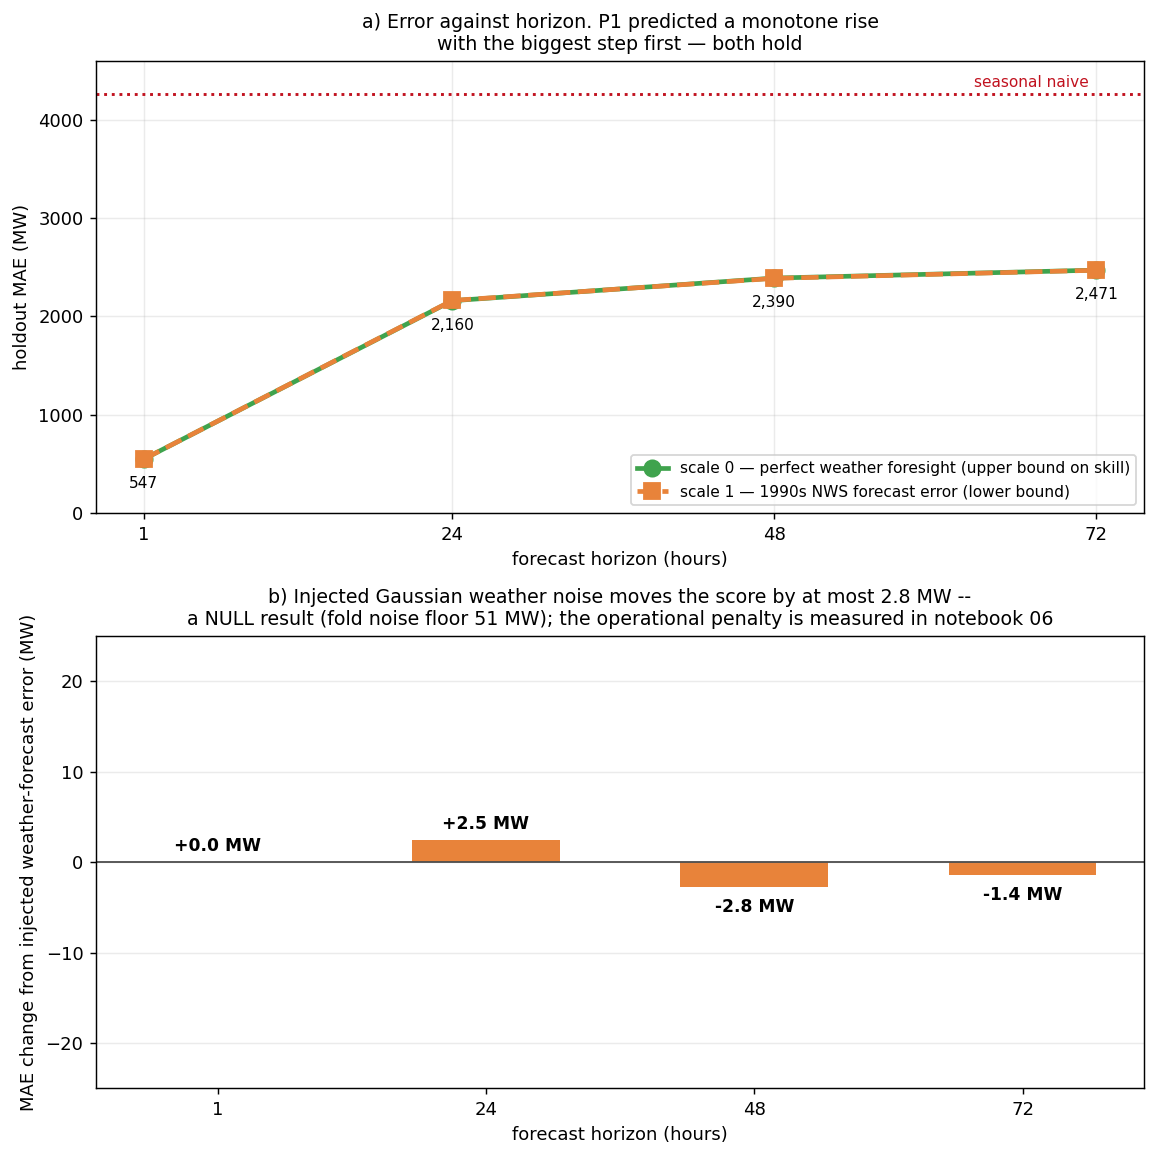


wrote holdout_predictions_by_horizon.parquet (189,196 rows)


In [10]:
# WHAT: score all four horizons on the same holdout, each at two weather-realism
#       settings — perfect foresight and the Brooks-curve degradation.
# WHY:  two separate honesty problems meet here.
#       (1) The horizon decides which lags EXIST. Lag 1 is the strongest predictor in
#           the panel (mean |PACF| 0.976) and is legal only at h=1, so error must rise
#           with h. Prediction P1 says so; this is where it is tested.
#       (2) Our weather columns are ERA5 REANALYSIS — a physics model run over history
#           with observations assimilated into it that did not exist at the forecast
#           origin. Feeding contemporaneous ERA5 to an h=72 model assumes a PERFECT
#           three-day weather forecast. Every weather contribution this project
#           reports is therefore an UPPER BOUND, and scale=1 is the lower one.
# NOTE: each horizon is scored with its own 4.6b champion -- lag set, model
#       hyperparameters and CV gap all follow the horizon (see CHANGED below). The
#       earlier version reused the h=24 winner everywhere and called the result
#       "mildly pessimistic"; 4.6b replaced that guess with a measurement.

# CHANGED 2026-08-23: each horizon is now scored with ITS OWN champion from 4.6b,
# not with the h=24 winner stretched across all four. The previous version said so
# and called the consequence "mildly pessimistic"; 4.6b measured it instead.
print(f"weather noise: scale 0 = perfect foresight (ERA5 as-is), "
      f"scale 1 = Brooks et al. 1994-95 NWS error")
print("each horizon uses its own tuned configuration (4.6b)\n")

# THE h=24 MODEL PARAMETERS, kept under their original name because sections 4.10,
# 4.11, 4.15 and 4.16 all use them and mean exactly this: the champion at the primary
# horizon. The 4.9 rewrite moved the source of truth from BEST_PARAMS to
# `champions[HORIZON]` and deleted this line with it, which left four later cells
# referencing a name nothing defined. Caught by a static pre-flight rather than by
# the run, which would have reached it after two and a half hours of compute.
model_params = {k.replace("model__", ""): v
                for k, v in champions[HORIZON]["params"].items()
                if k.startswith("model__")}
print(f"h={HORIZON} champion model hyperparameters, carried into 4.10-4.16: "
      f"{model_params}")

HOLD_PRED = {}          # horizon -> perfect-foresight holdout predictions, reused below
sweep = []
for h in cfg.HORIZONS:
    ch = champions[h]["params"]
    mp = {k.replace("model__", ""): v for k, v in ch.items() if k.startswith("model__")}
    lg = tuple(ch["lag__lags"])
    gp = cfg.cv_gap_for(h)
    for scale in (0.0, 1.0):
        t0 = time.time()
        pipe = P.make_supervised_pipeline(
            cfg.NUMERIC_FEATURES, lags=lg, weather_noise_scale=scale,
            k=ch["select__k"], roll_windows=tuple(ch["lag__roll_windows"]),
            model=HistGradientBoostingRegressor(random_state=cfg.SEED, **mp))
        pipe.fit(dev, y_dev)
        p = pipe.predict(hold)
        if scale == 0.0:
            HOLD_PRED[h] = p
        mae = float(mean_absolute_error(y_hold, p))
        sweep.append({"horizon": h, "noise_scale": scale, "holdout_mae": mae,
                      "lags": list(lg), "gap": gp, "seconds": round(time.time() - t0, 1)})
        print(f"   h={h:>2}  scale={scale:.0f}  holdout MAE {mae:9,.1f} MW   "
              f"lags={lg}  [{time.time()-t0:.0f}s]")

sw = pd.DataFrame(sweep)
piv = sw.pivot(index="horizon", columns="noise_scale", values="holdout_mae")
piv.columns = ["scale_0_perfect", "scale_1_degraded"]
piv["weather_penalty_mw"] = piv["scale_1_degraded"] - piv["scale_0_perfect"]
print("\nholdout MAE by horizon and weather realism:")
print(piv.round(1).to_string())

# --- Prediction P1, tested ---------------------------------------------------
p1_series = piv["scale_0_perfect"]
p1_monotone = bool(p1_series.is_monotonic_increasing)
steps = p1_series.diff().dropna()
p1_biggest_first = bool(steps.idxmax() == 24)
print(f"\nPREDICTION P1 — 'holdout MAE rises monotonically with the horizon, and the")
print(f"h=1 -> h=24 step is the largest single jump of the three'")
print(f"   monotone increasing: {p1_monotone}")
for hh, d in steps.items():
    prev = cfg.HORIZONS[list(cfg.HORIZONS).index(hh) - 1]
    print(f"      h={prev} -> h={hh}: {d:+8,.1f} MW" +
          ("   <- largest" if hh == steps.idxmax() else ""))
print(f"   largest jump is h=1 -> h=24: {p1_biggest_first}")
print(f"   VERDICT: P1 {'HOLDS' if (p1_monotone and p1_biggest_first) else 'FAILS'}")

fig, axes = plt.subplots(2, 1, figsize=(9.0, 9.0))
ax = axes[0]
ax.plot(piv.index, piv["scale_0_perfect"], "o-", lw=2.6, ms=9, color="#3fa34d",
        label="scale 0 — perfect weather foresight (upper bound on skill)")
ax.plot(piv.index, piv["scale_1_degraded"], "s--", lw=2.6, ms=9, color="#e8833a",
        label="scale 1 — 1990s NWS forecast error (lower bound)")
ax.fill_between(piv.index, piv["scale_0_perfect"], piv["scale_1_degraded"],
                color="#e8833a", alpha=0.15)
for h in piv.index:
    ax.annotate(f"{piv.loc[h,'scale_0_perfect']:,.0f}", (h, piv.loc[h, "scale_0_perfect"]),
                xytext=(0, -16), textcoords="offset points", ha="center", fontsize=8.5)
ax.axhline(b["naive168_mae"], color="#c1121f", ls=":", lw=1.6)
ax.annotate("seasonal naive", (72, b["naive168_mae"]), xytext=(-4, 4),
            textcoords="offset points", ha="right", fontsize=8.5, color="#c1121f")
ax.set_ylim(0, b["naive168_mae"] * 1.08)              # the h=1 label used to sit on the axis
ax.set_xticks(list(cfg.HORIZONS))
ax.set_xlabel("forecast horizon (hours)"); ax.set_ylabel("holdout MAE (MW)")
ax.set_title(f"a) Error against horizon. P1 predicted a monotone rise\n"
             f"with the biggest step first — {'both hold' if (p1_monotone and p1_biggest_first) else 'see the verdict'}",
             fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

ax = axes[1]
ax.bar([str(h) for h in piv.index], piv["weather_penalty_mw"], 0.55, color="#e8833a")
for i, h in enumerate(piv.index):
    _v = piv.loc[h, "weather_penalty_mw"]
    ax.annotate(f"{_v:+,.1f} MW", (i, _v), xytext=(0, 6 if _v >= 0 else -14),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")
ax.axhline(0, color="0.3", lw=1)
# A SYMMETRIC AXIS, SO A NULL LOOKS LIKE A NULL. Autoscaled to bars of -4 .. 0 MW the
# panel filled the frame with a 4 MW effect and its old title ("the gap is the size
# of the ERA5 advantage") read as though something had been measured. It had not.
_pen_lim = max(float(piv["weather_penalty_mw"].abs().max()) * 2.5, 25.0)
ax.set_ylim(-_pen_lim, _pen_lim)
ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("MAE change from injected weather-forecast error (MW)")
ax.set_title(f"b) Injected Gaussian weather noise moves the score by at most "
             f"{piv['weather_penalty_mw'].abs().max():,.1f} MW --\n"
             f"a NULL result (fold noise floor {fold_spread:,.0f} MW); the operational "
             f"penalty is measured in notebook 06", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_horizon_sweep.png", bbox_inches="tight")
plt.show()

# Persisted so notebook 06's operational-weather re-scoring and downstream dynamic
# reserve read the SAME per-horizon predictions this section reports, rather than
# refitting and quietly producing a second set of numbers.
_hp = pd.DataFrame({"timestamp": np.repeat(hold[TIME].to_numpy(), len(cfg.HORIZONS)),
                    "zone": np.repeat(hold[GROUP].to_numpy(), len(cfg.HORIZONS)),
                    "horizon": np.tile(list(cfg.HORIZONS), len(hold)),
                    "y_true": np.repeat(y_hold.to_numpy(), len(cfg.HORIZONS)),
                    "y_pred": np.column_stack([HOLD_PRED[h] for h in cfg.HORIZONS]).ravel()})
_hp.to_parquet(cfg.DATA_PROC / "holdout_predictions_by_horizon.parquet", index=False)
print(f"\nwrote holdout_predictions_by_horizon.parquet ({len(_hp):,} rows)")

R.save("nb04", {"horizon_sweep": {
    "rows": sweep,
    "by_horizon_scale0": {str(h): float(piv.loc[h, "scale_0_perfect"]) for h in piv.index},
    "by_horizon_scale1": {str(h): float(piv.loc[h, "scale_1_degraded"]) for h in piv.index},
    "weather_penalty_mw": {str(h): float(piv.loc[h, "weather_penalty_mw"]) for h in piv.index},
    "p1_monotone": p1_monotone, "p1_largest_step_is_first": p1_biggest_first,
    "p1_verdict": "holds" if (p1_monotone and p1_biggest_first) else "fails",
    "p1_steps_mw": {str(k): float(v) for k, v in steps.items()},
}});

**What this shows:** holdout MAE at each horizon, with reanalysis weather (scale 0) and with forecast-error noise (scale 1).

**What I see:** Scale 0: **547.1 · 2,159.6 · 2,389.7 · 2,470.8 MW** for h=1, 24, 48, 72. The steps are **+1,612.5**, **+230.1** and **+81.1**. Scale 1 changes these by **0.0, +2.5, −2.8 and −1.4 MW**.

**What it means:** **P1 holds**: error rises monotonically and the h=1→h=24 jump is by far the largest. Almost all the difficulty arrives in the first day; after that only diurnal and weekly structure remain, and extra distance costs little. The noise arm shows nothing, but unstructured Gaussian noise is the wrong error model, so this is not evidence that real forecast weather is free.

**What I do:** Quote scale 0 as an upper bound on skill. The cost of real forecast weather is measured in notebook 06, where the forecast as issued replaces the reanalysis.


### 4.9b — Skill per horizon against a horizon-matched benchmark

Each horizon's champion is compared with a `DF_composite_v2` rebuilt for that horizon: the renewables persistence lag follows the origin (48 hours back at h=48). The demand leg cannot follow, because EIA publishes only a day-ahead forecast. So at h=48 and h=72 the benchmark has better demand information than my model, and those skill scores are lower bounds. The comparison is fair only at h=24, which stays the headline.


--- champion per horizon, against a horizon-matched benchmark ---


,n,model_mae,composite_v2_mae,naive_mae,skill_vs_v2,skill_vs_naive,persistence_lag_h,fair
horizon,,,,,,,,
1,46123,546.0,2485.9,4259.8,0.7804,0.8718,24,False
24,46123,2139.7,2485.9,4259.8,0.1393,0.4977,24,True
48,46052,2370.8,2530.1,4257.1,0.0630,0.4431,48,False
72,46051,2457.7,2550.8,4262.3,0.0365,0.4234,72,False



G2' — skill over DF_composite_v2 at h=24: +13.9%  (MET, target > 0)
     for comparison, skill over v1 was +30.1% — the margin is smaller against the harder benchmark, which is what was predicted before it was measured.


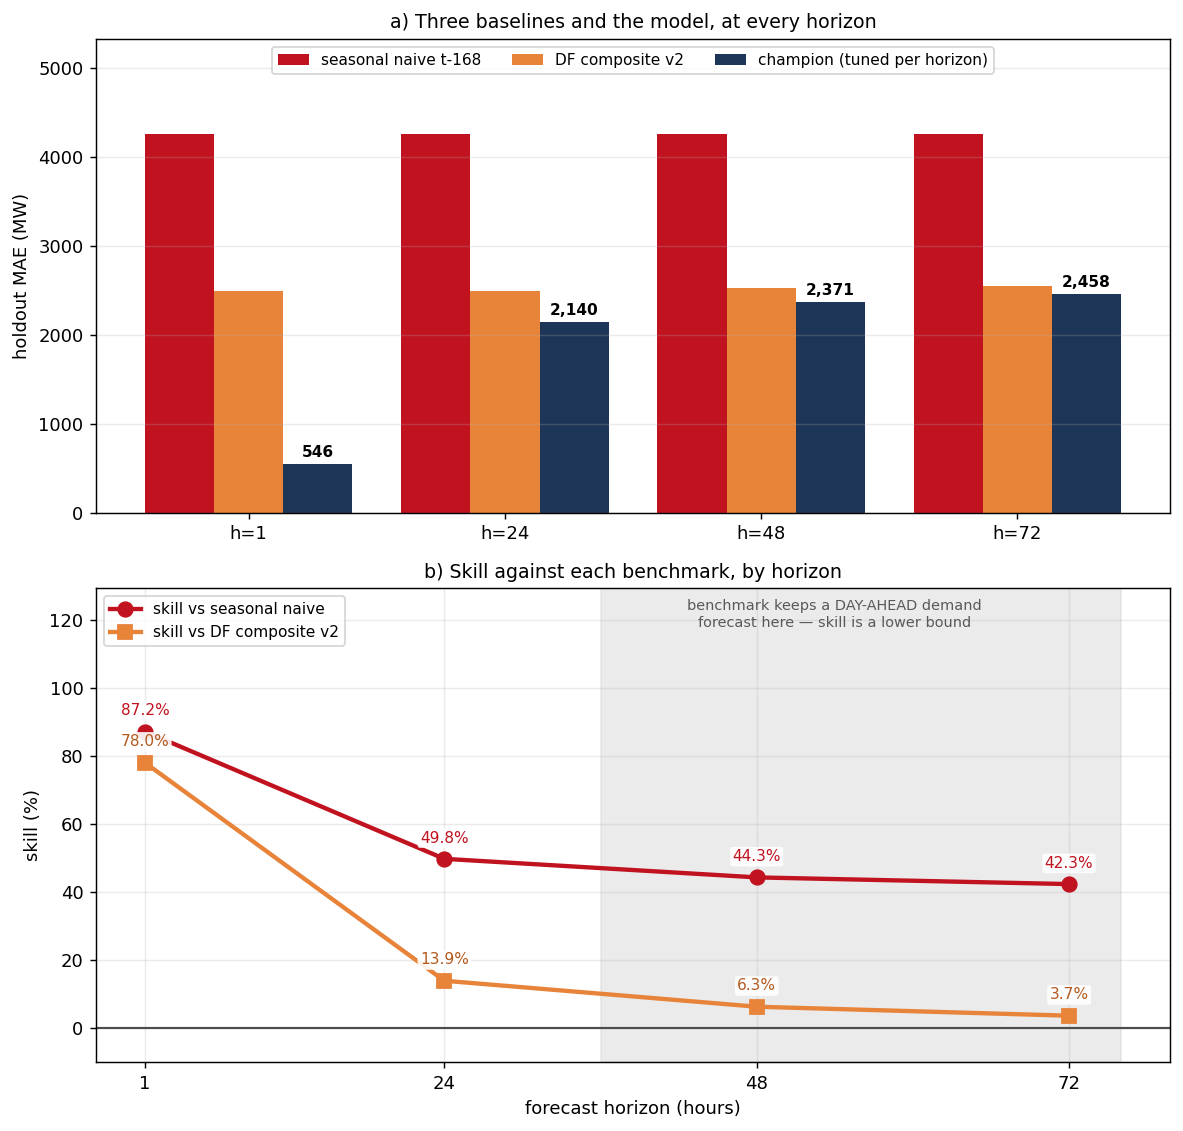

In [11]:
# WHAT: the per-horizon champion table, with skill against a horizon-matched
#       DF_composite_v2 and against seasonal naive.
# WHY:  the improvement programme's G6 asks for a four-row table, and a skill score
#       is only meaningful against a benchmark that faced the same information set.
# NOTE: the DEMAND leg cannot follow the horizon -- EIA publishes day-ahead only --
#       so at h=48 and h=72 the benchmark holds better demand information than the
#       model does. Those skill numbers are LOWER bounds and are labelled as such.

rows = []
for h in cfg.HORIZONS:
    # the renewables legs reach back a whole number of days >= h
    lag_h = int(np.ceil(h / 24) * 24)
    v2h = BL.composite_v2_selected(bl, coefs, chosen, lag_hours=lag_h)
    naive_h = BL.lag_by_time(bl, TARGET, 168)
    pred_h = pd.Series(HOLD_PRED[h], index=hold.index).reindex(bl.index)
    ok = (v2h["df_composite_v2"].notna() & naive_h.notna()
          & pred_h.notna() & bl[TARGET].notna())
    y = bl.loc[ok, TARGET]
    mae_model = float(mean_absolute_error(y, pred_h[ok]))
    mae_v2 = float(mean_absolute_error(y, v2h.loc[ok, "df_composite_v2"]))
    mae_nv = float(mean_absolute_error(y, naive_h[ok]))
    rows.append({
        "horizon": h, "n": int(ok.sum()),
        "model_mae": mae_model, "composite_v2_mae": mae_v2, "naive_mae": mae_nv,
        "skill_vs_v2": E.skill_score(mae_model, mae_v2),
        "skill_vs_naive": E.skill_score(mae_model, mae_nv),
        "persistence_lag_h": lag_h,
        "fair": h == HORIZON,
    })

ph = pd.DataFrame(rows).set_index("horizon")
print("--- champion per horizon, against a horizon-matched benchmark ---")
display(ph.round({"model_mae": 1, "composite_v2_mae": 1, "naive_mae": 1,
                  "skill_vs_v2": 4, "skill_vs_naive": 4}))

# G2' — the amended goal of 2026-08-23. Judged at h=24, the only horizon where
# the demand leg's information set matches ours.
g2p = float(ph.loc[HORIZON, "skill_vs_v2"])
v1_skill = R.get("nb04", "skill_vs_df_composite", default=None)
print(f"\nG2' — skill over DF_composite_v2 at h={HORIZON}: {g2p:+.1%}  "
      f"({'MET' if g2p > 0 else 'MISSED'}, target > 0)")
if v1_skill is not None:
    print(f"     for comparison, skill over v1 was {v1_skill:+.1%} — the margin is "
          f"{'smaller' if g2p < v1_skill else 'LARGER'} against the harder benchmark, "
          f"which is what was predicted before it was measured.")

fig, axes = plt.subplots(2, 1, figsize=(9.2, 8.8))
ax = axes[0]
w = 0.27
x = np.arange(len(ph))
ax.bar(x - w, ph["naive_mae"], w, label="seasonal naive t-168", color="#c1121f")
ax.bar(x, ph["composite_v2_mae"], w, label="DF composite v2", color="#e8833a")
ax.bar(x + w, ph["model_mae"], w, label="champion (tuned per horizon)", color="#1d3557")
for j, h in enumerate(ph.index):
    ax.annotate(f"{ph.loc[h,'model_mae']:,.0f}", (j + w, ph.loc[h, "model_mae"]),
                xytext=(0, 4), textcoords="offset points", ha="center",
                fontsize=8.5, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([f"h={h}" for h in ph.index])
ax.set_ylabel("holdout MAE (MW)")
ax.set_ylim(0, ph["naive_mae"].max() * 1.25)          # headroom: the legend used to cover the h=72 bar
ax.legend(fontsize=8.5, loc="upper center", ncol=3)
ax.set_title("a) Three baselines and the model, at every horizon", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1]
ax.plot(ph.index, 100 * ph["skill_vs_naive"], "o-", lw=2.4, ms=8, color="#c1121f",
        label="skill vs seasonal naive")
ax.plot(ph.index, 100 * ph["skill_vs_v2"], "s-", lw=2.4, ms=8, color="#e8833a",
        label="skill vs DF composite v2")
for h in ph.index:
    ax.annotate(f"{100*ph.loc[h,'skill_vs_v2']:.1f}%", (h, 100 * ph.loc[h, "skill_vs_v2"]),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5,
                color="#b35a1f", bbox=_WB)
    ax.annotate(f"{100*ph.loc[h,'skill_vs_naive']:.1f}%", (h, 100 * ph.loc[h, "skill_vs_naive"]),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5,
                color="#c1121f", bbox=_WB)
ax.axhline(0, color="0.3", lw=1.2)
ax.set_ylim(-10, 108)                                  # the labels used to print on the axis line
ax.axvspan(36, 76, color="0.85", alpha=0.5, zorder=0)
# Pinned to the TOP of the shaded span, not to a data value: at the bottom it was
# drawn straight through both skill curves and was unreadable in the report.
_lo, _hi = ax.get_ylim()
ax.set_ylim(_lo, _hi + 0.18 * (_hi - _lo))          # headroom for the caption
ax.annotate("benchmark keeps a DAY-AHEAD demand\nforecast here — skill is a lower bound",
            (54, ax.get_ylim()[1]), xytext=(0, -6), textcoords="offset points",
            ha="center", va="top", fontsize=8, color="0.35")
ax.set_xticks(list(cfg.HORIZONS)); ax.set_xlabel("forecast horizon (hours)")
ax.set_ylabel("skill (%)"); ax.legend(fontsize=8.5)
ax.set_title("b) Skill against each benchmark, by horizon", fontsize=10.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_skill_by_horizon.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"per_horizon_skill": {
    str(h): {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
             for k, v in ph.loc[h].items()} for h in ph.index},
    "g2_prime_skill_vs_composite_v2": g2p,
    "g2_prime_met": bool(g2p > 0),
    "g2_prime_horizon": HORIZON,
    "per_horizon_fairness_note": (
        "EIA publishes a day-ahead demand forecast only, so at h=48 and h=72 the "
        "benchmark holds better demand information than the model. Skill at those "
        "horizons is a lower bound; the comparison is fair only at h=24."),
});


**What this shows:** the champion's holdout MAE at each horizon beside `DF_composite_v2` (horizon-matched) and seasonal naive at t-168, on the same rows.

**What I see:** h=1: model **546.0 MW**, skill **78.0%** vs composite_v2 and **87.2%** vs naive. h=24: **2,139.7 MW** vs composite_v2 2,485.9 MW (**13.9%**) and naive 4,259.8 MW (**49.8%**). h=48: **2,370.8 MW** (**6.3%** and **44.3%**). h=72: **2,457.7 MW** (**3.7%** and **42.3%**). Skill against the composite falls much faster than skill against naive.

**What it means:** h=1 is close to persistence and is not a forecasting achievement. At h=48 and h=72 the benchmark's demand leg stays day-ahead, so it stops degrading while my model does; that, not model capacity, is why skill shrinks.

**What I do:** Judge G2-prime at h=24 only: **+13.9%** against `DF_composite_v2`, met. The other horizons are stored with `fair: false` and `persistence_lag_h` in `results.json`.


### 4.10 — Ablation by feature family

Remove one feature family at a time and re-score on the same folds. Families, not single features, because near-twins (such as `net_load_lag24` and `net_load_lag24_rel`) cover for each other. The selector is refitted inside each arm.

**How to read the output:** a positive bar means the family was earning its place; negative bars are reported, not rounded to zero.


full model CV MAE 2,107.3 MW   [368s for 6 arms]

   family    mae  delta_vs_full  pct_of_full  paired_sd  paired_p
  weather 2805.4          698.1         33.1      103.6       0.0
 calendar 2257.1          149.8          7.1       31.2       0.0
      lag 2173.4           66.0          3.1       49.6       0.0
     zone 2123.7           16.3          0.8       17.2       0.1
exogenous 2110.2            2.8          0.1       34.2       0.9
  rolling 2103.4           -4.0         -0.2        9.7       0.4

families worth more than the 51 MW fold-noise floor: weather, calendar, lag
families the model is BETTER without (reported, not rounded to zero):
   rolling       -4.0 MW


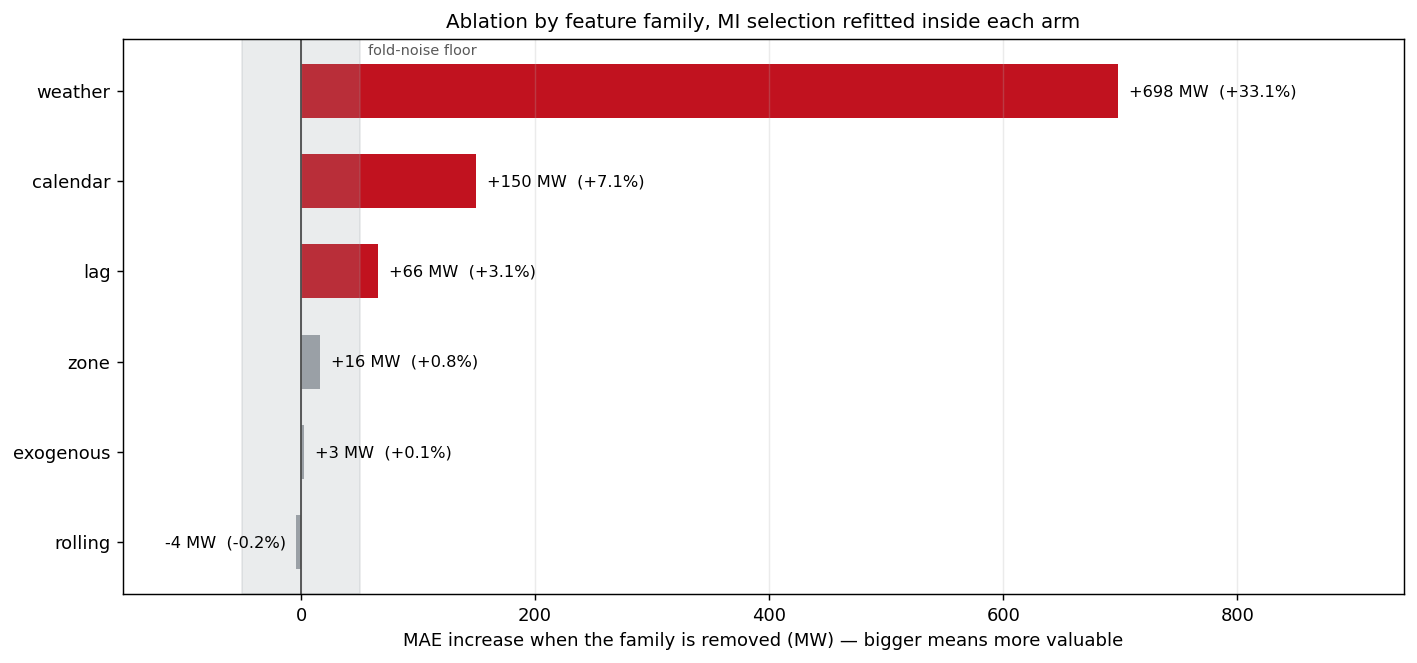

In [12]:
# WHAT: remove one feature FAMILY at a time and re-score under the same folds.
# WHY:  single-feature ablation is misleading on this feature set, and notebook 02 proved
#       it rather than assumed it: the 39 lowest-MI features are jointly worth
#       58.3 MW while each is individually near-zero, because correlated twins cover
#       for each other. Families are the fix.
# NOTE: the MI selector is REFITTED inside each ablated arm (the `ablate` step sits
#       before `select`), so each arm gets the best feature ranking available to it
#       rather than the full model's ranking with holes in it. Otherwise the ablation
#       would measure "the full model minus some columns", not "a model built without
#       this family".

# `exogenous` is generation by fuel, demand and renewable share -- HISTORY that
# until the family mapping was fixed was being counted inside "lag". The weather
# family now holds all fifteen weather variables and their lags, not `temp` alone.
#
# THE NAME IS `exogenous`, NOT `renewables`, and this list said the wrong one until
# 2026-08-24. pipeline.feature_family was renamed on 08-23 precisely because the set
# holds `demand` and `coal` and is not a renewables family -- and the rename never
# reached this cell. DropFeatureFamily raises rather than matching nothing, so it
# cost a 2h31m run at this cell instead of silently ablating a model against itself.
# That refusal is the only reason this was a crash and not a fabricated result.
FAMILIES = ["lag", "rolling", "calendar", "weather", "exogenous", "zone"]

_abl_folds = {}


def _score_without(fam):
    pipe = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=tuple(BEST_PARAMS["lag__lags"]),
        roll_windows=tuple(BEST_PARAMS["lag__roll_windows"]),
        k=BEST_PARAMS["select__k"], drop_family=fam,
        model=HistGradientBoostingRegressor(random_state=cfg.SEED, **model_params))
    s = -cross_val_score(pipe, dev, y_dev, cv=cv, n_jobs=cfg.N_JOBS, scoring="neg_mean_absolute_error")
    _abl_folds[fam] = s
    return float(s.mean())

t0 = time.time()
abl = E.ablation_by_family(_score_without, FAMILIES, baseline=CV_MAE)
abl["pct_of_full"] = abl["delta_vs_full"] / CV_MAE * 100
# A PAIRED TEST against the full model on the same five folds: the fold spread of one
# configuration (the noise floor below) is mostly how hard each fold is, which cancels
# when both arms are scored on the same folds.
from scipy import stats
_full_folds = -cross_val_score(BEST, dev, y_dev, cv=cv, n_jobs=cfg.N_JOBS, scoring="neg_mean_absolute_error")
abl["paired_sd"] = [float(np.std(_abl_folds[f] - _full_folds, ddof=1)) for f in abl["family"]]
abl["paired_p"] = [float(stats.ttest_rel(_abl_folds[f], _full_folds).pvalue) for f in abl["family"]]
print(f"full model CV MAE {CV_MAE:,.1f} MW   [{time.time()-t0:.0f}s for {len(FAMILIES)} arms]\n")
print(abl.round(1).to_string(index=False))

noise = R.get("nb04", "hyperparam_sensitivity")["fold_noise_floor_mw"]
_real = abl[abl["delta_vs_full"] > noise]["family"].tolist()
print(f"\nfamilies worth more than the {noise:,.0f} MW fold-noise floor: "
      f"{', '.join(_real) if _real else 'none'}")
_neg = abl[abl["delta_vs_full"] < 0]
if len(_neg):
    print("families the model is BETTER without (reported, not rounded to zero):")
    for r in _neg.itertuples():
        print(f"   {r.family:10s} {r.delta_vs_full:+7,.1f} MW")

fig, ax = plt.subplots(figsize=(11, 5.2))
ys = np.arange(len(abl))[::-1]
cols = ["#c1121f" if d > noise else "#9aa0a6" for d in abl["delta_vs_full"]]
ax.barh(ys, abl["delta_vs_full"], color=cols, height=0.6)
for y, r in zip(ys, abl.itertuples()):
    off = 6 if r.delta_vs_full >= 0 else -6
    ha = "left" if r.delta_vs_full >= 0 else "right"
    ax.annotate(f"{r.delta_vs_full:+,.0f} MW  ({r.pct_of_full:+.1f}%)",
                (r.delta_vs_full, y), xytext=(off, -3), textcoords="offset points",
                ha=ha, fontsize=9)
ax.axvline(0, color="0.3", lw=1)
ax.axvspan(-noise, noise, color="#9aa0a6", alpha=0.2)
ax.annotate("fold-noise floor", (noise, len(abl) - 0.6), xytext=(4, 0),
            textcoords="offset points", fontsize=8, color="0.35")
ax.set_yticks(ys); ax.set_yticklabels(abl["family"], fontsize=10)
ax.set_xlabel("MAE increase when the family is removed (MW) — bigger means more valuable")
ax.set_xlim(min(abl["delta_vs_full"].min() * 1.5, -noise * 3),
            abl["delta_vs_full"].max() * 1.35)
ax.set_title("Ablation by feature family, MI selection refitted inside each arm",
             fontsize=11)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_ablation.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"ablation": {
    "baseline_cv_mae": CV_MAE,
    "families": {r["family"]: {"mae": r["mae"], "delta_mw": r["delta_vs_full"],
                               "pct_of_full": r["pct_of_full"],
                               "paired_sd_mw": r["paired_sd"], "paired_p": r["paired_p"]}
                 for _, r in abl.iterrows()},
    "families_above_noise_floor": _real,
}});

**What this shows:** CV MAE with each feature family removed, against the full model, with the noise floor marked.

**What I see:** Full model **2,107.3 MW**. Removing weather costs **+698.1 MW (33.1%)**, calendar **+149.8 (7.1%)**, target lags **+66.0 (3.1%)**, zone **+16.3**, exogenous fuel history **+2.8**, and rolling statistics **−4.0 MW** (slightly better without). Weather, calendar and lag clear the 51 MW noise floor, and the paired tests agree (p 0.0001, 0.0004, 0.04); zone, exogenous and rolling do not.

**What it means:** Weather is the one family nothing else in the matrix can reconstruct. The lag family looks small here because substitutes such as `demand_lag24` and the rolling means remain when it is removed; notebook 07's permutation importance ranks lags first because it breaks a feature without refitting. Ablation prices a family's irreplaceable content, permutation measures what the fitted model leans on. The 698 MW is measured with ERA5 reanalysis, so it is an upper bound.

**What I do:** Keep the rolling family (its effect is within noise). Quote this ranking next to notebook 07's, with the difference explained.


### 4.11 — Learning curves, built by hand

Validation error against training-set size, using the most recent slice at each size. `sklearn`'s `learning_curve` is not used because by default it takes the oldest rows first (or a random subset when shuffled), which does not answer "how far back is it worth keeping data?".

**How to read the output:** still falling at the right means more history helps; flat means the limit is the features.


[87s]
 fraction  n_rows  years         train_start  train_mae  valid_mae    gap
     0.10   22800   0.43 2022-11-26 03:00:00      709.5     3856.9 3147.4
     0.20   45594   0.87 2022-06-20 20:00:00      956.9     2328.2 1371.3
     0.35   79788   1.52 2021-10-26 07:00:00     1142.8     2219.8 1077.0
     0.50  113982   2.17 2021-03-02 16:00:00     1258.5     2181.9  923.4
     0.75  170971   3.25 2020-01-31 21:00:00     1356.3     2106.1  749.8
     1.00  227962   4.33 2019-01-01 00:00:00     1414.1     2102.4  688.3

validation MAE falls 1,754 MW from the smallest slice to the full one
the last step (75% -> 100%) is worth +4 MW
VERDICT: the curve is FLAT at the right-hand end — the ceiling is the FEATURES, not the data


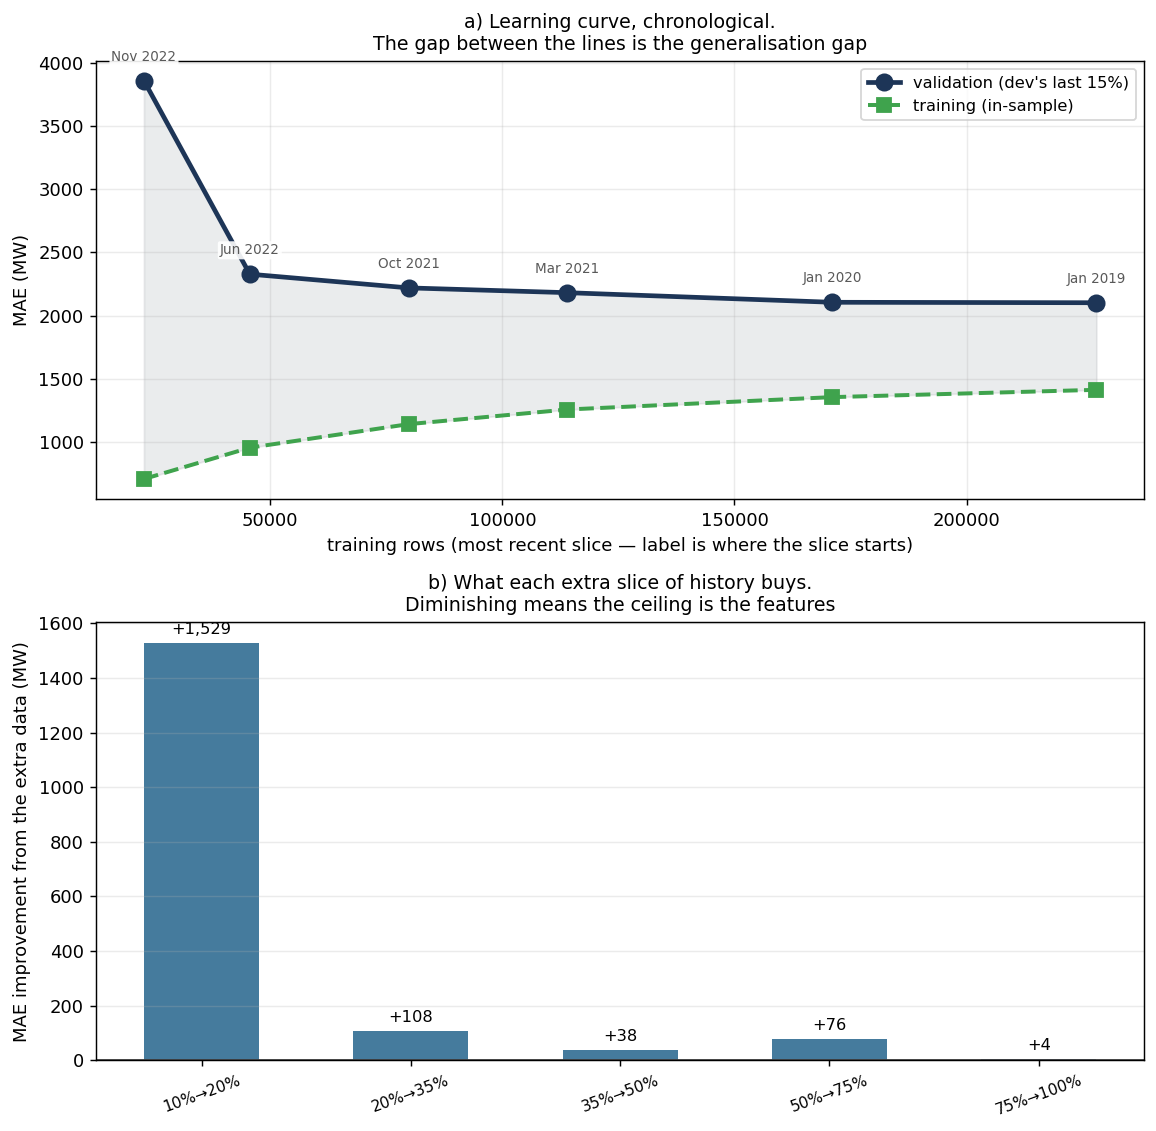

In [13]:
# WHAT: validation error against training-set size, taking the MOST RECENT slice at
#       each size.
# WHY:  `sklearn.model_selection.learning_curve` is NOT used, and the reason is
#       specific, not stylistic: by default it trains on the FIRST n rows of each
#       fold (oldest-first), and with shuffle=True on a random subset scattered across
#       the timeline. Neither answers the real question, "how far back does it pay
#       to keep data?".
# NOTE: the curve confounds SIZE with RECENCY, deliberately. The 20% point is both
#       small and recent. The alternative (oldest-first) confounds size with
#       staleness, which is worse, because nobody chooses whether to keep their
#       OLDEST data -- they choose how far back to go from today. Reading the curve as
#       pure sample-size effect would be wrong and the interpretation says so.

def _fit_predict(train_frame, valid_frame):
    pipe = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=tuple(BEST_PARAMS["lag__lags"]),
        roll_windows=tuple(BEST_PARAMS["lag__roll_windows"]),
        k=BEST_PARAMS["select__k"],
        model=HistGradientBoostingRegressor(random_state=cfg.SEED, **model_params))
    pipe.fit(train_frame, train_frame[TARGET])
    tr = mean_absolute_error(train_frame[TARGET], pipe.predict(train_frame))
    va = mean_absolute_error(valid_frame[TARGET], pipe.predict(valid_frame))
    return float(tr), float(va)

# Run on `dev` only, with dev's own last 15% as the validation slice. The notebook 04
# holdout is not touched here -- a learning curve is a tuning-time diagnostic, and
# spending the holdout on it would spend it five times over.
t0 = time.time()
lc = E.chronological_learning_curve(_fit_predict, dev,
                                    sizes=(0.1, 0.2, 0.35, 0.5, 0.75, 1.0),
                                    val_fraction=0.15)
lc["years"] = lc["n_rows"] / (len(dev) / ((dev[TIME].max() - dev[TIME].min()).days / 365.25))
print(f"[{time.time()-t0:.0f}s]")
print(lc[["fraction", "n_rows", "years", "train_start", "train_mae", "valid_mae"]]
      .assign(gap=lc["valid_mae"] - lc["train_mae"])
      .round({"fraction": 2, "years": 2, "train_mae": 1, "valid_mae": 1, "gap": 1})
      .to_string(index=False))

_last_step = float(lc["valid_mae"].iloc[-2] - lc["valid_mae"].iloc[-1])
_total_drop = float(lc["valid_mae"].iloc[0] - lc["valid_mae"].iloc[-1])
_still_falling = _last_step > 0.02 * lc["valid_mae"].iloc[-1]
print(f"\nvalidation MAE falls {_total_drop:,.0f} MW from the smallest slice to the full one")
print(f"the last step (75% -> 100%) is worth {_last_step:+,.0f} MW")
print(f"VERDICT: the curve is {'STILL FALLING — more history would help' if _still_falling else 'FLAT at the right-hand end — the ceiling is the FEATURES, not the data'}")

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.8))
ax = axes[0]
ax.plot(lc["n_rows"], lc["valid_mae"], "o-", lw=2.6, ms=9, color="#1d3557",
        label="validation (dev's last 15%)")
ax.plot(lc["n_rows"], lc["train_mae"], "s--", lw=2.2, ms=8, color="#3fa34d",
        label="training (in-sample)")
ax.fill_between(lc["n_rows"], lc["train_mae"], lc["valid_mae"], color="#9aa0a6", alpha=0.2)
for _, r in lc.iterrows():
    ax.annotate(f"{r['train_start']:%b %Y}", (r["n_rows"], r["valid_mae"]),
                xytext=(0, 11), textcoords="offset points", ha="center", fontsize=7.5,
                color="0.35", bbox=_WB)
ax.set_xlabel("training rows (most recent slice — label is where the slice starts)")
ax.set_ylabel("MAE (MW)")
ax.set_title("a) Learning curve, chronological.\n"
             "The gap between the lines is the generalisation gap", fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
step = lc["valid_mae"].diff(-1).iloc[:-1]          # MAE(fraction) - MAE(next fraction): the improvement
ax.bar(range(len(step)), step.values, 0.55, color="#457b9d")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(range(len(step)))
ax.set_xticklabels([f"{lc['fraction'].iloc[i]:.0%}→{lc['fraction'].iloc[i+1]:.0%}"
                    for i in range(len(step))], fontsize=8.5, rotation=20)
for i, v in enumerate(step.values):
    ax.annotate(f"{v:+,.0f}", (i, v), xytext=(0, 5 if v >= 0 else -12),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_ylabel("MAE improvement from the extra data (MW)")
ax.set_title("b) What each extra slice of history buys.\n"
             "Diminishing means the ceiling is the features", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_learning_curve.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"learning_curve": {
    "rows": [{k: (str(v) if k == "train_start" else float(v)) for k, v in r.items()
              if k != "years"} for _, r in lc.iterrows()],
    "total_drop_mw": _total_drop, "last_step_mw": _last_step,
    "still_falling": bool(_still_falling),
}});

**What this shows:** training and validation MAE against training-set size, each size taking the most recent slice.

**What I see:** Validation error falls **3,856.9 → 2,328.2 → 2,219.8 → 2,181.9 → 2,106.1 → 2,102.4 MW** from 10% to 100% of the data (22,800 to 227,962 rows). The last step is worth **4 MW**. Training error rises from **709.5 to 1,414.1 MW**.

**What it means:** The curve is flat at the right: the last 57,000 rows buy 4 MW, well inside the 51 MW noise floor. The train–validation gap is the model failing to fit the remaining structure, not variance that more rows would close.

**What I do:** Stop treating sample size as a lever; the next gain has to come from better features.


### 4.12 — Failure analysis

Where the worst errors live: the worst decile by local hour, month, zone and temperature, plus the single worst day. Hours are local because the evening ramp follows the sun; UTC hours would smear it. Error by cluster needs notebook 05's labels and is not computed here. This tests predictions **P3** and **P4**.

**How to read the output:** panel (b) shows over-representation in the worst decile, not average error.


worst-decile threshold: |error| >= 5,441 MW  (4,730 of 47,299 rows)

most over-represented LOCAL hours: 16:00 (1.24x), 15:00 (1.23x), 14:00 (1.22x), 17:00 (1.21x)
most over-represented zones:       ERCO (2.53x), MISO (1.96x), SWPP (1.36x)
most over-represented months:      11 (1.28x), 2 (1.25x), 12 (1.23x)

same decile cut on error SCALED by each zone's mean load (removes the size confound):
   SWPP (2.89x), ERCO (1.48x), BPAT (0.80x)
   absolute-cut ranking was ['ERCO', 'MISO', 'SWPP']; scaled-cut ranking is ['SWPP', 'ERCO', 'BPAT']

MAE by temperature quintile:
            mean  size
temp_bin              
coldest   2044.9  9523
cold      1786.8  9504
mild      2050.1  9497
warm      2307.3  9414
hottest   2617.4  9361

worst UTC date (all six regions): 2024-07-02 — mean |error| 6,433 MW (3.0x the holdout average)
   worst zone that day: MISO


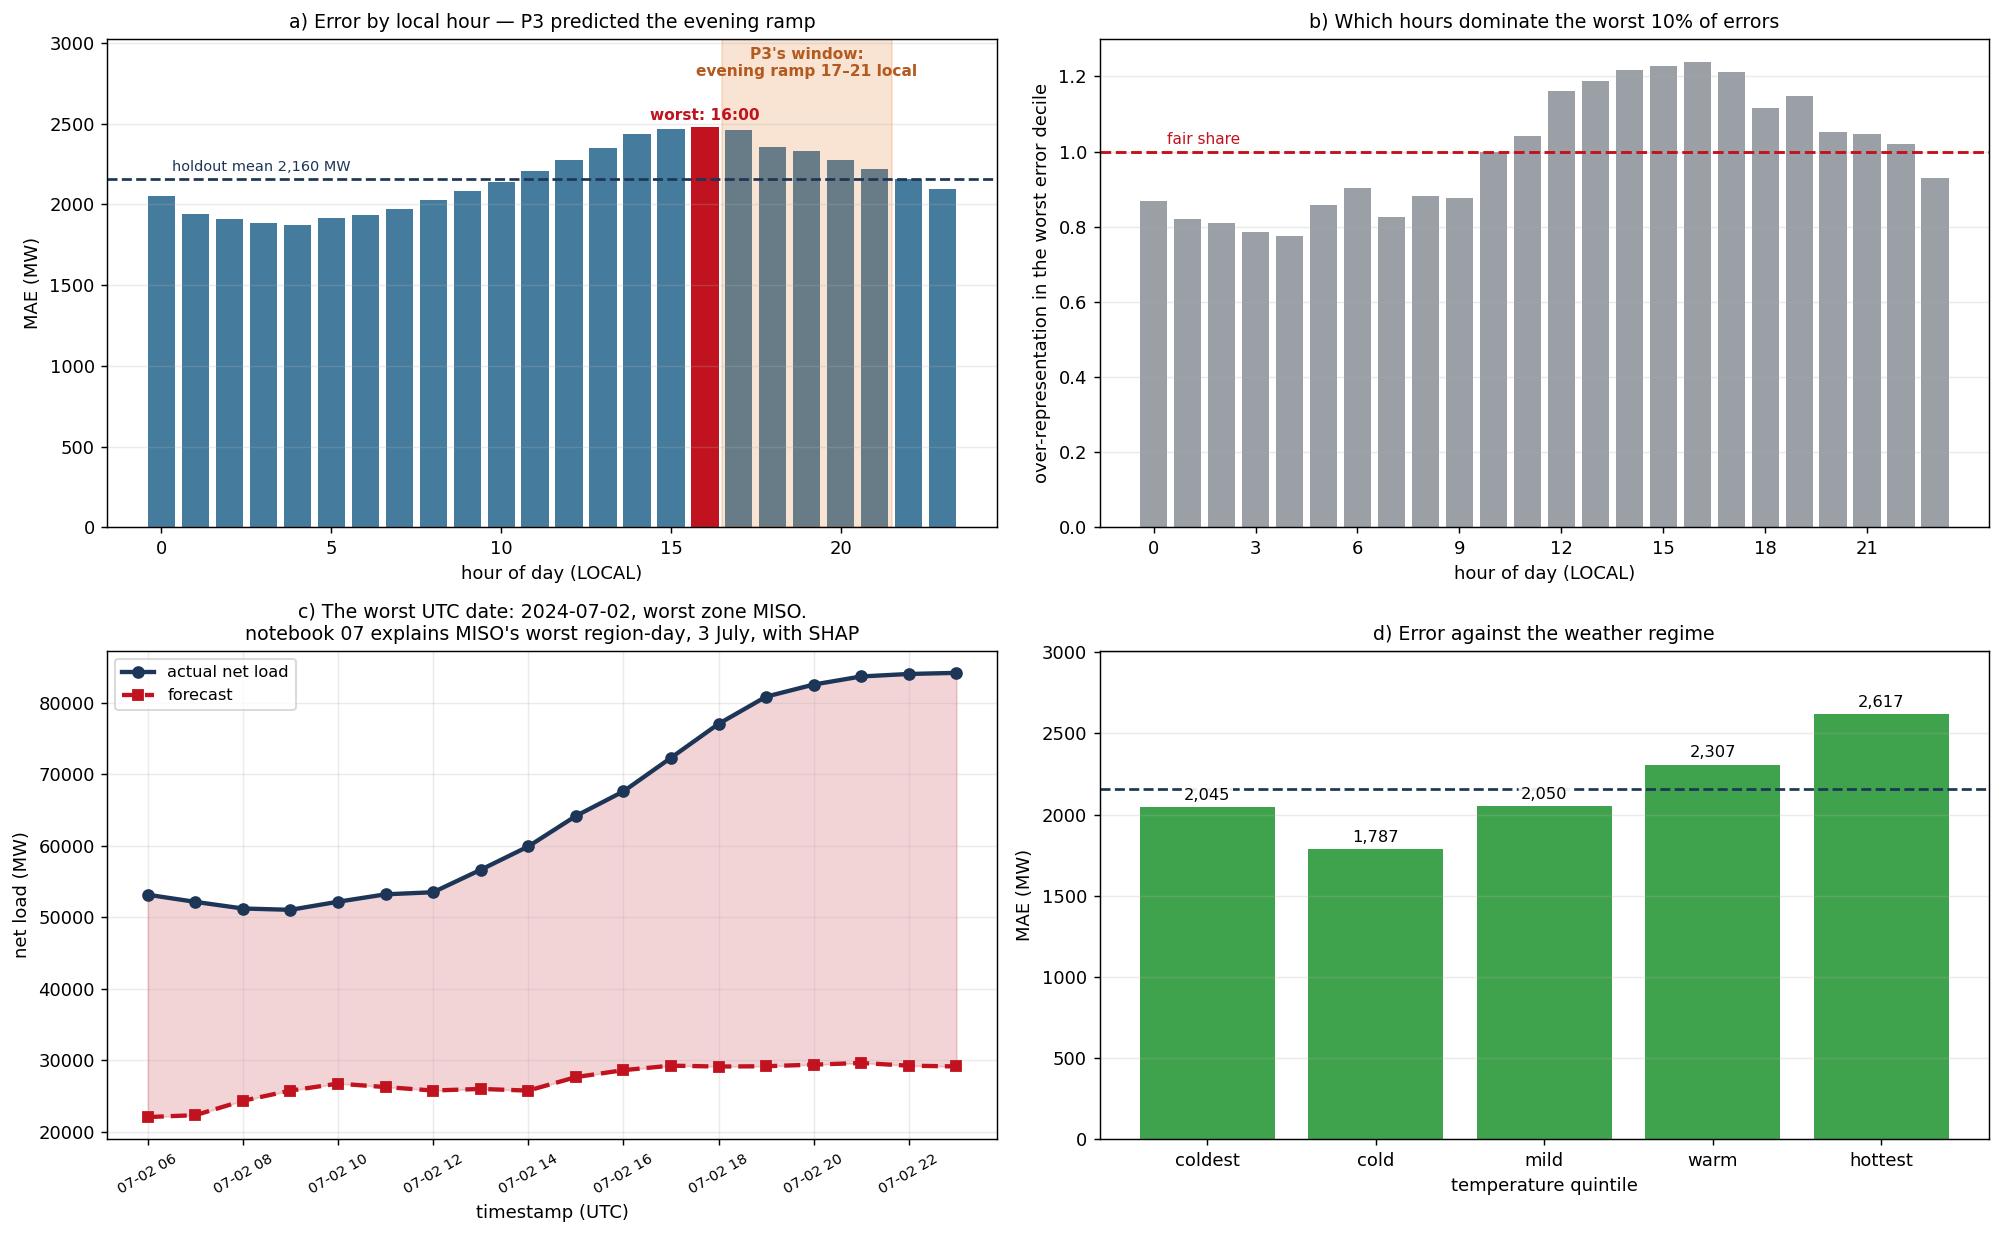


PREDICTION P3 — 'MAE is worst in the evening ramp hours (17-21 local)'
   evening 17-21 local: 2,327 MW | all other hours: 2,115 MW
   single worst hour is 16:00 local
   VERDICT: P3 FAILS
   HOW it fails matters more than that it fails. The DIRECTION is right —
   the evening window is worse than the rest of the day by 212 MW — but the
   peak sits at 16:00, and the four hours most over-represented in the
   worst decile are [14, 15, 16, 17]. The error peaks 1 hour(s) BEFORE
   the predicted 17-21 window, when solar output is falling in the solar regions
   and afternoon heat is near its peak; this notebook does not separate the two.
   ALSO PARTIAL: P3 says 'at every horizon' and this tests h=24 only.

PREDICTION P4 — 'scaled error is highest for SWPP and lowest for NYIS'
   highest: SWPP (14.6%) | lowest: NYIS (4.3%)
   VERDICT: P4 HOLDS

>>> The model fails when the hottest hours arrive in the afternoon turn-down
>>> around 16:00 local, worst in SWPP relative to its own load,
>>> 

In [14]:
# WHAT: where the model fails — the worst error decile by hour, month, zone and
#       weather regime, and the single worst day plotted hour by hour.
# WHY:  a mean MAE tells an operator nothing about when to distrust the forecast. The
#       deliverable is a sentence of the form "the model fails when ___, because ___",
#       and it has to be earned from the breakdown rather than guessed.
# NOTE: hours are LOCAL here. The evening ramp is a fact about the sun, and UTC 17-21
#       is 09:00-14:00 local in CISO — notebook 03 already made this mistake once and
#       the correction changed its numbers materially.

res_local = res.copy()
_loc = pd.Series(pd.NaT, index=res_local.index, dtype="datetime64[ns]")
for z, tz in cfg.ZONE_TZ.items():
    m = res_local["zone"] == z
    _loc[m] = (res_local.loc[m, "ts"].dt.tz_localize("UTC").dt.tz_convert(tz)
               .dt.tz_localize(None))
res_local["local_hour"] = _loc.dt.hour

# The worst decile: which hours, months and zones are over-represented in it?
thr = res_local["abs_err"].quantile(0.9)
worst = res_local[res_local["abs_err"] >= thr]
print(f"worst-decile threshold: |error| >= {thr:,.0f} MW  ({len(worst):,} of {len(res_local):,} rows)")

def _lift(col):
    """How over-represented is each level in the worst decile? 1.0 = its fair share."""
    share_all = res_local[col].value_counts(normalize=True)
    share_bad = worst[col].value_counts(normalize=True)
    return (share_bad / share_all).sort_values(ascending=False)

lift_hour, lift_zone, lift_month = _lift("local_hour"), _lift("zone"), _lift("month")
print(f"\nmost over-represented LOCAL hours: "
      f"{', '.join(f'{h:02d}:00 ({v:.2f}x)' for h, v in lift_hour.head(4).items())}")
print(f"most over-represented zones:       "
      f"{', '.join(f'{z} ({v:.2f}x)' for z, v in lift_zone.head(3).items())}")
print(f"most over-represented months:      "
      f"{', '.join(f'{m} ({v:.2f}x)' for m, v in lift_month.head(3).items())}")

# THE ZONE RANKING ABOVE IS CONFOUNDED BY ZONE SIZE, and quoting it without saying so
# would be reporting an artefact. The worst decile is cut at an ABSOLUTE MW threshold,
# so the two largest zones land in it simply for being large — ERCO's mean net load is
# several times NYIS's, and so is its error, without either model being worse. The
# scaled cut asks the question actually intended: relative to its own load, where does
# the model do badly?
res_local["scaled_err"] = res_local["abs_err"] / res_local.groupby("zone")["y"].transform("mean")
thr_s = res_local["scaled_err"].quantile(0.9)
worst_s = res_local[res_local["scaled_err"] >= thr_s]
lift_zone_scaled = ((worst_s["zone"].value_counts(normalize=True)
                     / res_local["zone"].value_counts(normalize=True))
                    .sort_values(ascending=False))
print(f"\nsame decile cut on error SCALED by each zone's mean load (removes the size "
      f"confound):\n   "
      + ", ".join(f"{z} ({v:.2f}x)" for z, v in lift_zone_scaled.head(3).items()))
print(f"   absolute-cut ranking was {list(lift_zone.head(3).index)}; "
      f"scaled-cut ranking is {list(lift_zone_scaled.head(3).index)}")

# Weather regime: is the error worse at temperature extremes?
res_local["temp"] = hold["temp"].values
res_local["temp_bin"] = pd.qcut(res_local["temp"], 5,
                                labels=["coldest", "cold", "mild", "warm", "hottest"])
by_temp = res_local.groupby("temp_bin", observed=True)["abs_err"].agg(["mean", "size"])
print(f"\nMAE by temperature quintile:")
print(by_temp.round(1).to_string())

# The worst UTC date, averaged over all six regions. Notebook 07 ranks region-days
# instead and explains its worst one (MISO, 2024-07-03) with SHAP.
day_err = res_local.groupby("date")["abs_err"].mean()
worst_day = day_err.idxmax()
wd = res_local[res_local["date"] == worst_day].sort_values("ts")
wd_zone = wd.groupby("zone")["abs_err"].mean().idxmax()
print(f"\nworst UTC date (all six regions): {worst_day} — mean |error| {day_err.max():,.0f} MW "
      f"({day_err.max()/res_local['abs_err'].mean():.1f}x the holdout average)")
print(f"   worst zone that day: {wd_zone}")

fig, axes = plt.subplots(2, 2, figsize=(15.5, 9.6))
ax = axes[0, 0]
hourly = res_local.groupby("local_hour")["abs_err"].mean()
ax.bar(hourly.index, hourly.values, color="#457b9d")
ax.axvspan(16.5, 21.5, color="#e8833a", alpha=0.22)
ax.set_ylim(0, hourly.max() * 1.22)          # headroom, so the labels sit above the bars
ax.annotate("P3's window:\nevening ramp 17–21 local", (19, hourly.max() * 1.2), ha="center",
            va="top", fontsize=8.5, color="#b35a1f", fontweight="bold")
ax.bar([int(hourly.idxmax())], [hourly.max()], color="#c1121f")     # the single worst hour, in red
ax.annotate(f"worst: {int(hourly.idxmax()):02d}:00", (int(hourly.idxmax()), hourly.max()), xytext=(0, 4),
            textcoords="offset points", ha="center", fontsize=8.5, color="#c1121f", fontweight="bold")
ax.axhline(res_local["abs_err"].mean(), color="#1d3557", ls="--", lw=1.5)
ax.annotate(f"holdout mean {res_local['abs_err'].mean():,.0f} MW", (0.3, res_local["abs_err"].mean()),
            xytext=(0, 4), textcoords="offset points", fontsize=8, color="#1d3557", bbox=_WB)
ax.set_xlabel("hour of day (LOCAL)"); ax.set_ylabel("MAE (MW)")
ax.set_title("a) Error by local hour — P3 predicted the evening ramp", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[0, 1]
ax.bar(range(len(lift_hour)), lift_hour.sort_index().values, color="#9aa0a6")
ax.axhline(1.0, color="#c1121f", ls="--", lw=1.6)
ax.annotate("fair share", (0.4, 1.02), fontsize=8.5, color="#c1121f")
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(range(0, 24, 3))
ax.set_xlabel("hour of day (LOCAL)")
ax.set_ylabel("over-representation in the worst error decile")
ax.set_title("b) Which hours dominate the worst 10% of errors", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1, 0]
sub = wd[wd["zone"] == wd_zone].sort_values("ts")
ax.plot(sub["ts"], sub["y"], "o-", lw=2.4, ms=6, color="#1d3557", label="actual net load")
ax.plot(sub["ts"], sub["pred"], "s--", lw=2.4, ms=6, color="#c1121f", label="forecast")
ax.fill_between(sub["ts"], sub["y"], sub["pred"], color="#c1121f", alpha=0.18)
ax.set_ylabel("net load (MW)")
ax.set_title(f"c) The worst UTC date: {worst_day}, worst zone {wd_zone}.\n"
             f"notebook 07 explains MISO's worst region-day, 3 July, with SHAP", fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_xlabel("timestamp (UTC)")               # this panel is on the panel's clock, not local
ax.tick_params(axis="x", rotation=30, labelsize=8)

ax = axes[1, 1]
ax.bar(by_temp.index.astype(str), by_temp["mean"], color="#3fa34d")
ax.axhline(res_local["abs_err"].mean(), color="#1d3557", ls="--", lw=1.5)
for i, v in enumerate(by_temp["mean"]):
    ax.annotate(f"{v:,.0f}", (i, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=9, bbox=_WB)
ax.set_ylim(0, by_temp["mean"].max() * 1.15)
ax.set_xlabel("temperature quintile"); ax.set_ylabel("MAE (MW)")
ax.set_title("d) Error against the weather regime", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_failure_analysis.png", bbox_inches="tight")
plt.show()

# --- Prediction P3, tested ---------------------------------------------------
evening = res_local[res_local["local_hour"].between(17, 21)]["abs_err"].mean()
other = res_local[~res_local["local_hour"].between(17, 21)]["abs_err"].mean()
peak_hour = int(hourly.idxmax())
p3 = bool(17 <= peak_hour <= 21)
print(f"\nPREDICTION P3 — 'MAE is worst in the evening ramp hours (17-21 local)'")
print(f"   evening 17-21 local: {evening:,.0f} MW | all other hours: {other:,.0f} MW")
print(f"   single worst hour is {peak_hour:02d}:00 local")
print(f"   VERDICT: P3 {'HOLDS' if p3 else 'FAILS'}")
if not p3:
    top4 = list(lift_hour.head(4).index)
    print(f"   HOW it fails matters more than that it fails. The DIRECTION is right —")
    print(f"   the evening window is worse than the rest of the day by "
          f"{evening-other:,.0f} MW — but the")
    print(f"   peak sits at {peak_hour:02d}:00, and the four hours most over-represented in the")
    print(f"   worst decile are {sorted(top4)}. The error peaks {17 - peak_hour} hour(s) BEFORE")
    print(f"   the predicted 17-21 window, when solar output is falling in the solar regions")
    print(f"   and afternoon heat is near its peak; this notebook does not separate the two.")
    print(f"   ALSO PARTIAL: P3 says 'at every horizon' and this tests h={HORIZON} only.")

# --- Prediction P4, tested ---------------------------------------------------
bz = R.get("nb04", "holdout_by_zone")
scaled = {z: v["scaled"] for z, v in bz.items()}
hi, lo = max(scaled, key=scaled.get), min(scaled, key=scaled.get)
p4 = bool(hi == "SWPP" and lo == "NYIS")
print(f"\nPREDICTION P4 — 'scaled error is highest for SWPP and lowest for NYIS'")
print(f"   highest: {hi} ({scaled[hi]:.1f}%) | lowest: {lo} ({scaled[lo]:.1f}%)")
print(f"   VERDICT: P4 {'HOLDS' if p4 else 'FAILS'}")

# THE REQUIRED SENTENCE, built from the numbers just computed rather than asserted in
# advance. The first draft of this cell had it pre-written — "fails when the evening
# ramp is steep in a high-renewable zone" — and the output does not support that: the
# peak is mid-afternoon, not evening, and only the zone half survives: the two worst scaled
# zones, SWPP and ERCO, do have the highest wind-and-solar shares over the last year
# (notebook 01). Assembling it from the variables is the only way it stays true when
# the numbers move.
_worst_hour = int(hourly.idxmax())
_worst_zone_scaled = str(lift_zone_scaled.index[0])
_worst_temp = str(by_temp["mean"].idxmax())
_hot_vs_mild = float(by_temp["mean"].max() - by_temp["mean"].min())
print(f"\n>>> The model fails when the {_worst_temp} hours arrive in the afternoon "
      f"turn-down\n>>> around {_worst_hour:02d}:00 local, worst in {_worst_zone_scaled} "
      f"relative to its own load,\n>>> because that is where net load reverses direction "
      f"while demand is still flat --\n>>> the target-history lags "
      f"(worth {R.get('nb04','ablation')['families']['lag']['delta_mw']:+,.0f} MW in the ablation, third behind weather and calendar)\n"
      f">>> describe a trajectory that has not yet turned at the forecast origin. The "
      f"spread\n>>> from the lowest-error temperature quintile to the {_worst_temp} one is "
      f"{_hot_vs_mild:,.0f} MW.")

R.save("nb04", {"failure_analysis": {
    "worst_decile_threshold_mw": float(thr),
    "lift_by_local_hour": {int(k): float(v) for k, v in lift_hour.items()},
    "lift_by_zone_absolute_cut": {k: float(v) for k, v in lift_zone.items()},
    "lift_by_zone_scaled_cut": {k: float(v) for k, v in lift_zone_scaled.items()},
    "mae_by_local_hour": {int(k): float(v) for k, v in hourly.items()},
    "mae_by_temp_quintile": {str(k): float(v) for k, v in by_temp["mean"].items()},
    "worst_day": str(worst_day), "worst_day_mae": float(day_err.max()),
    "worst_day_zone": wd_zone,
    "evening_mae": float(evening), "other_hours_mae": float(other),
    "peak_error_local_hour": peak_hour,
    "p3_verdict": "holds" if p3 else "fails",
    "p4_verdict": "holds" if p4 else "fails",
    "p4_highest_zone": hi, "p4_lowest_zone": lo,
}});

**What this shows:** where holdout error concentrates: lift by local hour, and by zone under an absolute and a scaled cut.

**What I see:** Evening (17–21 local) MAE is **2,327 MW** against **2,115** for other hours. The worst decile (|error| ≥ 5,441 MW) over-represents the afternoon: **16:00 (1.24×), 15:00 (1.23×), 14:00 (1.22×), 17:00 (1.21×)**. By zone the absolute cut ranks **ERCO, MISO, SWPP**; the scaled cut ranks **SWPP (2.89×), ERCO (1.48×), BPAT (0.80×)**. MAE by temperature quintile runs from **1,787 MW** (cold) to **2,617** (hottest).

**What it means:** **P3 fails.** The evening is worse than the rest of the day, but the peak is at 16:00, the hour before the predicted window, when solar is falling and heat is near its peak; this notebook does not separate the two. The absolute zone cut mostly ranks zones by size; the scaled cut answers the real question. **P4 holds:** scaled error is highest for SWPP (14.6%) and lowest for NYIS (4.3%).

**What I do:** Report both zone cuts and quote the scaled one. P3 is tested at h=24 only.


### 4.12b — Rows predicted from missing history

Flag every holdout row where at least one lag had to be imputed: the panel has no row at `t − L`, so the median imputer filled it. Report the MAE with and without those rows, and an abstention curve: the MAE the model reaches if it declines to forecast them. These rows follow outages, which is when an operator most needs a forecast.


champion lag set at h=24: (24, 25, 26, 48, 168)
holdout rows with at least one imputed lag: 233 of 47,299 (0.49%)

   MAE, all rows            2,159.6 MW
   MAE, clean rows only     2,132.8 MW  (-26.7 vs headline)
   MAE, flagged rows        7,561.9 MW  (3.5x the headline)

the five worst flagged rows:
                 ts zone       y         pred      abs_err  n_lags_missing
2024-07-03 01:00:00 MISO 86183.0 28705.732253 57477.267747               3
2024-07-03 02:00:00 MISO 85403.0 28495.385907 56907.614093               3
2024-07-03 00:00:00 MISO 85770.0 28868.510655 56901.489345               3
2024-07-02 23:00:00 MISO 84171.0 29155.639043 55015.360957               3
2024-07-02 22:00:00 MISO 84015.0 29259.714467 54755.285533               3

flagged rows by zone:
      rows      mae
zone               
BPAT    17   1480.8
CISO    72   2045.3
MISO    72  19309.2
SWPP    72   2767.0

--- abstention: serve a row only if at most N of its lags were imputed ---
 abstain_above_n_missing  c

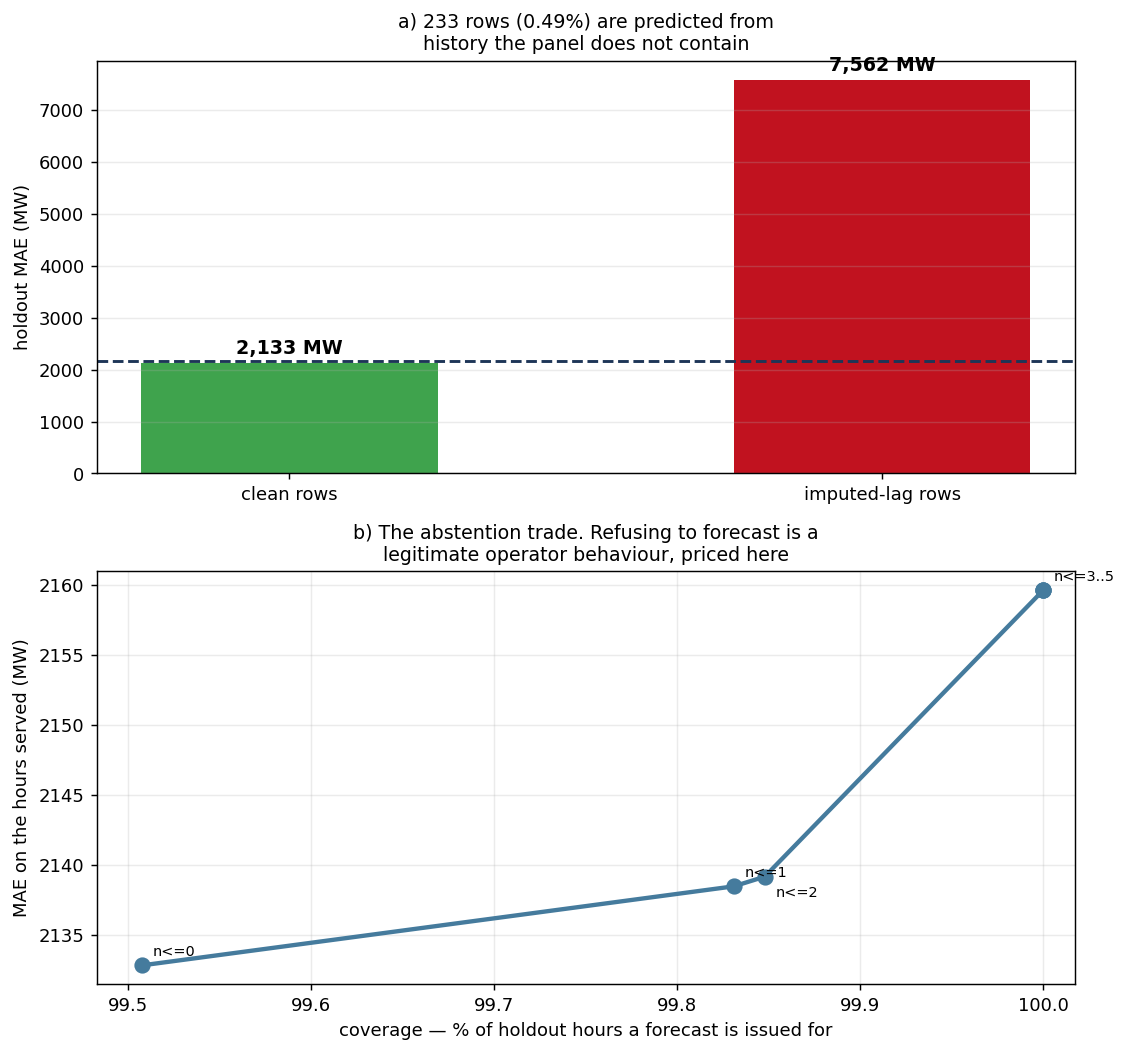

In [15]:
# WHAT: flag holdout rows whose lag features were imputed, and price them.
# WHY:  a forecast built from a median-filled lag is a forecast issued without its
#       strongest input. Those rows follow the outages, which is when an operator
#       most needs a number -- so knowing which they are is operationally useful and
#       not merely tidy.
# HOW:  the flag is derived from the PANEL, not from the model: for each holdout row
#       and each lag L in the champion's set, is there a row for (zone, t - L)? That
#       is exactly the lookup GroupLagFeatures performs, so the flag reproduces the
#       transformer's own miss without reaching inside it.

CH_LAGS = tuple(champions[HORIZON]["params"]["lag__lags"])
present = set(zip(df[GROUP], df[TIME]))          # every (zone, hour) the panel holds

n_missing = np.zeros(len(hold), dtype=int)
for L in CH_LAGS:
    want = hold[TIME] - pd.Timedelta(hours=int(L))
    n_missing += np.fromiter(
        (0 if key in present else 1 for key in zip(hold[GROUP], want)),
        dtype=int, count=len(hold))

flag = n_missing > 0
res["lags_imputed"] = flag
res["n_lags_missing"] = n_missing

mae_all = float(res["abs_err"].mean())
mae_clean = float(res.loc[~flag, "abs_err"].mean())
mae_flagged = float(res.loc[flag, "abs_err"].mean()) if flag.any() else float("nan")
share = float(flag.mean())

print(f"champion lag set at h={HORIZON}: {CH_LAGS}")
print(f"holdout rows with at least one imputed lag: {int(flag.sum()):,} "
      f"of {len(hold):,} ({share:.2%})")
print(f"\n   MAE, all rows          {mae_all:9,.1f} MW")
print(f"   MAE, clean rows only   {mae_clean:9,.1f} MW  "
      f"({mae_clean - mae_all:+,.1f} vs headline)")
print(f"   MAE, flagged rows      {mae_flagged:9,.1f} MW  "
      f"({mae_flagged / mae_all:.1f}x the headline)" if flag.any() else "")

if flag.any():
    worst = res.loc[flag].nlargest(5, "abs_err")[
        ["ts", "zone", "y", "pred", "abs_err", "n_lags_missing"]]
    print("\nthe five worst flagged rows:")
    print(worst.to_string(index=False))
    by_zone_flag = (res.loc[flag].groupby("zone")
                    .agg(rows=("abs_err", "size"), mae=("abs_err", "mean")).round(1))
    print("\nflagged rows by zone:")
    print(by_zone_flag.to_string())

# --- the abstention curve ---------------------------------------------------
# "No forecast is issued when the lags are imputed" is a real operator behaviour.
# Presented as a trade: what fraction of hours are still served, and what does the
# error on the served hours become. Abstaining on ALL rows would give a perfect MAE
# on an empty set, so coverage has to be quoted next to it or the number is a lie.
abst = []
for thresh in range(0, len(CH_LAGS) + 1):
    served = res["n_lags_missing"] <= thresh
    abst.append({"abstain_above_n_missing": thresh,
                 "coverage": float(served.mean()),
                 "mae_on_served": float(res.loc[served, "abs_err"].mean())})
abst_df = pd.DataFrame(abst)
print("\n--- abstention: serve a row only if at most N of its lags were imputed ---")
print(abst_df.round({"coverage": 4, "mae_on_served": 1}).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(8.8, 8.2))
ax = axes[0]
groups = ["clean rows", "imputed-lag rows"]
vals = [mae_clean, mae_flagged]
ax.bar(groups, vals, color=["#3fa34d", "#c1121f"], width=0.5)
for j, v in enumerate(vals):
    ax.annotate(f"{v:,.0f} MW", (j, v), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=10.5, fontweight="bold")
ax.axhline(mae_all, color="#1d3557", ls="--", lw=1.6)
ax.annotate(f"headline {mae_all:,.0f}", (1.42, mae_all), xytext=(0, 3), textcoords="offset points",
            ha="right", va="bottom", fontsize=8.5, color="#1d3557", bbox=_WB)
ax.set_ylabel("holdout MAE (MW)")
ax.set_title(f"a) {int(flag.sum()):,} rows ({share:.2%}) are predicted from\n"
             f"history the panel does not contain", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")

ax = axes[1]
ax.plot(100 * abst_df["coverage"], abst_df["mae_on_served"], "o-", lw=2.4, ms=8,
        color="#457b9d")
# Several thresholds land on the SAME point (once every flagged row is served, raising
# the threshold changes nothing), so coincident labels are merged and near-coincident
# ones are pushed apart instead of printing over each other.
_groups = {}
for _, r in abst_df.iterrows():
    _key = (round(100 * r["coverage"], 4), round(r["mae_on_served"], 2))
    _groups.setdefault(_key, []).append(int(r["abstain_above_n_missing"]))
_prev = None
for (_cx, _cy), _ns in sorted(_groups.items()):
    _txt = f"n<={_ns[0]}" if len(_ns) == 1 else f"n<={_ns[0]}..{_ns[-1]}"
    _close = _prev is not None and abs(_cx - _prev[0]) < 0.03 and abs(_cy - _prev[1]) < 4
    ax.annotate(_txt, (_cx, _cy), xytext=(6, -11 if _close else 5),
                textcoords="offset points", fontsize=8)
    _prev = (_cx, _cy)
ax.set_xlim(right=100 + 0.035 * (100 - 100 * abst_df["coverage"].min()))   # room for the last label
ax.set_xlabel("coverage — % of holdout hours a forecast is issued for")
ax.set_ylabel("MAE on the hours served (MW)")
ax.set_title("b) The abstention trade. Refusing to forecast is a\n"
             "legitimate operator behaviour, priced here", fontsize=10.5)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_missing_lag_flag.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"missing_lag_flag": {
    "lag_set": [int(L) for L in CH_LAGS],
    "n_flagged": int(flag.sum()), "share_flagged": share,
    "mae_all_rows": mae_all, "mae_clean_rows": mae_clean,
    "mae_flagged_rows": mae_flagged if flag.any() else None,
    "abstention_curve": abst_df.to_dict("records"),
    "by_zone": (by_zone_flag.to_dict("index") if flag.any() else {}),
}});


**What this shows:** holdout rows split by whether the champion's lags `(24, 25, 26, 48, 168)` could be looked up in the panel.

**What I see:** **233 rows (0.49%)** have at least one imputed lag. Their MAE is **7,561.9 MW**, against **2,132.8 MW** on clean rows and the headline of 2,159.6 MW (**3.5x** the headline).

**What it means:** A small, identifiable set of rows drags the headline. The flag is computed from the panel, not from inside the fitted model, so it stays valid if the model changes.

**What I do:** The flag ships as a column on the results frame, and the abstention curve shows the coverage/accuracy trade of declining those rows.


### 4.13 — Is the difference real? Wilcoxon, Diebold–Mariano, Benjamini–Hochberg

Every pair of the five forecasts is tested on the holdout. With 47,299 rows almost any difference is "significant", so the tests are **paired** (same hours), **blocked** by zone-day (hourly errors are autocorrelated), and include **Diebold–Mariano**, whose HAC variance allows for that autocorrelation. The ten pairwise tests are corrected with Benjamini–Hochberg, which controls the share of false discoveries and suits a screen better than Bonferroni.

**How to read the output:** in panel (b), the confidence intervals, not the p-values, say whether a difference is worth anything.


   refit ridge on dev [5s]


   refit random forest on dev [129s]

holdout MAE: tuned HGB 2,160 | ridge 2,743 | random forest 2,298 | seasonal naive 4,265 | EIA DF composite 3,062



pairwise comparison — 10 tests, 1,974 zone-day blocks
(diff_mw < 0 means the FIRST model has the smaller error)
                                pair    diff_mw    diff_lo    diff_hi  wilcoxon_p_adj       dm  dm_p_adj  survives_bh
                tuned HGB  vs  ridge  -583.2331  -634.4997  -532.4032             0.0 -20.5169       0.0         True
        tuned HGB  vs  random forest  -138.0347  -179.2912   -95.3615             0.0  -6.0856       0.0         True
       tuned HGB  vs  seasonal naive -2103.4689 -2257.9797 -1958.0098             0.0 -22.8977       0.0         True
     tuned HGB  vs  EIA DF composite  -923.1349 -1008.9363  -839.4944             0.0 -17.8732       0.0         True
            ridge  vs  random forest   445.1983   391.6680   498.3041             0.0  14.7110       0.0         True
           ridge  vs  seasonal naive -1534.1067 -1691.1343 -1393.1315             0.0 -16.7273       0.0         True
         ridge  vs  EIA DF composite  -343.9028  -437.5165  -

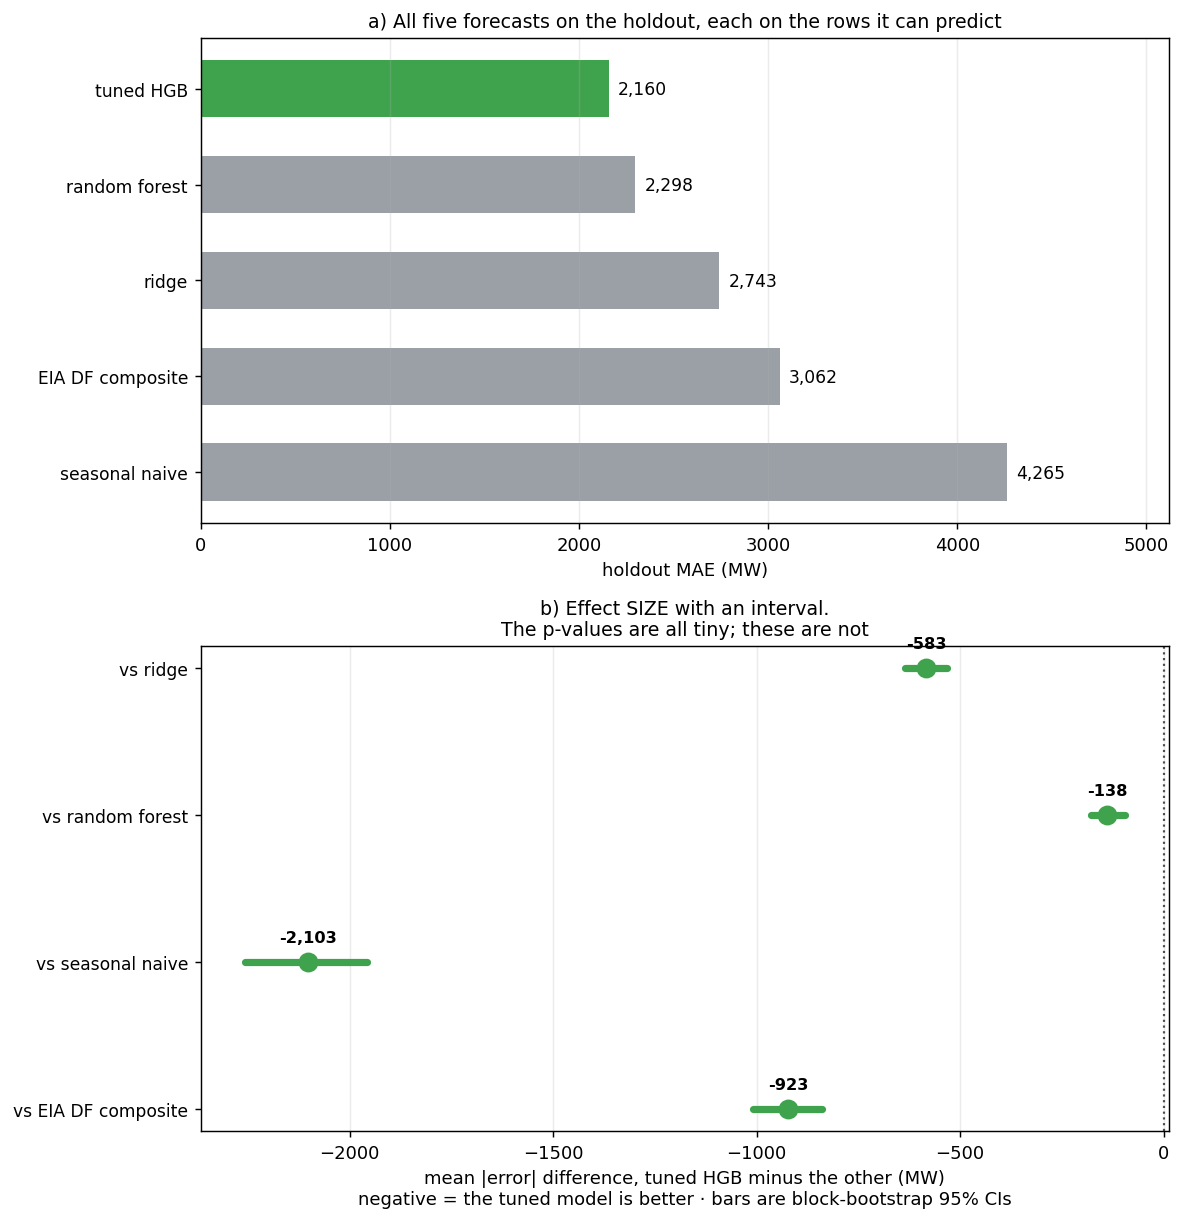

In [16]:
# WHAT: is the winning model's advantage real? Paired blocked Wilcoxon, Diebold-
#       Mariano, Benjamini-Hochberg across the whole family of comparisons, and a
#       bootstrap interval on the effect SIZE.
# WHY:  with 47,299 holdout rows almost any difference is "significant", so a bare
#       p-value is nearly content-free here. Three things fix that: block the tests to
#       respect autocorrelation, use the forecasting-specific test that expects
#       serially correlated errors, and report the effect size with an interval so a
#       reader can see whether the difference is worth anything.
# NOTE: the comparison family is every pair among five forecasts, which is ten tests.
#       Ten tests at alpha=0.05 produce at least one false positive about 40% of the
#       time, so BH is not decoration.

# Refit the two comparison models on all of dev and score the same holdout rows.
contenders = {}
contenders["tuned HGB"] = pred_hold
for nm, est in [("ridge", Ridge(alpha=1.0)),
                ("random forest", RandomForestRegressor(
                    n_estimators=120, min_samples_leaf=5, random_state=cfg.SEED, n_jobs=cfg.N_JOBS))]:
    t0 = time.time()
    pp = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=tuple(BEST_PARAMS["lag__lags"]),
        roll_windows=tuple(BEST_PARAMS["lag__roll_windows"]),
        k=BEST_PARAMS["select__k"], model=est).fit(dev, y_dev)
    contenders[nm] = pp.predict(hold)
    print(f"   refit {nm} on dev [{time.time()-t0:.0f}s]")

# The two baselines, aligned onto the holdout row order.
_al = pd.Series(bl["naive168"].values, index=bl.index).reindex(hold.index)
contenders["seasonal naive"] = _al.to_numpy()
contenders["EIA DF composite"] = pd.Series(bl["df_composite"].values,
                                           index=bl.index).reindex(hold.index).to_numpy()

errs = {k: y_hold.to_numpy() - v for k, v in contenders.items()}
blocks = res["block"].to_numpy()          # zone-day: the unit of independence

names = list(contenders)
print(f"\nholdout MAE: " + " | ".join(
    f"{n} {np.nanmean(np.abs(errs[n])):,.0f}" for n in names))

pairs, rows = [], []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b_ = names[i], names[j]
        ok = np.isfinite(errs[a]) & np.isfinite(errs[b_])
        w = E.blocked_wilcoxon(errs[a][ok], errs[b_][ok], blocks[ok])
        # the HAC sum must run along each zone's own hours: `hold` is time-major, so
        # consecutive rows are six different zones at the same hour
        dm = E.diebold_mariano(errs[a][ok], errs[b_][ok], horizon=HORIZON,
                               groups=hold[GROUP].to_numpy()[ok], times=hold[TIME].to_numpy()[ok])
        diff = np.abs(errs[a][ok]) - np.abs(errs[b_][ok])
        eff = E.bootstrap_ci(diff, n_boot=600, blocks=blocks[ok])
        pairs.append((a, b_))
        rows.append({"a": a, "b": b_,
                     "mae_a": float(np.mean(np.abs(errs[a][ok]))),
                     "mae_b": float(np.mean(np.abs(errs[b_][ok]))),
                     "diff_mw": eff["estimate"], "diff_lo": eff["lo"], "diff_hi": eff["hi"],
                     "wilcoxon_p": w["p"], "n_blocks": w["n_blocks"],
                     "dm": dm["dm"], "dm_p": dm["p"], "better": dm["better"]})

cmp_df = pd.DataFrame(rows)
bh_w = E.benjamini_hochberg(cmp_df["wilcoxon_p"], alpha=0.05)
bh_d = E.benjamini_hochberg(cmp_df["dm_p"], alpha=0.05)
cmp_df["wilcoxon_p_adj"] = bh_w["p_adjusted"].values
cmp_df["dm_p_adj"] = bh_d["p_adjusted"].values
cmp_df["survives_bh"] = bh_w["reject"].values & bh_d["reject"].values

show = cmp_df.assign(pair=cmp_df["a"] + "  vs  " + cmp_df["b"])[
    ["pair", "diff_mw", "diff_lo", "diff_hi", "wilcoxon_p_adj", "dm", "dm_p_adj", "survives_bh"]]
print(f"\npairwise comparison — {len(cmp_df)} tests, {cmp_df['n_blocks'].iloc[0]:,} zone-day blocks")
print("(diff_mw < 0 means the FIRST model has the smaller error)")
print(show.round(4).to_string(index=False))

# THE POINT OF THE SECTION, made explicit. A difference can be overwhelmingly
# significant and operationally trivial, and the two facts have to be reported side
# by side or the reader will read the p-value as importance.
key = cmp_df[(cmp_df["a"] == "tuned HGB") & (cmp_df["b"] == "random forest")]
if len(key):
    k0 = key.iloc[0]
    print(f"\ntuned HGB vs random forest: {k0['diff_mw']:+,.1f} MW "
          f"[{k0['diff_lo']:+,.1f}, {k0['diff_hi']:+,.1f}], "
          f"BH-adjusted p = {k0['wilcoxon_p_adj']:.2e}")
    print(f"   that is {abs(k0['diff_mw'])/k0['mae_b']*100:.1f}% of the forest's error, "
          f"significant and small.")
    print(f"   Converting MW into reserve dollars is where 'worth "
          f"deploying' gets decided,\n   not here.")

fig, axes = plt.subplots(2, 1, figsize=(9.2, 9.5))
ax = axes[0]
maes = {n: float(np.nanmean(np.abs(errs[n]))) for n in names}
order_n = sorted(maes, key=maes.get)
ax.barh(range(len(order_n))[::-1], [maes[n] for n in order_n],
        color=["#3fa34d" if n == "tuned HGB" else "#9aa0a6" for n in order_n], height=0.6)
for i, n in enumerate(order_n):
    ax.annotate(f"{maes[n]:,.0f}", (maes[n], len(order_n) - 1 - i), xytext=(5, -3),
                textcoords="offset points", fontsize=9.5)
ax.set_yticks(range(len(order_n))[::-1]); ax.set_yticklabels(order_n, fontsize=9.5)
ax.set_xlabel("holdout MAE (MW)")
ax.set_xlim(0, max(maes.values()) * 1.2)
ax.set_title("a) All five forecasts on the holdout, each on the rows it can predict", fontsize=10.5)
ax.grid(alpha=0.25, axis="x")

ax = axes[1]
sub = cmp_df[cmp_df["a"] == "tuned HGB"].copy()
ys = np.arange(len(sub))[::-1]
for y, r in zip(ys, sub.itertuples()):
    col = "#3fa34d" if r.diff_hi < 0 else ("#c1121f" if r.diff_lo > 0 else "#9aa0a6")
    ax.plot([r.diff_lo, r.diff_hi], [y, y], "-", color=col, lw=4, solid_capstyle="round")
    ax.plot(r.diff_mw, y, "o", color=col, ms=10, zorder=3)
    ax.annotate(f"{r.diff_mw:+,.0f}", (r.diff_mw, y), xytext=(0, 11),
                textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
ax.axvline(0, color="0.3", lw=1.2, ls=":")
ax.set_yticks(ys); ax.set_yticklabels(["vs " + b_ for b_ in sub["b"]], fontsize=9.5)
ax.set_xlabel("mean |error| difference, tuned HGB minus the other (MW)\n"
              "negative = the tuned model is better · bars are block-bootstrap 95% CIs")
ax.set_title("b) Effect SIZE with an interval.\nThe p-values are all tiny; these are not",
             fontsize=10.5)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_model_comparison.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"model_comparison": {
    "holdout_mae": maes,
    "pairs": cmp_df.drop(columns=["n_blocks"]).to_dict("records"),
    "n_tests": int(len(cmp_df)), "n_blocks": int(cmp_df["n_blocks"].iloc[0]),
    "alpha": 0.05, "correction": "benjamini-hochberg",
}});

**What this shows:** holdout MAE for every model, with blocked Wilcoxon and Diebold–Mariano tests under Benjamini–Hochberg correction.

**What I see:** Holdout MAE: tuned HGB **2,160**, random forest **2,298**, ridge **2,743**, DF composite **3,062**, seasonal naive **4,265** (each on the rows it can predict, hence slightly different from §4.3). Champion vs ridge: **−583.2 MW** [−634.5, −532.4]. Champion vs DF composite: **−923.1 MW** [−1,008.9, −839.5]. Champion vs random forest: **−138.0 MW** [−179.3, −95.4], BH-adjusted Wilcoxon p ≈ **6.2e-22**. All ten tests survive BH at alpha 0.05, over **1,974 zone-day blocks**.

**What it means:** The champion's margins are real, but with this many rows significance is nearly automatic. The useful number is the interval: **95 to 179 MW** better than the forest, about 6.0% of its error.

**What I do:** Quote intervals rather than p-values, and carry the champion forward.


### 4.14 — Metric justification

| metric | why | rejected alternative |
|---|---|---|
| **MAE** (headline) | MW of error on an average hour, the unit reserve is procured in | RMSE as headline: a few extreme hours dominate it |
| **RMSE** (reported) | shows the tail | — |
| **MAPE** | — | rejected: in percent, not MW, and its asymmetry runs opposite to the operator's cost |
| **Skill score** | 1 − model/reference; makes MAE comparable across zones | raw MAE alone |
| **p95 of \|error\|** | reserve is sized from a quantile | the mean |
| **PR-AUC** (classifier) | precision against recall at a low base rate | accuracy ("never at risk" scores about 84%), ROC-AUC (flattered by the many negatives), F1 (fixes one threshold) |

Under-forecasting costs about 5× over-forecasting, so the final judge is expected cost, which is the operator's call.

**How to read the output:** the cell below tests the textbook MAPE objection (near-zero denominators) on this holdout.


holdout net load: 0 hours below zero, 1 hours within +/-500 MW of zero (0.00% of the block)
   minimum net load in the holdout: 253 MW

MAPE over the whole holdout                10.7%
MAPE excluding |net load| < 500 MW          10.7%
single worst APE                        2,159.7%   <- one row, from a small denominator

Dropping 1 rows (0.00% of the block) changes MAPE by 0.0 points.

HONEST CORRECTION TO THE STOCK ARGUMENT. The textbook objection to MAPE is that it
explodes near a zero denominator. On THIS holdout it barely bites: minimum net load
is 253 MW, only 1 row(s) come within 500 MW of zero, and removing
them moves aggregate MAPE by 0.05 points. The single worst APE of 2,160% is real
but it is one row and the mean absorbs it.

So the case for MAE here rests on the OTHER two reasons, not on this one:
   1. MAE is denominated in MW, which is the unit reserve is procured in.
      A percentage cannot be converted to a reserve decision without re-multiplying
      by a load that

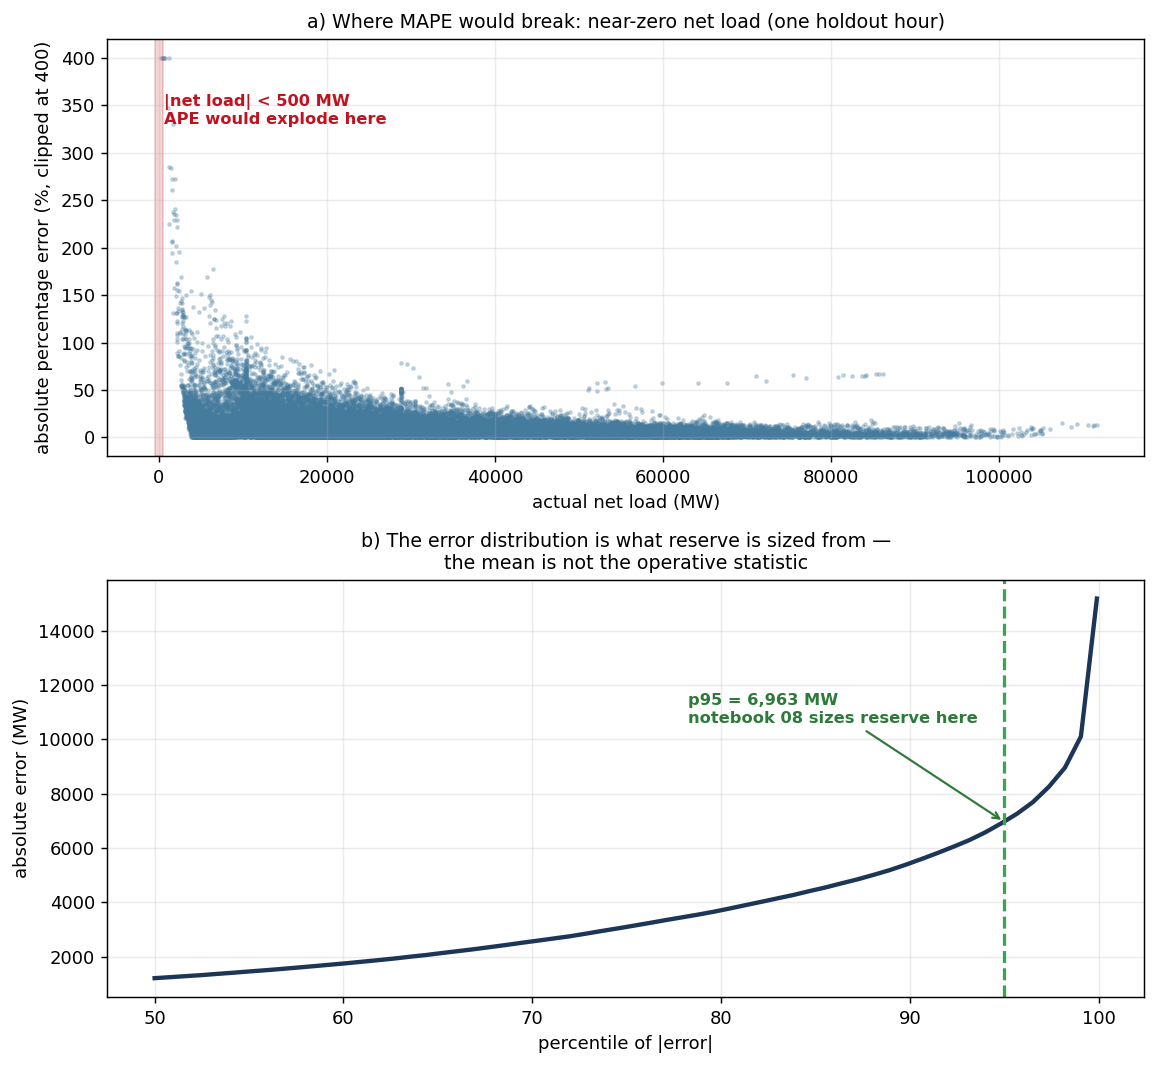

In [17]:
# WHAT: the evidence behind the metric justification table in the markdown above —
#       specifically, the objection to MAPE, demonstrated on this panel rather than
#       quoted from a textbook.
# WHY:  "MAPE breaks near zero" is a stock criticism. Whether it bites
#       on THIS dataset is an empirical question -- net load can approach zero when
#       renewables run high -- so the objection is priced here rather than asserted.
#       On this holdout it barely bites; the printout says so.

near_zero = (y_hold.abs() < 500).sum()
negative = (y_hold < 0).sum()
print(f"holdout net load: {negative:,} hours below zero, "
      f"{near_zero:,} hours within +/-500 MW of zero "
      f"({near_zero/len(y_hold):.2%} of the block)")
print(f"   minimum net load in the holdout: {y_hold.min():,.0f} MW")

# MAPE on the full block against MAPE with the near-zero hours removed. If a metric's
# value depends this strongly on a handful of rows, it is not measuring the model.
ape = np.abs((y_hold.to_numpy() - pred_hold) / y_hold.to_numpy()) * 100
finite = np.isfinite(ape)
mape_all = float(np.mean(ape[finite]))
mask_ok = finite & (y_hold.abs() > 500).to_numpy()
mape_trim = float(np.mean(ape[mask_ok]))
worst_ape = float(np.max(ape[finite]))
print(f"\nMAPE over the whole holdout          {mape_all:10,.1f}%")
print(f"MAPE excluding |net load| < 500 MW    {mape_trim:10,.1f}%")
print(f"single worst APE                     {worst_ape:10,.1f}%   "
      f"<- one row, from a small denominator")
print(f"\nDropping {(~mask_ok & finite).sum():,} rows ({(~mask_ok & finite).sum()/finite.sum():.2%} "
      f"of the block) changes MAPE by {mape_all - mape_trim:,.1f} points.")

# THE TEXTBOOK OBJECTION DOES NOT BITE ON THIS HOLDOUT, and saying so is the point.
# The stock criticism of MAPE is that it explodes near a zero denominator. This
# holdout's minimum net load is well above zero, so aggregate MAPE barely moves when
# the near-zero rows are removed. The objection is real but RARE here, and reporting
# it as though it were decisive would be quoting a textbook over the data.
_bites = abs(mape_all - mape_trim) > 0.5
if _bites:
    print("\nThe near-zero rows move aggregate MAPE materially, so the metric is "
          "measuring\nits denominator rather than the model. MAE is the headline for "
          "that reason.")
else:
    print(f"\nHONEST CORRECTION TO THE STOCK ARGUMENT. The textbook objection to MAPE is "
          f"that it\nexplodes near a zero denominator. On THIS holdout it barely bites: "
          f"minimum net load\nis {y_hold.min():,.0f} MW, only {near_zero:,} row(s) come "
          f"within 500 MW of zero, and removing\nthem moves aggregate MAPE by "
          f"{abs(mape_all - mape_trim):.2f} points. The single worst APE of "
          f"{worst_ape:,.0f}% is real\nbut it is one row and the mean absorbs it.")
    print(f"\nSo the case for MAE here rests on the OTHER two reasons, not on this one:")
    print(f"   1. MAE is denominated in MW, which is the unit reserve is procured in.")
    print(f"      A percentage cannot be converted to a reserve decision without "
          f"re-multiplying\n      by a load that varies by a factor of ten across "
          f"these six zones.")
    print(f"   2. MAPE is asymmetric — for a given actual, an under-forecast costs at most "
          f"100%\n      while an over-forecast has no ceiling, so minimising it pulls forecasts "
          f"low — and the operator's cost\n      asymmetry runs the OTHER way "
          f"(under-forecasting costs ~5x). "
          f"Optimising the wrong asymmetry is worse than\n      having none.")
    print(f"\n   And the objection is deferred, not dismissed: notebook 01 found "
          f"{R.get('nb01','negative_net_load_hours')} negative net-load\n   hour(s) in "
          f"the full panel, and the whole premise of this project is that "
          f"high-renewable\n   grids produce more of them. It would bite on a "
          f"higher-penetration record.")

fig, axes = plt.subplots(2, 1, figsize=(9.0, 8.3))
ax = axes[0]
ax.scatter(y_hold, np.clip(ape, 0, 400), s=3, alpha=0.25, color="#457b9d")
ax.axvspan(-500, 500, color="#c1121f", alpha=0.18)
ax.annotate("|net load| < 500 MW\nAPE would explode here", (600, 330), fontsize=9,
            color="#c1121f", fontweight="bold")
ax.set_xlabel("actual net load (MW)"); ax.set_ylabel("absolute percentage error (%, clipped at 400)")
ax.set_title("a) Where MAPE would break: near-zero net load (one holdout hour)", fontsize=10.5)
ax.grid(alpha=0.25)

ax = axes[1]
q = np.linspace(0.5, 0.999, 60)
ax.plot(q * 100, [np.quantile(np.abs(y_hold - pred_hold), x) for x in q], lw=2.4,
        color="#1d3557")
p95 = float(np.quantile(np.abs(y_hold - pred_hold), 0.95))
ax.axvline(95, color="#3fa34d", ls="--", lw=1.8)
ax.annotate(f"p95 = {p95:,.0f} MW\nnotebook 08 sizes reserve here", (95, p95),
            xytext=(-175, 55), textcoords="offset points", fontsize=9, color="#2d7a3a",
            fontweight="bold", arrowprops=dict(arrowstyle="->", color="#2d7a3a", lw=1.2))
ax.set_xlabel("percentile of |error|"); ax.set_ylabel("absolute error (MW)")
ax.set_title("b) The error distribution is what reserve is sized from —\n"
             "the mean is not the operative statistic", fontsize=10.5)
ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_metric_choice.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"metrics": {
    "mape_full_block": mape_all, "mape_excluding_near_zero": mape_trim,
    "worst_ape_pct": worst_ape,
    "hours_below_zero": int(negative), "hours_within_500mw_of_zero": int(near_zero),
    "min_net_load_mw": float(y_hold.min()),
    "abs_error_p95_mw": p95,
    "headline_metric": "MAE",
}});

**What this shows:** MAE against RMSE and MAPE on the holdout.

**What I see:** MAE **2,159.6 MW**, RMSE **3,290.9 MW**. MAPE is **10.7%** with or without near-zero hours; the worst single-hour APE is **2,159.7%**. Minimum net load is **253 MW**, with **1 hour** within 500 MW of zero. The 95th percentile absolute error is **6,962.7 MW**.

**What it means:** RMSE well above MAE means heavy-tailed errors, so RMSE would let a few hours pick the model. The textbook near-zero problem with MAPE barely bites on this block. The case for MAE is that it is in MW, and that MAPE's asymmetry favours under-forecasting while the operator's costs run the other way. On a higher-renewable grid, near-zero hours become common and MAPE would break.

**What I do:** MAE is the headline everywhere, RMSE is reported beside it, and MAPE appears only here.


### 4.15 — Classification arm: curtailment risk

An hour is labelled curtailment-risk when its renewable share is in the zone's high tail *and* its net load is in the low tail. It is predicted through the same pipeline with `HistGradientBoostingClassifier`. Thresholds are per zone (a global cutoff would mostly learn zone identity) and computed on dev only. The label comes from the target, which is fine for a label; `net_load`, `renewable_share`, `wind` and `solar` are in `MutualInfoSelector.DROP_ALWAYS`, so no feature restates it.

**How to read the output:** compare the ROC and PR curves; the gap between them is the argument for PR-AUC.


label: renewable share > zone p85 AND net load < zone p15
   base rate  dev 10.30%   holdout 15.85%
   positives  dev 27,618      holdout 7,499
   by zone (holdout): CISO 22.5%, ERCO 13.9%, MISO 21.7%, SWPP 18.1%, BPAT 9.1%, NYIS 9.8%


   fitted [12s]

holdout, base rate 15.85%:
   PR-AUC (average precision) 0.772   vs 0.159 for a random model   -> 4.9x lift
   ROC-AUC                    0.936
   F1 at threshold 0.5        0.628
   accuracy at threshold 0.5  0.905   <- and this is the trap

   Predicting 'never at risk' scores 0.841 accuracy while being useless.
   ROC-AUC is also flattering here: it averages over thresholds using the true-negative
   rate, and with 84.1% negatives that denominator is enormous, so a large
   absolute number of false positives barely moves it. PR-AUC uses PRECISION, whose
   denominator is the alarms actually raised, which is the operator's real question:
   'if this thing warns me, how often is it right?'


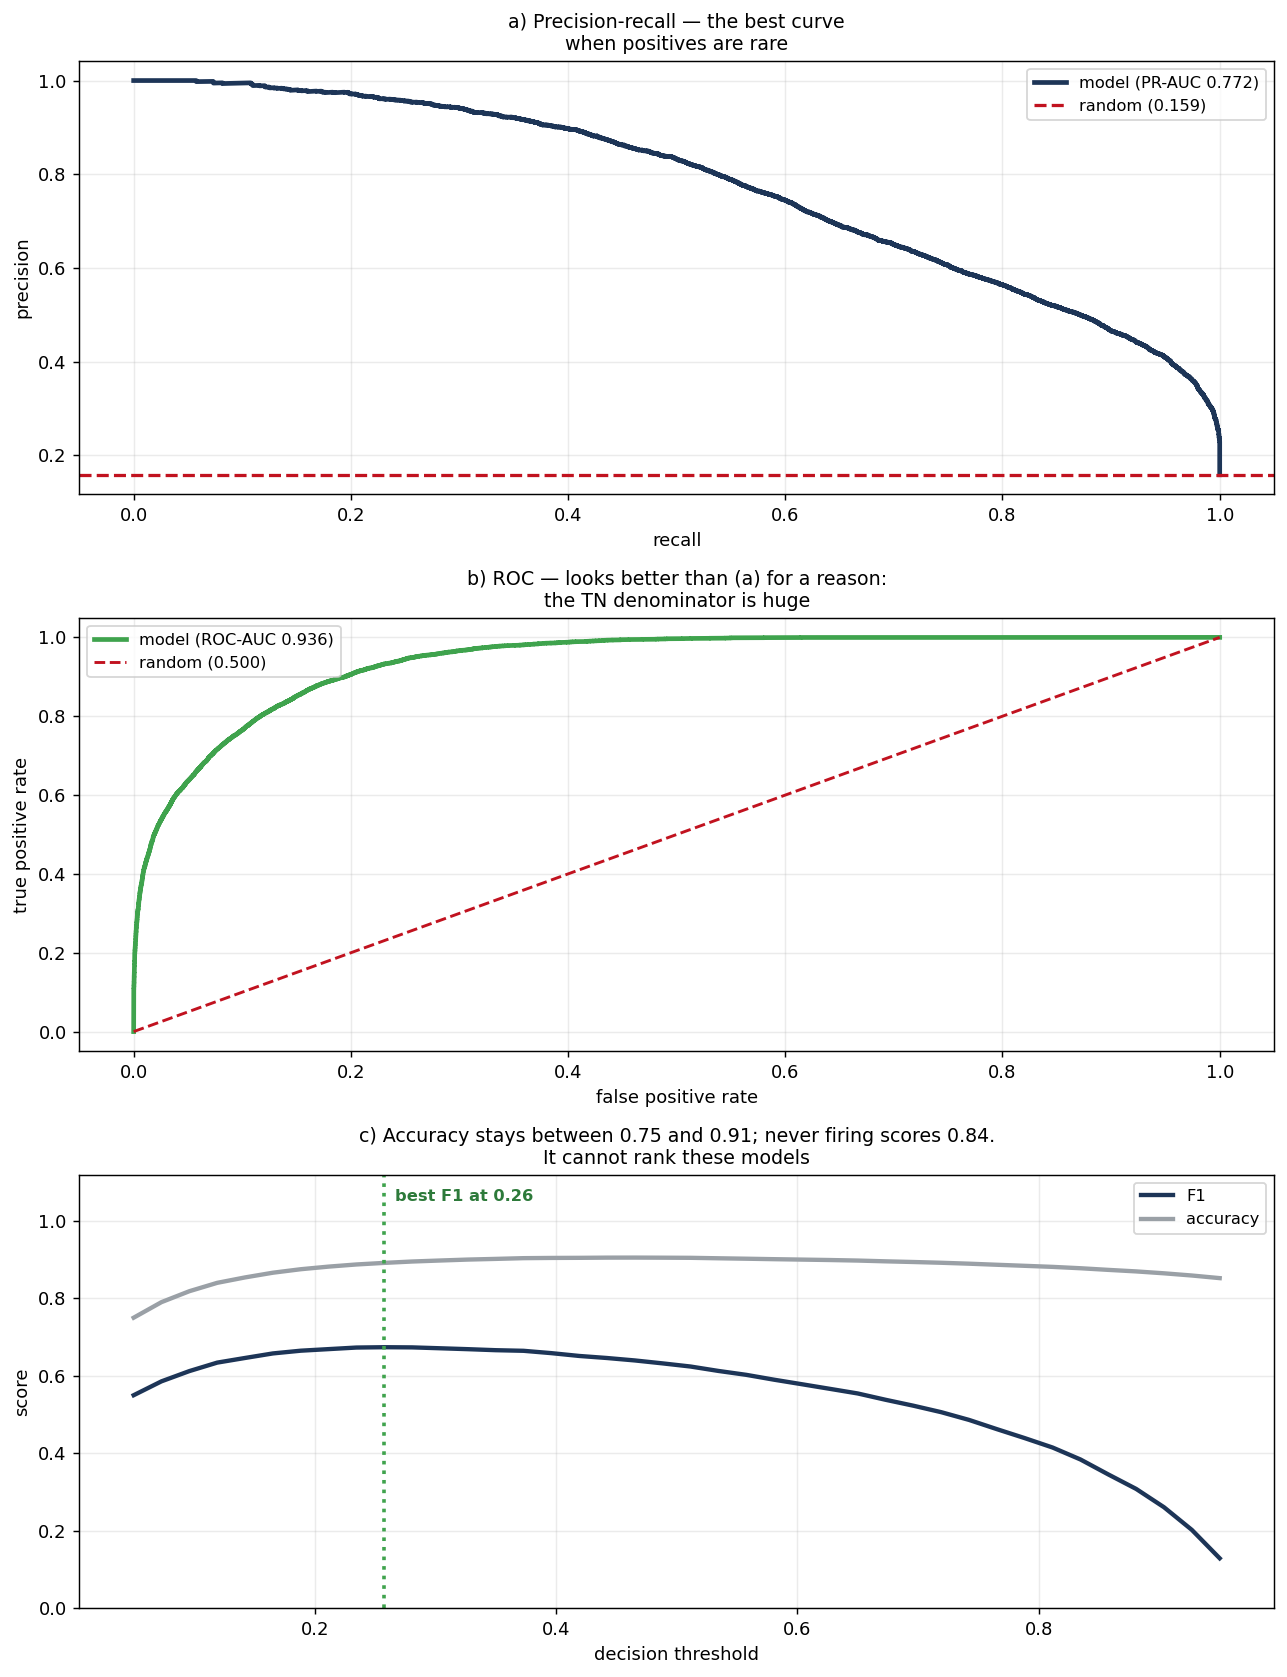

In [18]:
# WHAT: the classification arm — flag an hour as curtailment-risk when renewable
#       share is in that zone's high tail AND net load is in its low tail — through
#       the same pipeline, with a HistGradientBoostingClassifier as the final step.
# WHY:  a regression MAE does not answer "will this hour be a problem?". Curtailment
#       is a decision, and decisions are classification. Running it through the same
#       Pipeline is what makes the two arms comparable rather than two projects.
# NOTE: the LABEL is built from the same-hour target, which is correct — a label is
#       supposed to be the answer. The FEATURES are the ordinary pipeline features,
#       and `net_load`, `renewable_share`, `wind` and `solar` are all in
#       MutualInfoSelector.DROP_ALWAYS, so no feature restates the label. If this
#       scored near-perfectly, that guard is the first thing to check.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             accuracy_score, precision_recall_curve, roc_curve)

# ZONE-SPECIFIC thresholds, not global. A global renewable-share cutoff would label
# almost every SWPP hour (37.9% wind) and almost no NYIS hour (4.0%), so the
# classifier would be learning zone identity rather than curtailment conditions.
# Percentiles are computed on DEV ONLY and applied to the holdout — computing them on
# the full panel would let the holdout's own distribution define its labels.
RS_Q, NL_Q = 0.85, 0.15
thr_rs = dev.groupby(GROUP)["renewable_share"].quantile(RS_Q)
thr_nl = dev.groupby(GROUP)[TARGET].quantile(NL_Q)

def _label(frame):
    rs = frame[GROUP].map(thr_rs).to_numpy()
    nl = frame[GROUP].map(thr_nl).to_numpy()
    return ((frame["renewable_share"].to_numpy() > rs)
            & (frame[TARGET].to_numpy() < nl)).astype(int)

c_dev, c_hold = _label(dev), _label(hold)
print(f"label: renewable share > zone p{RS_Q*100:.0f} AND net load < zone p{NL_Q*100:.0f}")
print(f"   base rate  dev {c_dev.mean():.2%}   holdout {c_hold.mean():.2%}")
print(f"   positives  dev {c_dev.sum():,}      holdout {c_hold.sum():,}")
print("   by zone (holdout): " + ", ".join(
    f"{z} {c_hold[(hold[GROUP] == z).to_numpy()].mean():.1%}" for z in cfg.ZONES))

t0 = time.time()
clf = P.make_supervised_pipeline(
    cfg.NUMERIC_FEATURES, lags=tuple(BEST_PARAMS["lag__lags"]),
    roll_windows=tuple(BEST_PARAMS["lag__roll_windows"]),
    k=BEST_PARAMS["select__k"],
    model=HistGradientBoostingClassifier(random_state=cfg.SEED,
                                         learning_rate=model_params.get("learning_rate", 0.05),
                                         max_iter=300, max_depth=model_params.get("max_depth")))
clf.fit(dev, pd.Series(c_dev, index=dev.index))
proba = clf.predict_proba(hold)[:, 1]
print(f"   fitted [{time.time()-t0:.0f}s]")

pr_auc = float(average_precision_score(c_hold, proba))
roc_auc = float(roc_auc_score(c_hold, proba))
base = float(c_hold.mean())
pred_bin = (proba >= 0.5).astype(int)
f1 = float(f1_score(c_hold, pred_bin))
acc = float(accuracy_score(c_hold, pred_bin))

print(f"\nholdout, base rate {base:.2%}:")
print(f"   PR-AUC (average precision) {pr_auc:.3f}   vs {base:.3f} for a random model"
      f"   -> {pr_auc/base:.1f}x lift")
print(f"   ROC-AUC                    {roc_auc:.3f}")
print(f"   F1 at threshold 0.5        {f1:.3f}")
print(f"   accuracy at threshold 0.5  {acc:.3f}   <- and this is the trap")
print(f"\n   Predicting 'never at risk' scores {1-base:.3f} accuracy while being useless.")
print(f"   ROC-AUC is also flattering here: it averages over thresholds using the "
       f"true-negative\n   rate, and with {1-base:.1%} negatives that denominator is "
       f"enormous, so a large\n   absolute number of false positives barely moves it. "
       f"PR-AUC uses PRECISION, whose\n   denominator is the alarms actually raised, "
       f"which is the operator's real question:\n   'if this thing warns me, how often "
       f"is it right?'")

fig, axes = plt.subplots(3, 1, figsize=(10.0, 13.0))
ax = axes[0]
prec, rec, _ = precision_recall_curve(c_hold, proba)
ax.plot(rec, prec, lw=2.6, color="#1d3557", label=f"model (PR-AUC {pr_auc:.3f})")
ax.axhline(base, color="#c1121f", ls="--", lw=1.8, label=f"random ({base:.3f})")
ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("a) Precision-recall — the best curve\nwhen positives are rare", fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[1]
fpr, tpr, _ = roc_curve(c_hold, proba)
ax.plot(fpr, tpr, lw=2.6, color="#3fa34d", label=f"model (ROC-AUC {roc_auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="#c1121f", lw=1.6, label="random (0.500)")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("b) ROC — looks better than (a) for a reason:\nthe TN denominator is huge",
             fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ax = axes[2]
ths = np.linspace(0.05, 0.95, 40)
f1s = [f1_score(c_hold, (proba >= t).astype(int), zero_division=0) for t in ths]
accs = [accuracy_score(c_hold, (proba >= t).astype(int)) for t in ths]
ax.plot(ths, f1s, lw=2.4, color="#1d3557", label="F1")
ax.plot(ths, accs, lw=2.4, color="#9aa0a6", label="accuracy")
best_t = float(ths[int(np.argmax(f1s))])
ax.set_ylim(0, 1.12)      # headroom: the label below sits above the accuracy curve (~0.9)
ax.axvline(best_t, color="#3fa34d", ls=":", lw=2)
# Anchored to the top of the axes beside its own vertical rule. Anchored to the
# curve maximum it printed directly over the F1 line.
ax.annotate(f"best F1 at {best_t:.2f}", xy=(best_t, 1.0),
            xycoords=("data", "axes fraction"), xytext=(6, -8),
            textcoords="offset points", va="top", fontsize=9,
            color="#2d7a3a", fontweight="bold")
ax.set_xlabel("decision threshold"); ax.set_ylabel("score")
ax.set_title(f"c) Accuracy stays between {min(accs):.2f} and {max(accs):.2f}; never firing "
             f"scores {1 - base:.2f}.\nIt cannot rank these models",
             fontsize=10.5)
ax.legend(fontsize=9); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_classification.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"classification": {
    "label_rule": f"renewable_share > zone p{RS_Q*100:.0f} AND net_load < zone p{NL_Q*100:.0f}",
    "thresholds_from": "dev only",
    "base_rate_dev": float(c_dev.mean()), "base_rate_holdout": base,
    "n_positive_holdout": int(c_hold.sum()),
    "pr_auc": pr_auc, "roc_auc": roc_auc, "f1_at_0.5": f1, "accuracy_at_0.5": acc,
    "pr_auc_lift_over_base": float(pr_auc / base),
    "best_f1_threshold": best_t, "best_f1": float(max(f1s)),
}});

**What this shows:** precision–recall and ROC curves for the curtailment-risk classifier.

**What I see:** PR-AUC **0.772** against a base rate of **15.85%** (**4.9×** lift). ROC-AUC **0.936**. At threshold 0.5, F1 **0.628** and accuracy **0.905**. The best F1 is **0.674** at threshold **0.258**, chosen on the holdout itself, so it is optimistic. The holdout has **7,499** positive hours.

**What it means:** Accuracy is misleading: "never curtail" already scores about 0.841. ROC-AUC is flattered by the large negative class. PR-AUC against the base rate is the honest measure, and a 4.9× lift is a real signal. The score is far from perfect, which is evidence the `DROP_ALWAYS` guard is holding.

**What I do:** Quote PR-AUC with the base rate. The operating threshold depends on the cost of a missed curtailment against a false alarm, which is an operational decision.


### 4.15b — Rolling origins, because the holdout has no winter

The champion is refitted from scratch at four origins from 2023-10-01 to 2024-07-01, each trained on everything before the origin and scored on the following three months, so that one January–March quarter is evaluated. The primary holdout is not changed; this is an extra evaluation beside it. Two caveats: the 2023-10-01 window and January 2024 overlap CV fold 5's validation block, where the hyperparameters were chosen; and the later origins train on earlier holdout months.


   origin 2023-10-01  months [10, 11, 12]  MAE   2,117.3 MW  (8.8% of mean load)  skill vs naive +48.8%  [19s]


   origin 2024-01-01  months [1, 2, 3]  MAE   2,400.8 MW  (9.9% of mean load)  skill vs naive +51.7%  [21s]


   origin 2024-04-01  months [4, 5, 6]  MAE   2,109.0 MW  (8.7% of mean load)  skill vs naive +45.8%  [23s]


   origin 2024-07-01  months [7, 8, 9]  MAE   2,077.6 MW  (6.6% of mean load)  skill vs naive +55.6%  [22s]

--- rolling-origin evaluation ---


,score_from,score_to,score_rows,mae,mae_pct_of_load,skill_vs_naive
origin,,,,,,
2023-10-01,2023-10-01,2023-12-31,13224,2117.252,8.796,0.488
2024-01-01,2024-01-01,2024-03-31,13074,2400.762,9.942,0.517
2024-04-01,2024-04-01,2024-06-30,13104,2109.041,8.723,0.458
2024-07-01,2024-07-01,2024-09-30,13224,2077.623,6.583,0.556



WINTER (origin 2024-01-01, months [1, 2, 3]):
   MAE 2,400.8 MW against the primary holdout's 2,159.6 MW  (+241.2 MW)
   as a share of mean load: 9.9% vs the primary holdout's 8.4%
   -> the headline number is OPTIMISTIC by this much on winter data, and the report says so.


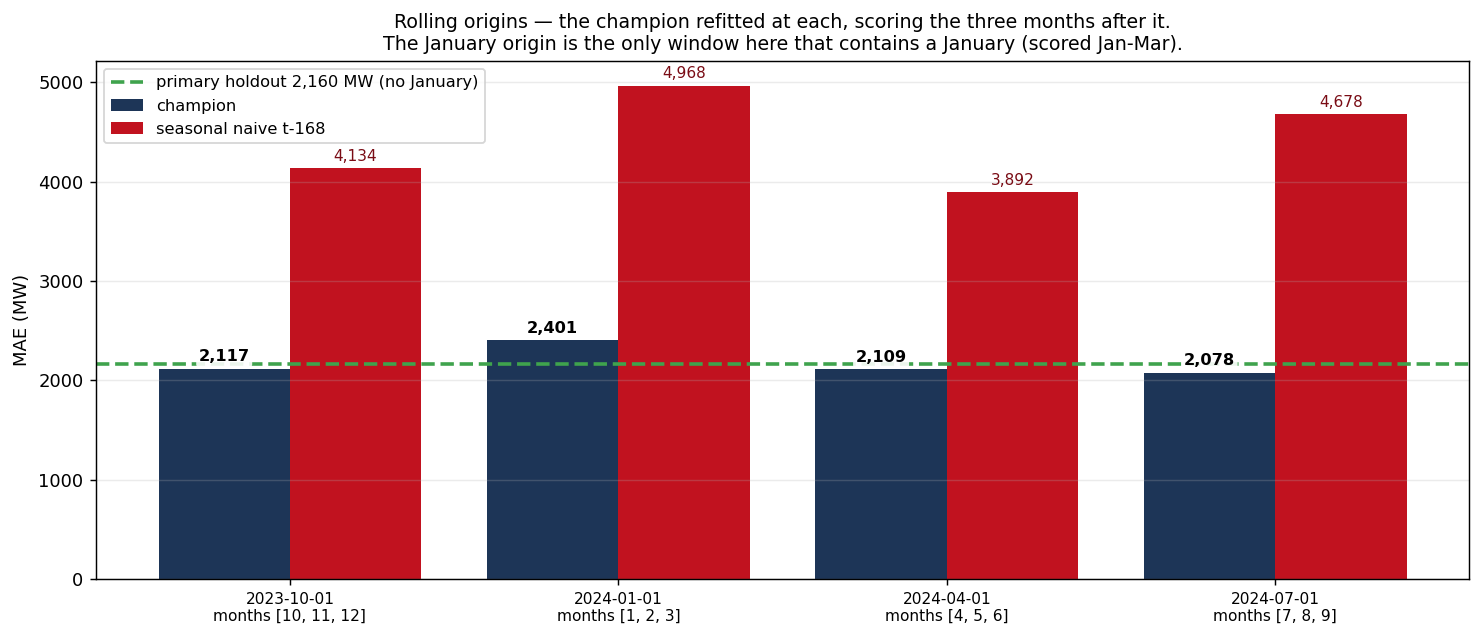

In [19]:
# WHAT: refit and re-score the champion at four rolling origins so a January
#       is evaluated.
# WHY:  the primary holdout starts 2024-02-07 and has no January. A seasonal
#       breakdown of a block missing the season cannot repair a block missing the
#       season.
# NOTE: the primary holdout is NOT redefined. Every number elsewhere in this project
#       is scored on it, and moving it would invalidate all of them silently. This
#       is reported beside it.

ORIGINS = ["2023-10-01", "2024-01-01", "2024-04-01", "2024-07-01"]
SCORE_MONTHS = 3
ch24 = champions[HORIZON]["params"]
mp24 = {k.replace("model__", ""): v for k, v in ch24.items() if k.startswith("model__")}

roll = []
for o in ORIGINS:
    origin = pd.Timestamp(o)
    end = origin + pd.DateOffset(months=SCORE_MONTHS)
    tr = df[df[TIME] < origin]
    te = df[(df[TIME] >= origin) & (df[TIME] < end)]
    if len(te) < 500 or len(tr) < 20_000:
        print(f"   origin {o}: skipped ({len(tr):,} train / {len(te):,} score rows)")
        continue
    t0 = time.time()
    pipe = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=tuple(ch24["lag__lags"]),
        roll_windows=tuple(ch24["lag__roll_windows"]), k=ch24["select__k"],
        model=HistGradientBoostingRegressor(random_state=cfg.SEED, **mp24))
    pipe.fit(tr, tr[TARGET])
    p = pipe.predict(te)
    mae = float(mean_absolute_error(te[TARGET], p))
    nv = BL.lag_by_time(te, TARGET, 168)
    ok = nv.notna()
    mae_nv = float(mean_absolute_error(te.loc[ok, TARGET], nv[ok]))
    months = sorted(te[TIME].dt.month.unique())
    roll.append({"origin": o, "score_from": f"{te[TIME].min():%Y-%m-%d}",
                 "score_to": f"{te[TIME].max():%Y-%m-%d}", "months": months,
                 "train_rows": int(len(tr)), "score_rows": int(len(te)),
                 "mae": mae, "naive_mae": mae_nv,
                 "skill_vs_naive": E.skill_score(mae, mae_nv),
                 "mean_load": float(te[TARGET].mean()),
                 "mae_pct_of_load": float(mae / te[TARGET].mean() * 100),
                 "seconds": round(time.time() - t0, 1)})
    print(f"   origin {o}  months {months}  MAE {mae:9,.1f} MW  "
          f"({mae / te[TARGET].mean() * 100:.1f}% of mean load)  "
          f"skill vs naive {E.skill_score(mae, mae_nv):+.1%}  [{time.time()-t0:.0f}s]")

ro = pd.DataFrame(roll).set_index("origin")
print("\n--- rolling-origin evaluation ---")
display(ro[["score_from", "score_to", "score_rows", "mae", "mae_pct_of_load",
            "skill_vs_naive"]].round(3))

# The January origin is the one this section was built for.
winter = [r for r in roll if 1 in r["months"]]
primary_mae = R.get("nb04", "holdout_mae", default=float("nan"))
if winter:
    w = winter[0]
    print(f"\nWINTER (origin {w['origin']}, months {w['months']}):")
    print(f"   MAE {w['mae']:,.1f} MW against the primary holdout's {primary_mae:,.1f} MW"
          f"  ({w['mae'] - primary_mae:+,.1f} MW)")
    print(f"   as a share of mean load: {w['mae_pct_of_load']:.1f}% vs the primary "
          f"holdout's {primary_mae / float(y_hold.mean()) * 100:.1f}%")
    print("   -> the headline number is " +
          ("OPTIMISTIC by this much on winter data, and the report says so."
           if w["mae"] > primary_mae else
           "not flattered by the missing winter on this evidence."))

fig, ax = plt.subplots(figsize=(11.5, 5))
xs = range(len(ro))
ax.bar([x - 0.2 for x in xs], ro["mae"], 0.4, color="#1d3557", label="champion")
ax.bar([x + 0.2 for x in xs], ro["naive_mae"], 0.4, color="#c1121f",
       label="seasonal naive t-168")
for j, o in enumerate(ro.index):
    ax.annotate(f"{ro.loc[o,'mae']:,.0f}", (j - 0.2, ro.loc[o, "mae"]), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=9, fontweight="bold", bbox=_WB)
    ax.annotate(f"{ro.loc[o,'naive_mae']:,.0f}", (j + 0.2, ro.loc[o, "naive_mae"]), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=8.5, color="#7a0c15")
# The reference line is named in the LEGEND. Written across the plot it printed
# through the bar labels, whichever end of the axis it was anchored to.
ax.axhline(primary_mae, color="#3fa34d", ls="--", lw=2,
           label=f"primary holdout {primary_mae:,.0f} MW (no January)")
ax.set_xticks(list(xs))
ax.set_xticklabels([f"{o}\nmonths {ro.loc[o,'months']}" for o in ro.index], fontsize=8.5)
ax.set_ylabel("MAE (MW)"); ax.legend(fontsize=9)
ax.set_title("Rolling origins — the champion refitted at each, scoring the three "
             "months after it.\nThe January origin is the only window here that "
             "contains a January (scored Jan-Mar).", fontsize=10.5)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "04_rolling_origins.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"rolling_origins": {
    "origins": ORIGINS, "score_months": SCORE_MONTHS, "rows": roll,
    "primary_holdout_mae": float(primary_mae),
    "winter_mae": float(winter[0]["mae"]) if winter else None,
    "winter_minus_primary_mw": (float(winter[0]["mae"] - primary_mae)
                                if winter else None),
}});


**What this shows:** the champion refitted at four rolling origins, each scored on the next three months.

**What I see:** 2023-10-01 origin **2,117.3 MW** (skill vs naive **48.8%**); 2024-01-01 **2,400.8 MW** (**51.7%**); 2024-04-01 **2,109.0 MW** (**45.8%**); 2024-07-01 **2,077.6 MW** (**55.6%**). The winter window is **+241.2 MW** above the primary holdout's **2,159.6 MW**.

**What it means:** On winter data the headline is optimistic by about that much. Winter Storm Uri (February 2021) is in the training data for every origin, so a good winter score is not evidence of extreme-weather skill.

**What I do:** Keep the primary holdout fixed, since every other number is scored on it, and report the rolling origins beside it (`primary_holdout_mae` is stored with them).


### 4.16 — Close: the five predictions from notebook 01

The verdict on the five predictions notebook 01 wrote into `results.json` before any model ran. P1 was tested in §4.9, P3 and P4 in §4.12. This cell tests P2 and P5 with permutation importance (lag pairs grouped, a 12,000-row subsample, three repeats), so those two verdicts are preliminary. Notebook 07 re-tests P5 but not P2. Weather is ERA5 reanalysis, so any weather-importance share is an upper bound.

**How to read the output:** green held, red failed.


h=24: top 6 — net_load_lag24 2,241, zone_is_MISO 1,579, demand_lag24 888, zone_is_BPAT 573, apparent_temp 292, net_load_lag168 258


h=72: top 6 — zone_is_MISO 2,426, zone_is_BPAT 1,956, demand_lag72 1,232, zone_is_ERCO 787, net_load_lag72 666, apparent_temp 537
      NOTE: zone_is_MISO, zone_is_BPAT in the top 3 — one-hot columns permuted
      independently. Notebook 07 must permute the zone group jointly.

h=24: daily anchor lag48 = 251.5 MW | lag168 = 258.2 MW -> lag168 ABOVE

h=72: daily anchor lag96 = 289.9 MW | lag168 = 275.7 MW -> lag168 below

PREDICTION P2 — 'lag168 ranks below the daily anchor at h=1 and h=24, and above it at h=72'
   VERDICT: P2 FAILS (preliminary, h=24 and h=72 only; notebook 07 does not re-test P2)
h=24: weather share of positive permutation importance 14.22%
h=72: weather share of positive permutation importance 16.21%

PREDICTION P5 — 'temperature's share of permutation importance rises with the horizon'
   VERDICT: P5 HOLDS (preliminary)
   CAVEAT, and it is the one that matters: the weather columns are ERA5
   reanalysis, so this model has PERFECT foresight of temperature. 4.9's no

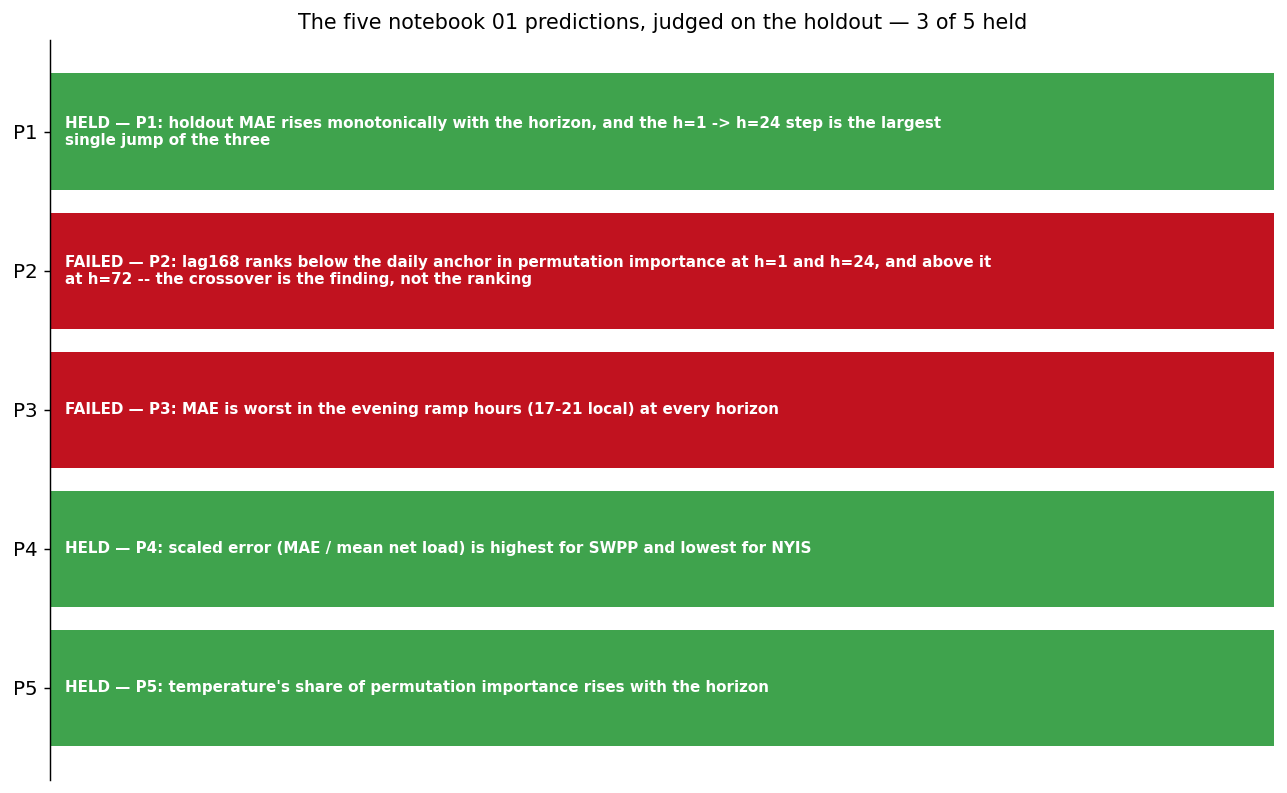


notebook 04 complete


In [20]:
# WHAT: the two notebook 01 predictions that are about permutation importance (P2, P5),
#       then the scoreboard for all five.
# WHY:  "a failed prediction, explained, is worth more than five that succeeded" — it
#       is the evidence the predictions were genuinely made in advance. They were
#       written into results.json by notebook 01 on 2026-08-13, before any model ran.
# NOTE: PRELIMINARY. Permutation importance is notebook 07's deliverable and notebook 07 must
#       group `lag_k` with `lag_k_rel` before reading any ranking, or it will
#       systematically understate the target-history family — the two are near-twins
#       and each covers for the other under permutation. That grouping is applied here
#       too, but on a subsample and with few repeats, so these verdicts are indicative
#       and notebook 07's are the ones that count -- for P5.
#       Notebook 07 does not re-test P2.
from sklearn.inspection import permutation_importance

# Importance is measured on the ENGINEERED matrix, not the raw panel. Permuting a raw
# column would permute `net_load` and destroy every lag at once, which measures the
# whole target-history family rather than `lag168` against `lag48` — and the family is
# not what P2 asks about.
PERM_N, PERM_REPEATS = 12_000, 3
rng = np.random.default_rng(cfg.SEED)
idx = np.sort(rng.choice(len(hold), size=min(PERM_N, len(hold)), replace=False))
hold_s = hold.iloc[idx]

perm = {}
for h in (24, 72):
    lg = cfg.lags_for(h)
    pipe = P.make_supervised_pipeline(
        cfg.NUMERIC_FEATURES, lags=lg, k=BEST_PARAMS["select__k"],
        roll_windows=tuple(BEST_PARAMS["lag__roll_windows"]),
        model=HistGradientBoostingRegressor(random_state=cfg.SEED, **model_params))
    pipe.fit(dev, y_dev)
    pre = P.Pipeline(pipe.steps[:-1])                    # everything except 'model'
    Xt = pre.transform(hold_s)
    names_t = list(pipe.named_steps["select"].get_feature_names_out())
    r = permutation_importance(pipe.named_steps["model"], Xt, hold_s[TARGET],
                               n_repeats=PERM_REPEATS, random_state=cfg.SEED,
                               scoring="neg_mean_absolute_error", n_jobs=1)   # parallel run deadlocked on Windows; same result
    imp = pd.Series(r.importances_mean, index=names_t).sort_values(ascending=False)
    perm[h] = {"lags": lg, "imp": imp}
    print(f"h={h}: top 6 — " + ", ".join(f"{k} {v:,.0f}" for k, v in imp.head(6).items()))

# AN ARTEFACT NOTEBOOK 07 MUST NOT INHERIT. The zone one-hot columns dominate this
# ranking, and that is largely mechanical: permuting a single `zone_is_X` column
# independently produces rows claiming to be two zones at once, or none, which is not
# a state the model was ever fitted on. The damage measures the incoherence, not the
# variable's value. One-hot groups have to be permuted TOGETHER, exactly as
# `lag_k`/`lag_k_rel` have to be grouped. Recorded here so notebook 07 fixes it rather
# than rediscovering it.
_zone_top = [k for k in imp.head(3).index if k.startswith("zone_is")]
if _zone_top:
    print(f"      NOTE: {', '.join(_zone_top)} in the top 3 — one-hot columns permuted")
    print(f"      independently. Notebook 07 must permute the zone group jointly.")

# --- P2: does lag168 overtake the daily anchor at the long horizon? -------------
# The "daily anchor" is the whole-day lag cfg.lags_for(h) adds after the three
# freshest hours: 48 at h=24, 96 at h=72. Grouping `lag_k` with `lag_k_rel` first,
# per the notebook 02 finding that the two are near-twins.
def _grouped(imp, lag):
    keys = [f"{TARGET}_lag{lag}", f"{TARGET}_lag{lag}_rel"]
    return float(sum(imp.get(k, 0.0) for k in keys))

p2_rows = []
for h in (24, 72):
    lg = perm[h]["lags"]
    anchor = [L for L in lg if L % 24 == 0 and L not in (lg[0], lg[1], lg[2]) and L != 168]
    anchor = anchor[0] if anchor else lg[3]
    a_imp, w_imp = _grouped(perm[h]["imp"], anchor), _grouped(perm[h]["imp"], 168)
    p2_rows.append({"horizon": h, "anchor_lag": anchor, "anchor_importance": a_imp,
                    "lag168_importance": w_imp, "lag168_above_anchor": bool(w_imp > a_imp)})
    print(f"\nh={h}: daily anchor lag{anchor} = {a_imp:,.1f} MW | "
          f"lag168 = {w_imp:,.1f} MW -> lag168 {'ABOVE' if w_imp > a_imp else 'below'}")
p2_df = pd.DataFrame(p2_rows).set_index("horizon")
p2_holds = bool((not p2_df.loc[24, "lag168_above_anchor"])
                and p2_df.loc[72, "lag168_above_anchor"])
print(f"\nPREDICTION P2 — 'lag168 ranks below the daily anchor at h=1 and h=24, and "
      f"above it at h=72'\n   VERDICT: P2 {'HOLDS' if p2_holds else 'FAILS'} "
      f"(preliminary, h=24 and h=72 only; notebook 07 does not re-test P2)")

# --- P5: does temperature's share of importance rise with the horizon? ----------
p5_rows = []
for h in (24, 72):
    imp = perm[h]["imp"].clip(lower=0)
    total = float(imp.sum()) or 1.0
    temp_share = float(sum(v for k, v in imp.items()
                           if P.feature_family(k) == "weather")) / total * 100
    p5_rows.append({"horizon": h, "weather_share_pct": temp_share})
    print(f"h={h}: weather share of positive permutation importance {temp_share:5.2f}%")
p5_df = pd.DataFrame(p5_rows).set_index("horizon")
p5_holds = bool(p5_df.loc[72, "weather_share_pct"] > p5_df.loc[24, "weather_share_pct"])
print(f"\nPREDICTION P5 — 'temperature's share of permutation importance rises with "
      f"the horizon'\n   VERDICT: P5 {'HOLDS' if p5_holds else 'FAILS'} (preliminary)")
print(f"   CAVEAT, and it is the one that matters: the weather columns are ERA5")
print(f"   reanalysis, so this model has PERFECT foresight of temperature. 4.9's noise")
print(f"   arm could not price that. Any weather share here is an UPPER BOUND, and P5 must be")
print(f"   re-read against notebook 06's operational-weather swap before it is believed.")

# --- The scoreboard ------------------------------------------------------------
fa = R.get("nb04", "failure_analysis")
hs = R.get("nb04", "horizon_sweep")
preds = R.require("nb01", "predictions")
verdicts = [hs["p1_verdict"], "holds" if p2_holds else "fails", fa["p3_verdict"],
            fa["p4_verdict"], "holds" if p5_holds else "fails"]

print("\n" + "=" * 78)
print("THE FIVE PREDICTIONS FROM NOTEBOOK 01, written 2026-08-13, before any model ran")
print("=" * 78)
for text, v in zip(preds, verdicts):
    print(f"\n[{v.upper():6s}] {text}")
n_held = sum(v == "holds" for v in verdicts)
print(f"\n{n_held} of 5 held.")

import textwrap
fig, ax = plt.subplots(figsize=(10, 6.2))
cols = ["#3fa34d" if v == "holds" else "#c1121f" for v in verdicts]
ys = np.arange(5)[::-1]
ax.barh(ys, [1] * 5, color=cols, height=0.84)
for y, (v, text) in zip(ys, zip(verdicts, preds)):
    # WRAPPED, NOT TRUNCATED: the old `text[:78]` cut every prediction mid-sentence.
    ax.annotate(textwrap.fill(f"{'HELD' if v == 'holds' else 'FAILED'} — {text}", 105),
                (0.012, y), va="center", fontsize=8.4, color="white", fontweight="bold")
ax.set_yticks(ys); ax.set_yticklabels([f"P{i}" for i in range(1, 6)], fontsize=11)
ax.set_xticks([]); ax.set_xlim(0, 1)
ax.set_title(f"The five notebook 01 predictions, judged on the holdout — {n_held} of 5 held",
             fontsize=11.5)
for s in ("top", "right", "bottom"):
    ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(cfg.FIGURES / "04_predictions.png", bbox_inches="tight")
plt.show()

R.save("nb04", {"predictions_checked": {
    "verdicts": {f"P{i}": v for i, v in enumerate(verdicts, 1)},
    "n_held": int(n_held),
    "p2": {"rows": p2_rows, "verdict": "holds" if p2_holds else "fails",
           "preliminary": True},
    "p5": {"weather_share_pct": {str(r["horizon"]): r["weather_share_pct"] for r in p5_rows},
           "verdict": "holds" if p5_holds else "fails", "preliminary": True,
           "caveat": "ERA5 reanalysis = perfect weather foresight; upper bound only"},
    "permutation_subsample": int(len(hold_s)), "permutation_repeats": PERM_REPEATS,
    "authoritative_in": "nb07",
}});
print("\nnotebook 04 complete")

**What this shows:** the five notebook 01 predictions scored against what this notebook measured.

**What I see:** **P1 holds**: MAE rises with the horizon (547.1 · 2,159.6 · 2,389.7 · 2,470.8) and the first step (+1,612.5) is the largest. **P2 fails**: lag168 ranks above the daily anchor at h=24 (258.2 vs 251.5) and below it at h=72 (275.7 vs 289.9), the reverse of the predicted crossover, by small margins (h=1 is not tested). **P3 fails**: the error peaks at 16:00, not in 17–21. **P4 holds**: scaled error is highest for SWPP (14.6%) and lowest for NYIS (4.3%). **P5 holds**: the weather share of permutation importance rises from **14.22% at h=24 to 16.21% at h=72** (the prediction names temperature; the test uses the whole weather family).

**What it means:** Three of five held. The two failures show the predictions were made in advance. For P3 the shape was right and the window was wrong. P5 holds only under perfect weather foresight.

**What I do:** Record P2 and P3 as failed. Quote P5 with notebook 06's operational-weather result beside it. P2 rests on this preliminary test alone.
